Cell 1 — Cài đặt thư viện

**Research Upgrade 3.0:** fixed 91-day reference population for window comparisons; observed reference-horizon Recency with window-specific Frequency/Monetary; overlap-aware temporal ARI; persistence hysteresis; quality/stability policy sensitivity; null-calibrated Page-Hinkley with held-out synthetic scenarios; moving-block bootstrap confidence intervals and paired effect sizes; deterministic thread limits and reproducibility manifests.


In [1]:
!pip -q install pandas numpy scikit-learn scipy matplotlib seaborn openpyxl psutil gradio

Cell 2 — Import thư viện và cấu hình

In [2]:
import os
import time
import math
import warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

from scipy.optimize import linear_sum_assignment
from threadpoolctl import threadpool_limits, threadpool_info

warnings.filterwarnings("ignore")

# Reproducibility
RUN_STARTED_AT_UTC = datetime.now(timezone.utc).isoformat()
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Limit BLAS/OpenMP worker threads to reduce run-to-run numerical variation.
THREADPOOL_CONTROLLER = threadpool_limits(limits=1)
DETERMINISTIC_THREAD_LIMIT = 1

# ==========================================
# DATA CONFIGURATION
# ==========================================
DATA_PATH = "/content/online_retail_II.xlsx"

# ==========================================
# RFM CONFIGURATION
# ==========================================
WINDOWS = [28, 56, 91]
SNAPSHOT_STRIDE = 28

# ==========================================
# CLUSTERING CONFIGURATION
# ==========================================
K_MIN = 2
K_MAX = 8
MIN_CLUSTER_FRACTION = 0.01
MAX_SILHOUETTE_SAMPLE = 5000

# ==========================================
# ADAPTIVE WINDOW CONFIGURATION
# ==========================================
QUALITY_WEIGHT = 0.80
STABILITY_WEIGHT = 0.20

HYSTERESIS_MARGIN = 0.01
HYSTERESIS_CONFIRMATIONS = 2

REFERENCE_COHORT_WINDOW = max(WINDOWS)

WINDOW_SILHOUETTE_WEIGHT = 0.65
WINDOW_DBI_WEIGHT = 0.35
if not np.isclose(WINDOW_SILHOUETTE_WEIGHT + WINDOW_DBI_WEIGHT, 1.0):
    raise ValueError("Window quality weights must sum to 1.")

STABILITY_FULL_OVERLAP_FRACTION = 1.0
STABILITY_MIN_OVERLAP_FRACTION = 0.20

# ==========================================
# OUTPUT
# ==========================================
OUTPUT_DIR = Path("/content/adaptive_rolling_dynamic_rfm_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration initialized.")

Configuration initialized.


Cell 3 — Upload và đọc Online Retail II

In [3]:
# ============================================================
# CELL 3 - LOAD ONLINE RETAIL II & SCHEMA AUDIT (BẢNG 2.1)
# Automatically uses existing local file if present before prompting upload
# ============================================================
import zipfile
from pathlib import Path
import pandas as pd


def resolve_or_upload_dataset(default_path=DATA_PATH):
    candidate_paths = [
        Path(default_path),
        Path("/content/online_retail_II.xlsx"),
        Path("/content/online_retail_II.csv"),
        Path("/content/online_retail_II.zip"),
        Path("online_retail_II.xlsx"),
        Path("online_retail_II.csv"),
        Path("online_retail_II.zip")
    ]
    for p in candidate_paths:
        if p.exists() and p.is_file():
            print(f"Found existing dataset file: {p}")
            return p

    try:
        from google.colab import files
        print("Please upload Online Retail II ZIP/XLSX/CSV.")
        uploaded = files.upload()
        if not uploaded:
            raise ValueError("No file uploaded.")
        filename = next(iter(uploaded.keys()))
        return Path("/content") / filename
    except ImportError:
        raise FileNotFoundError(
            "Dataset not found locally and not running on Google Colab. "
            "Place 'online_retail_II.xlsx' or '.csv' in the working directory."
        )


def extract_zip_file(zip_path):
    extract_dir = Path("/content/online_retail_ii_extracted")
    extract_dir.mkdir(parents=True, exist_ok=True)
    print("Extracting ZIP file...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Extraction completed.")
    return extract_dir


def load_retail_dataset(path):
    path = Path(path)
    if path.suffix.lower() == ".zip":
        extract_dir = extract_zip_file(path)
        files_found = []
        for extension in ["*.xlsx", "*.xls", "*.csv"]:
            files_found.extend(extract_dir.rglob(extension))
        if not files_found:
            raise FileNotFoundError("No XLSX, XLS or CSV file found inside ZIP.")
        excel_files = [f for f in files_found if f.suffix.lower() in [".xlsx", ".xls"]]
        csv_files = [f for f in files_found if f.suffix.lower() == ".csv"]
        path = excel_files[0] if excel_files else csv_files[0]
        print("Selected extracted file:", path.name)

    if path.suffix.lower() in [".xlsx", ".xls"]:
        excel = pd.ExcelFile(path)
        frames = []
        for sheet in excel.sheet_names:
            print("Reading sheet:", sheet)
            frames.append(pd.read_excel(path, sheet_name=sheet))
        data = pd.concat(frames, ignore_index=True)
    elif path.suffix.lower() == ".csv":
        data = pd.read_csv(path, encoding="latin1", low_memory=False)
    else:
        raise ValueError(f"Unsupported file format: {path.suffix}")
    return data


dataset_path = resolve_or_upload_dataset(DATA_PATH)
raw_df = load_retail_dataset(dataset_path)

print("\n" + "=" * 60)
print("ONLINE RETAIL II DATASET - RAW OVERVIEW")
print("=" * 60)
print("Rows:", f"{len(raw_df):,}")
print("Columns:", len(raw_df.columns))
print("Column names:", raw_df.columns.tolist())
display(raw_df.head())

# Bảng 2.1: Mô tả các thuộc tính của Online Retail II
schema_descriptions = {
    "invoice": ("Invoice", "Mã hóa đơn; bắt đầu bằng 'C' là hóa đơn hủy"),
    "invoiceno": ("Invoice", "Mã hóa đơn; bắt đầu bằng 'C' là hóa đơn hủy"),
    "stockcode": ("StockCode", "Mã định danh sản phẩm"),
    "description": ("Description", "Tên / mô tả sản phẩm"),
    "quantity": ("Quantity", "Số lượng sản phẩm trên mỗi dòng giao dịch"),
    "invoicedate": ("InvoiceDate", "Thời điểm phát sinh giao dịch"),
    "invoice date": ("InvoiceDate", "Thời điểm phát sinh giao dịch"),
    "price": ("Price", "Đơn giá sản phẩm (Bảng Anh - GBP)"),
    "unitprice": ("Price", "Đơn giá sản phẩm (Bảng Anh - GBP)"),
    "unit price": ("Price", "Đơn giá sản phẩm (Bảng Anh - GBP)"),
    "customer id": ("CustomerID", "Mã định danh duy nhất của khách hàng"),
    "customerid": ("CustomerID", "Mã định danh duy nhất của khách hàng"),
    "country": ("Country", "Quốc gia nơi khách hàng cư trú")
}

schema_rows = []
for col in raw_df.columns:
    key = str(col).strip().lower()
    std_name, desc = schema_descriptions.get(key, (str(col), "Thuộc tính bổ sung"))
    schema_rows.append({
        "raw_column": str(col),
        "standardized_name": std_name,
        "dtype": str(raw_df[col].dtype),
        "non_null_count": int(raw_df[col].notna().sum()),
        "null_count": int(raw_df[col].isna().sum()),
        "description": desc
    })
dataset_schema_df = pd.DataFrame(schema_rows)
print("\n--- BẢNG 2.1: MÔ TẢ CÁC THUỘC TÍNH CỦA ONLINE RETAIL II ---")
display(dataset_schema_df)

Please upload Online Retail II ZIP/XLSX/CSV.


Saving online+retail+ii.zip to online+retail+ii.zip
Extracting ZIP file...
Extraction completed.
Selected extracted file: online_retail_II.xlsx
Reading sheet: Year 2009-2010
Reading sheet: Year 2010-2011

ONLINE RETAIL II DATASET - RAW OVERVIEW
Rows: 1,067,371
Columns: 8
Column names: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



--- BẢNG 2.1: MÔ TẢ CÁC THUỘC TÍNH CỦA ONLINE RETAIL II ---


,raw_column,standardized_name,dtype,non_null_count,null_count,description
0,Invoice,Invoice,object,1067371,0,Mã hóa đơn; bắt đầu bằng 'C' là hóa đơn hủy
1,StockCode,StockCode,object,1067371,0,Mã định danh sản phẩm
2,Description,Description,object,1062989,4382,Tên / mô tả sản phẩm
3,Quantity,Quantity,int64,1067371,0,Số lượng sản phẩm trên mỗi dòng giao dịch
4,InvoiceDate,InvoiceDate,datetime64[ns],1067371,0,Thời điểm phát sinh giao dịch
5,Price,Price,float64,1067371,0,Đơn giá sản phẩm (Bảng Anh - GBP)
6,Customer ID,CustomerID,float64,824364,243007,Mã định danh duy nhất của khách hàng
7,Country,Country,object,1067371,0,Quốc gia nơi khách hàng cư trú


Cell 4 — Data preprocessing

In [4]:
# ============================================================
# CELL 4 - DATA PREPROCESSING & SEQUENTIAL MISSINGNESS AUDIT
# ============================================================

def normalize_columns(data):
    df = data.copy()
    column_mapping = {}
    for col in df.columns:
        normalized = str(col).strip().lower()
        if normalized in ["invoice", "invoiceno"]:
            column_mapping[col] = "Invoice"
        elif normalized == "quantity":
            column_mapping[col] = "Quantity"
        elif normalized in ["invoicedate", "invoice date"]:
            column_mapping[col] = "InvoiceDate"
        elif normalized in ["price", "unitprice", "unit price"]:
            column_mapping[col] = "Price"
        elif normalized in ["customer id", "customerid"]:
            column_mapping[col] = "CustomerID"
        elif normalized == "stockcode":
            column_mapping[col] = "StockCode"
        elif normalized == "description":
            column_mapping[col] = "Description"
        elif normalized == "country":
            column_mapping[col] = "Country"
    return df.rename(columns=column_mapping)


def preprocess_retail_data(raw):
    df = normalize_columns(raw)
    required_columns = ["Invoice", "Quantity", "InvoiceDate", "Price", "CustomerID"]
    missing = [col for col in required_columns if col not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    rows_before = len(df)

    # 1. Missingness audit per attribute BEFORE string conversion
    missing_audit_rows = []
    for col in df.columns:
        n_miss = int(df[col].isna().sum())
        missing_audit_rows.append({
            "column": col,
            "missing_count": n_miss,
            "missing_rate_pct": round((n_miss / rows_before) * 100.0, 4),
            "is_required_rfm": bool(col in required_columns)
        })
    missing_audit_df = pd.DataFrame(missing_audit_rows)

    # 2. Sequential non-overlapping filtering audit
    audit_steps = [{
        "step": "Raw data",
        "condition": "Tập gốc UCI Online Retail II",
        "rows_before": rows_before,
        "rows_removed": 0,
        "rows_after": rows_before
    }]

    # Convert types carefully without turning NaN into string "nan"
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
    df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
    df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
    df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")
    df["Invoice"] = df["Invoice"].where(df["Invoice"].isna(), df["Invoice"].astype(str).str.strip())
    df.loc[df["Invoice"] == "", "Invoice"] = np.nan

    # Step A: Remove missing values in required columns
    b_step = len(df)
    df = df.dropna(subset=required_columns).copy()
    a_step = len(df)
    audit_steps.append({
        "step": "Missing audit",
        "condition": "Thiếu trường bắt buộc (Invoice, InvoiceDate, Quantity, Price, CustomerID)",
        "rows_before": b_step,
        "rows_removed": b_step - a_step,
        "rows_after": a_step
    })

    # Step B: Remove cancelled invoices
    b_step = len(df)
    cancelled_mask = df["Invoice"].str.upper().str.startswith("C")
    df = df[~cancelled_mask].copy()
    a_step = len(df)
    audit_steps.append({
        "step": "Cancelled invoices",
        "condition": "Invoice bắt đầu bằng ký tự C",
        "rows_before": b_step,
        "rows_removed": b_step - a_step,
        "rows_after": a_step
    })

    # Step C: Valid positive purchases only
    b_step = len(df)
    df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()
    a_step = len(df)
    audit_steps.append({
        "step": "Invalid purchase",
        "condition": "Quantity <= 0 hoặc Price <= 0",
        "rows_before": b_step,
        "rows_removed": b_step - a_step,
        "rows_after": a_step
    })

    # Step D: Remove exact duplicate records only
    b_step = len(df)
    df = df.drop_duplicates().copy()
    a_step = len(df)
    audit_steps.append({
        "step": "Exact duplicates",
        "condition": "Bản ghi trùng hoàn toàn trên mọi cột",
        "rows_before": b_step,
        "rows_removed": b_step - a_step,
        "rows_after": a_step
    })

    df["CustomerID"] = df["CustomerID"].astype("int64")
    df["Amount"] = df["Quantity"] * df["Price"]
    df = df.sort_values("InvoiceDate").reset_index(drop=True)

    audit_steps.append({
        "step": "Final dataset",
        "condition": "Dữ liệu hợp lệ sau tiền xử lý",
        "rows_before": rows_before,
        "rows_removed": rows_before - len(df),
        "rows_after": len(df)
    })
    preprocessing_audit_df = pd.DataFrame(audit_steps)
    preprocessing_audit_df["removed_pct_of_raw"] = (
        preprocessing_audit_df["rows_removed"] / rows_before * 100.0
    ).round(4)

    print("Rows before preprocessing:", f"{rows_before:,}")
    print("Rows after preprocessing:", f"{len(df):,}")
    print("Removed rows:", f"{rows_before - len(df):,}")
    print("Unique customers:", f"{df['CustomerID'].nunique():,}")
    print("Unique invoices:", f"{df['Invoice'].nunique():,}")
    print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
    print("Total revenue:", f"{df['Amount'].sum():,.2f}")

    print("\n--- BẢNG 2.3: TỶ LỆ THIẾU THEO TỪNG THUỘC TÍNH ---")
    display(missing_audit_df)
    print("\n--- BẢNG 2.2: NHẬT KÝ TIỀN XỬ LÝ TUẦN TỰ ---")
    display(preprocessing_audit_df)

    return df, missing_audit_df, preprocessing_audit_df


df, missing_audit_df, preprocessing_audit_df = preprocess_retail_data(raw_df)
display(df.head())

Rows before preprocessing: 1,067,371
Rows after preprocessing: 779,425
Removed rows: 287,946
Unique customers: 5,878
Unique invoices: 36,969
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Total revenue: 17,374,804.27

--- BẢNG 2.3: TỶ LỆ THIẾU THEO TỪNG THUỘC TÍNH ---


,column,missing_count,missing_rate_pct,is_required_rfm
0,Invoice,0,0.0000,True
1,StockCode,0,0.0000,False
2,Description,4382,0.4105,False
3,Quantity,0,0.0000,True
4,InvoiceDate,0,0.0000,True
5,Price,0,0.0000,True
6,CustomerID,243007,22.7669,True
7,Country,0,0.0000,False



--- BẢNG 2.2: NHẬT KÝ TIỀN XỬ LÝ TUẦN TỰ ---


,step,condition,rows_before,rows_removed,rows_after,removed_pct_of_raw
0,Raw data,Tập gốc UCI Online Retail II,1067371,0,1067371,0.0000
1,Missing audit,"Thiếu trường bắt buộc (Invoice, InvoiceDate, Q...",1067371,243007,824364,22.7669
2,Cancelled invoices,Invoice bắt đầu bằng ký tự C,824364,18744,805620,1.7561
3,Invalid purchase,Quantity <= 0 hoặc Price <= 0,805620,71,805549,0.0067
4,Exact duplicates,Bản ghi trùng hoàn toàn trên mọi cột,805549,26124,779425,2.4475
5,Final dataset,Dữ liệu hợp lệ sau tiền xử lý,1067371,287946,779425,26.9771


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,Amount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


--- BẢNG 2.4: THỐNG KÊ MÔ TẢ CÁC BIẾN GIAO DỊCH ---


,variable,n,mean,sd,se,min,p25,median_p50,p75,p90,p95,p99,max,skewness,kurtosis
0,Quantity,779425,13.4894,145.8558,0.1652,1.000,2.00,6.00,12.00,24.00,36.0,144.00,80995.0,401.1168,208834.2491
1,UnitPrice (Price),779425,3.2185,29.6761,0.0336,0.001,1.25,1.95,3.75,6.75,8.5,14.95,10953.5,240.5460,71986.7278
2,Amount,779425,22.2918,227.4271,0.2576,0.001,4.95,12.48,19.80,35.70,67.5,203.52,168469.6,579.5739,404277.3772



--- BẢNG 2.5: THỐNG KÊ PHÂN PHỐI RFM CẤP KHÁCH HÀNG ---


,variable,n,mean,sd,se,min,p25,median_p50,p75,p90,p95,p99,max,skewness,kurtosis
0,Recency (days),5878,200.8542,209.3511,2.7306,0.00,25.0547,95.0354,379.1009,534.3302,624.9125,725.8729,738.1215,0.8870,-0.4775
1,Frequency (unique invoices),5878,6.2894,13.0094,0.1697,1.00,1.0000,3.0000,7.0000,13.0000,21.0000,46.0000,398.0000,12.6367,266.5015
2,Monetary (total spend),5878,2955.9041,14440.8527,188.3554,2.95,342.2800,867.7400,2248.3050,5465.7410,9374.2270,29205.9010,580987.0400,25.0638,829.4607



--- PHÂN TÍCH PARETO DOANH THU THEO KHÁCH HÀNG ---


,top_customer_share_pct,cumulative_revenue_share_pct
0,10.0,63.8952
1,20.0,77.2317
2,50.0,93.5738


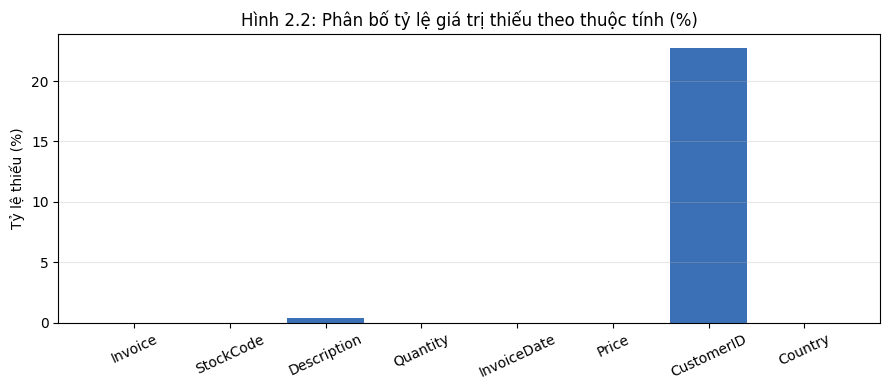

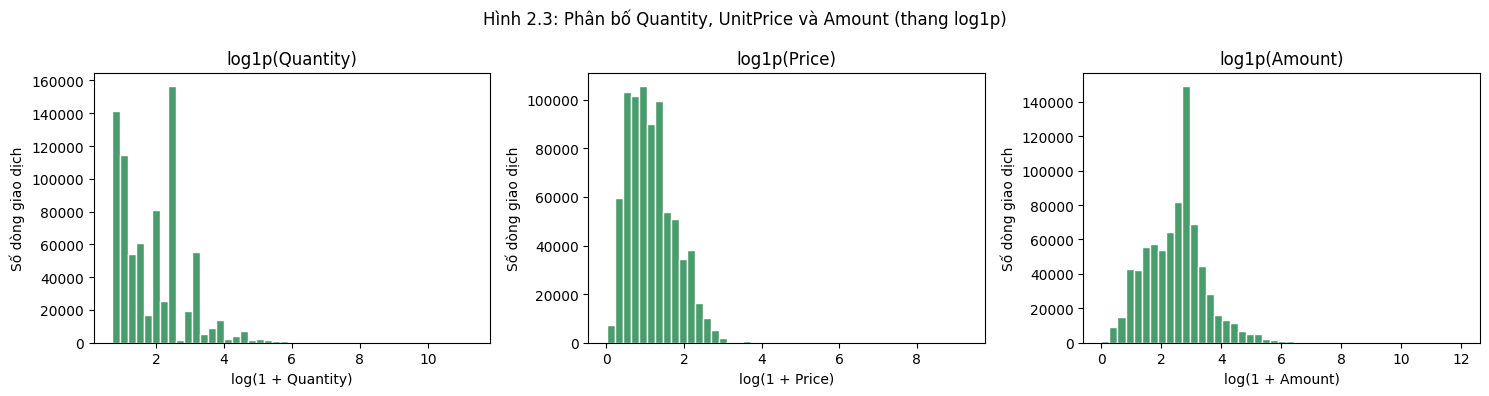

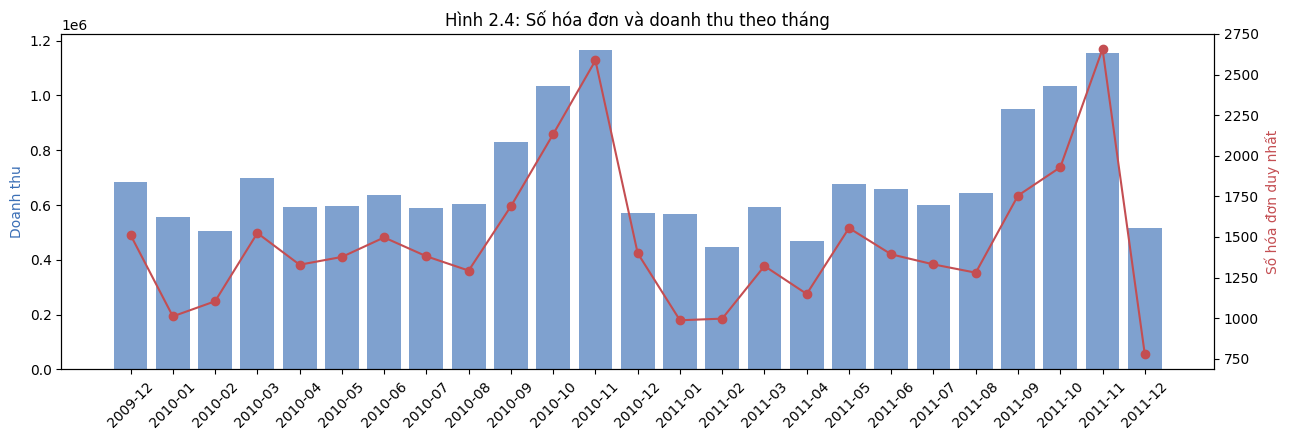

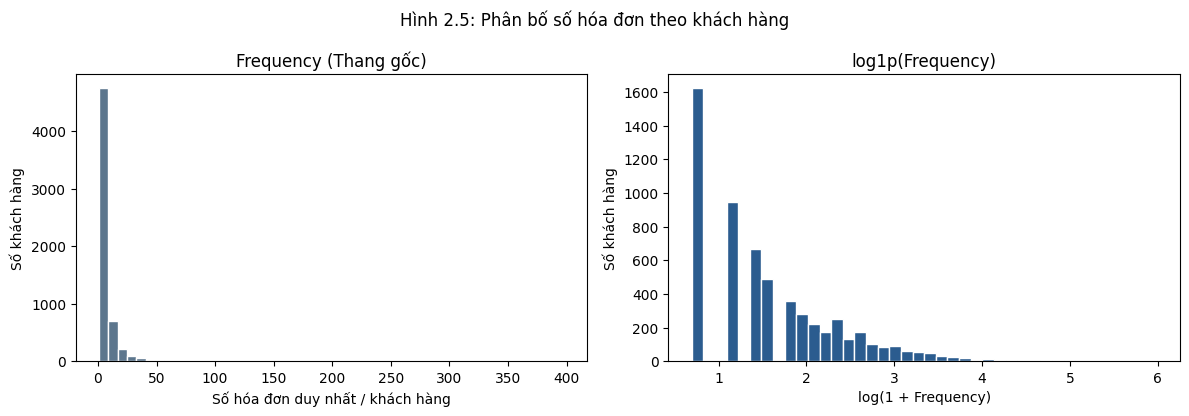

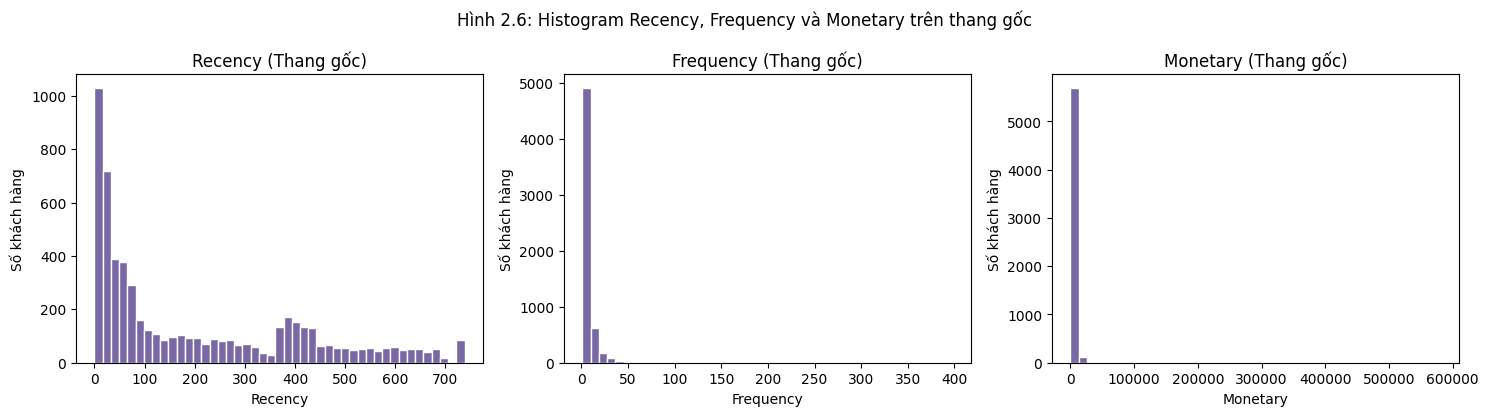

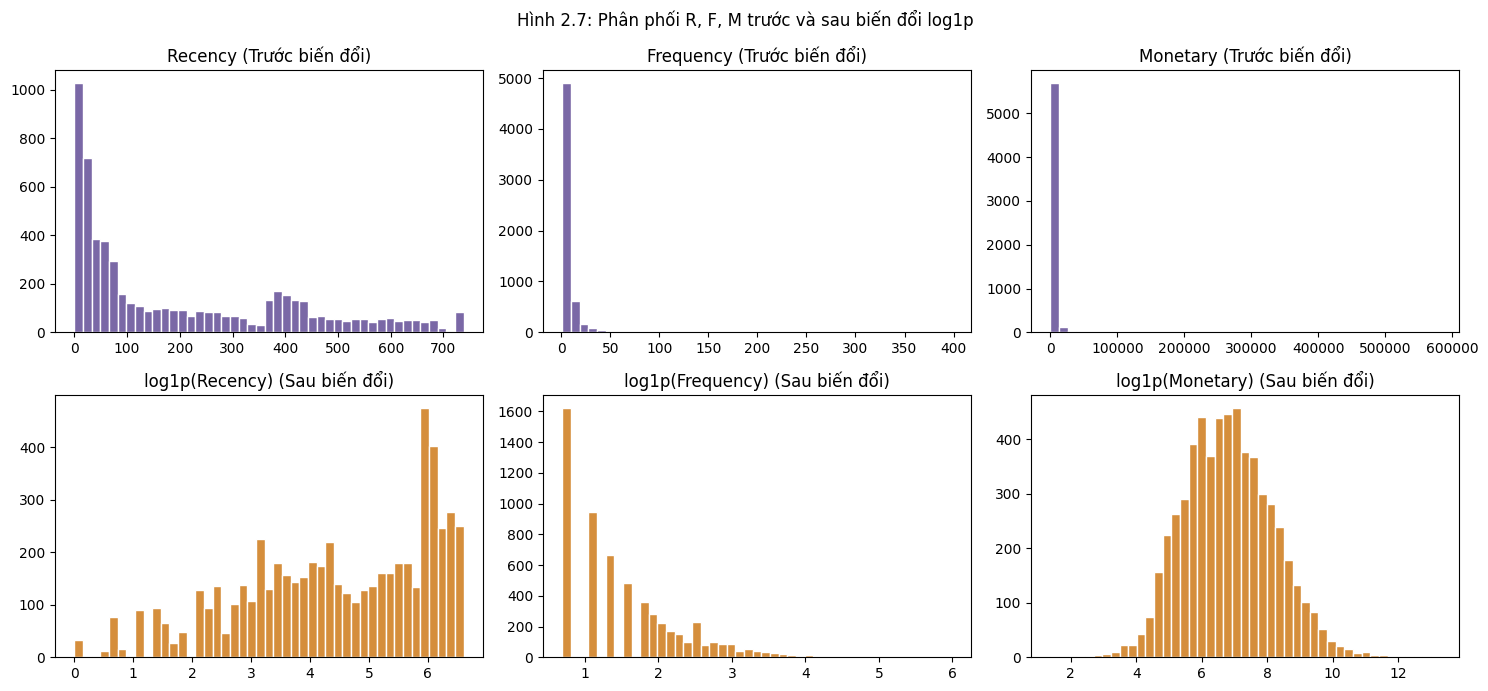

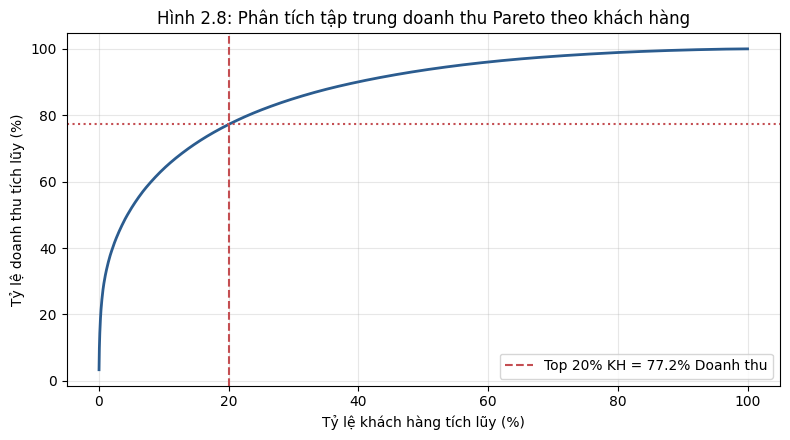

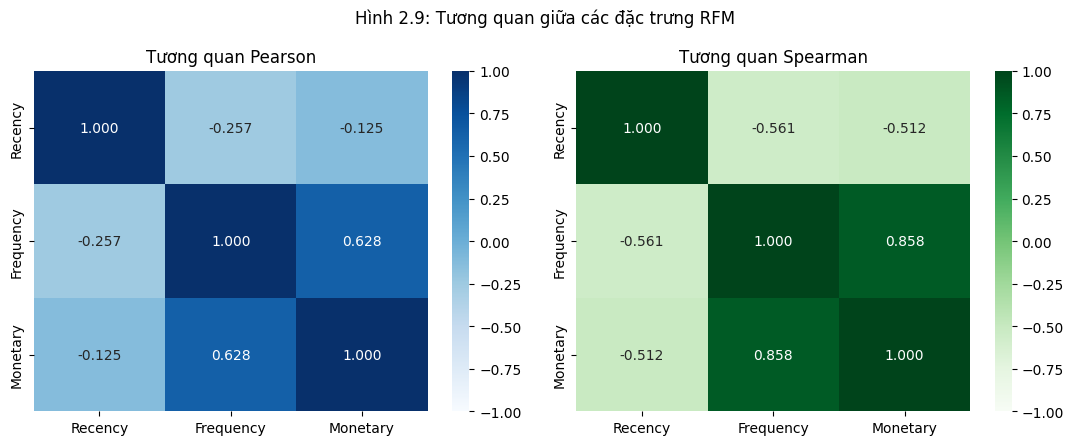

In [5]:
# ============================================================
# CELL 4B - EXPLORATORY DATA ANALYSIS (EDA) & PARETO AUDIT
# Generates Tables 2.4, 2.5 and Figures 2.2 - 2.9 individually
# ============================================================
from scipy.stats import skew, kurtosis

EDA_PLOT_DIR = Path(OUTPUT_DIR) / "eda_figures"
EDA_PLOT_DIR.mkdir(parents=True, exist_ok=True)


def compute_descriptive_stats(series, label):
    s = pd.to_numeric(series, errors="coerce").dropna()
    return {
        "variable": label,
        "n": int(len(s)),
        "mean": float(s.mean()),
        "sd": float(s.std(ddof=1)),
        "se": float(s.std(ddof=1) / np.sqrt(max(1, len(s)))),
        "min": float(s.min()),
        "p25": float(s.quantile(0.25)),
        "median_p50": float(s.median()),
        "p75": float(s.quantile(0.75)),
        "p90": float(s.quantile(0.90)),
        "p95": float(s.quantile(0.95)),
        "p99": float(s.quantile(0.99)),
        "max": float(s.max()),
        "skewness": float(skew(s)),
        "kurtosis": float(kurtosis(s))
    }


eda_transaction_stats = pd.DataFrame([
    compute_descriptive_stats(df["Quantity"], "Quantity"),
    compute_descriptive_stats(df["Price"], "UnitPrice (Price)"),
    compute_descriptive_stats(df["Amount"], "Amount")
])

max_date_eda = df["InvoiceDate"].max()
customer_lifetime_eda = df.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("Amount", "sum")
)
customer_lifetime_eda["Recency"] = (
    max_date_eda - customer_lifetime_eda["LastPurchase"]
).dt.total_seconds() / 86400.0

eda_rfm_stats = pd.DataFrame([
    compute_descriptive_stats(customer_lifetime_eda["Recency"], "Recency (days)"),
    compute_descriptive_stats(customer_lifetime_eda["Frequency"], "Frequency (unique invoices)"),
    compute_descriptive_stats(customer_lifetime_eda["Monetary"], "Monetary (total spend)")
])

print("--- BẢNG 2.4: THỐNG KÊ MÔ TẢ CÁC BIẾN GIAO DỊCH ---")
display(eda_transaction_stats.round(4))

print("\n--- BẢNG 2.5: THỐNG KÊ PHÂN PHỐI RFM CẤP KHÁCH HÀNG ---")
display(eda_rfm_stats.round(4))

# Pareto Concentration (Top 10%, Top 20%, Top 50% customers)
pareto_sorted = customer_lifetime_eda.sort_values("Monetary", ascending=False).reset_index()
pareto_sorted["customer_cum_pct"] = (np.arange(1, len(pareto_sorted) + 1) / len(pareto_sorted)) * 100.0
pareto_sorted["revenue_cum_pct"] = (pareto_sorted["Monetary"].cumsum() / pareto_sorted["Monetary"].sum()) * 100.0

rev_top_10 = float(pareto_sorted.loc[pareto_sorted["customer_cum_pct"] <= 10.0, "revenue_cum_pct"].max())
rev_top_20 = float(pareto_sorted.loc[pareto_sorted["customer_cum_pct"] <= 20.0, "revenue_cum_pct"].max())
rev_top_50 = float(pareto_sorted.loc[pareto_sorted["customer_cum_pct"] <= 50.0, "revenue_cum_pct"].max())

eda_pareto_summary = pd.DataFrame([
    {"top_customer_share_pct": 10.0, "cumulative_revenue_share_pct": round(rev_top_10, 4)},
    {"top_customer_share_pct": 20.0, "cumulative_revenue_share_pct": round(rev_top_20, 4)},
    {"top_customer_share_pct": 50.0, "cumulative_revenue_share_pct": round(rev_top_50, 4)}
])
print("\n--- PHÂN TÍCH PARETO DOANH THU THEO KHÁCH HÀNG ---")
display(eda_pareto_summary)

# Hình 2.2: Phân bố giá trị thiếu theo thuộc tính
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(missing_audit_df["column"], missing_audit_df["missing_rate_pct"], color="#3b6fb6")
ax.set_title("Hình 2.2: Phân bố tỷ lệ giá trị thiếu theo thuộc tính (%)")
ax.set_ylabel("Tỷ lệ thiếu (%)")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(EDA_PLOT_DIR / "Hinh_2_2_missingness.png", dpi=300)
plt.show()

# Hình 2.3: Phân bố Quantity, UnitPrice và Amount
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Quantity", "Price", "Amount"]):
    ax.hist(np.log1p(df[col]), bins=45, color="#4a9c6d", edgecolor="white")
    ax.set_title(f"log1p({col})")
    ax.set_xlabel(f"log(1 + {col})")
    ax.set_ylabel("Số dòng giao dịch")
plt.suptitle("Hình 2.3: Phân bố Quantity, UnitPrice và Amount (thang log1p)")
plt.tight_layout()
plt.savefig(EDA_PLOT_DIR / "Hinh_2_3_tx_distributions.png", dpi=300)
plt.show()

# Hình 2.4: Số giao dịch và doanh thu theo tháng
monthly_summary = (
    df.assign(YearMonth=df["InvoiceDate"].dt.to_period("M").astype(str))
    .groupby("YearMonth")
    .agg(invoices=("Invoice", "nunique"), transactions=("Invoice", "count"), revenue=("Amount", "sum"))
    .reset_index()
)
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.bar(monthly_summary["YearMonth"], monthly_summary["revenue"], alpha=0.65, color="#3b6fb6", label="Doanh thu")
ax1.set_ylabel("Doanh thu", color="#3b6fb6")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(monthly_summary["YearMonth"], monthly_summary["invoices"], color="#c44e52", marker="o", label="Số hóa đơn")
ax2.set_ylabel("Số hóa đơn duy nhất", color="#c44e52")
plt.title("Hình 2.4: Số hóa đơn và doanh thu theo tháng")
plt.tight_layout()
plt.savefig(EDA_PLOT_DIR / "Hinh_2_4_monthly_trends.png", dpi=300)
plt.show()

# Hình 2.5: Phân bố số hóa đơn theo khách hàng
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(customer_lifetime_eda["Frequency"], bins=50, color="#5c768d", edgecolor="white")
axes[0].set_title("Frequency (Thang gốc)")
axes[0].set_xlabel("Số hóa đơn duy nhất / khách hàng")
axes[0].set_ylabel("Số khách hàng")
axes[1].hist(np.log1p(customer_lifetime_eda["Frequency"]), bins=40, color="#2b5c8f", edgecolor="white")
axes[1].set_title("log1p(Frequency)")
axes[1].set_xlabel("log(1 + Frequency)")
axes[1].set_ylabel("Số khách hàng")
plt.suptitle("Hình 2.5: Phân bố số hóa đơn theo khách hàng")
plt.tight_layout()
plt.savefig(EDA_PLOT_DIR / "Hinh_2_5_invoice_per_customer.png", dpi=300)
plt.show()

# Hình 2.6: Histogram Recency, Frequency và Monetary (Thang gốc)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    ax.hist(customer_lifetime_eda[col], bins=45, color="#7a68a6", edgecolor="white")
    ax.set_title(f"{col} (Thang gốc)")
    ax.set_xlabel(col)
    ax.set_ylabel("Số khách hàng")
plt.suptitle("Hình 2.6: Histogram Recency, Frequency và Monetary trên thang gốc")
plt.tight_layout()
plt.savefig(EDA_PLOT_DIR / "Hinh_2_6_rfm_raw_histograms.png", dpi=300)
plt.show()

# Hình 2.7: RFM trước và sau log-transform
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for idx, col in enumerate(["Recency", "Frequency", "Monetary"]):
    axes[0, idx].hist(customer_lifetime_eda[col], bins=45, color="#7a68a6", edgecolor="white")
    axes[0, idx].set_title(f"{col} (Trước biến đổi)")
    axes[1, idx].hist(np.log1p(customer_lifetime_eda[col]), bins=45, color="#d58e3c", edgecolor="white")
    axes[1, idx].set_title(f"log1p({col}) (Sau biến đổi)")
plt.suptitle("Hình 2.7: Phân phối R, F, M trước và sau biến đổi log1p")
plt.tight_layout()
plt.savefig(EDA_PLOT_DIR / "Hinh_2_7_rfm_before_after_log.png", dpi=300)
plt.show()

# Hình 2.8: Đường cong Pareto doanh thu theo khách hàng
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pareto_sorted["customer_cum_pct"], pareto_sorted["revenue_cum_pct"], linewidth=2, color="#2b5c8f")
ax.axvline(20.0, color="#c44e52", linestyle="--", label=f"Top 20% KH = {rev_top_20:.1f}% Doanh thu")
ax.axhline(rev_top_20, color="#c44e52", linestyle=":")
ax.set_title("Hình 2.8: Phân tích tập trung doanh thu Pareto theo khách hàng")
ax.set_xlabel("Tỷ lệ khách hàng tích lũy (%)")
ax.set_ylabel("Tỷ lệ doanh thu tích lũy (%)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(EDA_PLOT_DIR / "Hinh_2_8_pareto_revenue.png", dpi=300)
plt.show()

# Hình 2.9: Tương quan giữa các đặc trưng RFM (Pearson & Spearman)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(customer_lifetime_eda[["Recency", "Frequency", "Monetary"]].corr(method="pearson"),
            annot=True, fmt=".3f", cmap="Blues", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Tương quan Pearson")
sns.heatmap(customer_lifetime_eda[["Recency", "Frequency", "Monetary"]].corr(method="spearman"),
            annot=True, fmt=".3f", cmap="Greens", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Tương quan Spearman")
plt.suptitle("Hình 2.9: Tương quan giữa các đặc trưng RFM")
plt.tight_layout()
plt.savefig(EDA_PLOT_DIR / "Hinh_2_9_rfm_correlation.png", dpi=300)
plt.show()

Cell 5 — Xây dựng snapshot dates

In [6]:
# ============================================================
# CELL 5 - GENERATE SNAPSHOT DATES & CADENCE AUDIT
# Fixed 28-day stride after initial 91-day reference horizon
# ============================================================

def generate_snapshot_dates(
    data,
    windows,
    stride_days=28
):
    max_window = max(windows)
    first_date = data["InvoiceDate"].min() + pd.Timedelta(days=max_window)
    last_date = data["InvoiceDate"].max()
    dates = pd.date_range(
        start=first_date.normalize(),
        end=last_date.normalize(),
        freq=f"{stride_days}D"
    )
    return list(dates.unique())


snapshot_dates = generate_snapshot_dates(df, WINDOWS, SNAPSHOT_STRIDE)

snapshot_schedule_rows = []
for idx, snap in enumerate(snapshot_dates):
    snap_end = pd.Timestamp(snap).normalize() + pd.Timedelta(days=1)
    ref_start = snap_end - pd.Timedelta(days=REFERENCE_COHORT_WINDOW)
    gap_days = (
        int((pd.Timestamp(snap).normalize() - pd.Timestamp(snapshot_dates[idx - 1]).normalize()).days)
        if idx > 0 else SNAPSHOT_STRIDE
    )
    active_91d = df[(df["InvoiceDate"] >= ref_start) & (df["InvoiceDate"] < snap_end)]["CustomerID"].nunique()
    snapshot_schedule_rows.append({
        "snapshot_index": idx + 1,
        "snapshot_date": pd.Timestamp(snap),
        "gap_from_previous_days": gap_days,
        "reference_91d_start": ref_start,
        "snapshot_end_exclusive": snap_end,
        "reference_91d_customers": int(active_91d)
    })

snapshot_schedule_df = pd.DataFrame(snapshot_schedule_rows)

print("Number of snapshots:", len(snapshot_dates))
print("First snapshot:", snapshot_dates[0])
print("Last snapshot:", snapshot_dates[-1])
display(snapshot_schedule_df)

Number of snapshots: 24
First snapshot: 2010-03-02 00:00:00
Last snapshot: 2011-12-06 00:00:00


,snapshot_index,snapshot_date,gap_from_previous_days,reference_91d_start,snapshot_end_exclusive,reference_91d_customers
0,1,2010-03-02,28,2009-12-02,2010-03-03,1719
1,2,2010-03-30,28,2009-12-30,2010-03-31,1781
2,3,2010-04-27,28,2010-01-27,2010-04-28,1938
3,4,2010-05-25,28,2010-02-24,2010-05-26,2031
4,5,2010-06-22,28,2010-03-24,2010-06-23,2066
5,6,2010-07-20,28,2010-04-21,2010-07-21,2059
6,7,2010-08-17,28,2010-05-19,2010-08-18,1961
7,8,2010-09-14,28,2010-06-16,2010-09-15,1905
8,9,2010-10-12,28,2010-07-14,2010-10-13,2244
9,10,2010-11-09,28,2010-08-11,2010-11-10,2614


Cell 6 — Tính Lifetime RFM và Rolling RFM

In [7]:
def calculate_rfm(
    data,
    snapshot_date,
    window_days=None
):
    snapshot_end = (
        pd.Timestamp(snapshot_date).normalize()
        + pd.Timedelta(days=1)
    )

    if window_days is None:
        start_date = data["InvoiceDate"].min()
    else:
        start_date = (
            snapshot_end
            - pd.Timedelta(days=window_days)
        )

    subset = data[
        (data["InvoiceDate"] >= start_date) &
        (data["InvoiceDate"] < snapshot_end)
    ]

    if subset.empty:
        return pd.DataFrame(
            columns=["Recency", "Frequency", "Monetary"]
        )

    rfm = subset.groupby("CustomerID").agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary=("Amount", "sum")
    )

    rfm["Recency"] = (
        snapshot_end - rfm["LastPurchase"]
    ).dt.total_seconds() / 86400

    rfm = rfm[["Recency", "Frequency", "Monetary"]]
    rfm = rfm.replace([np.inf, -np.inf], np.nan).dropna()
    return rfm


def align_rfm_to_reference_cohort(
    rfm,
    reference_customer_ids,
    window_days,
    reference_rfm
):
    """Align RFM to a fixed maximum-window customer population."""
    required = ["Recency", "Frequency", "Monetary"]
    if not isinstance(rfm, pd.DataFrame) or not isinstance(reference_rfm, pd.DataFrame):
        raise TypeError("rfm and reference_rfm must be pandas DataFrames.")
    if not set(required).issubset(rfm.columns) or not set(required).issubset(reference_rfm.columns):
        raise ValueError(f"Both RFM tables must contain columns {required}.")
    reference_ids = pd.Index(reference_customer_ids)
    if not reference_ids.is_unique:
        raise ValueError("Reference customer IDs must be unique.")
    if not reference_ids.isin(reference_rfm.index).all():
        raise ValueError("Reference RFM does not cover all reference customer IDs.")

    aligned = rfm.reindex(reference_ids)[required].copy()
    reference_recency = reference_rfm.reindex(reference_ids)["Recency"]
    inactive = aligned["Frequency"].isna()

    if window_days is None:
        if inactive.any():
            raise ValueError("Lifetime RFM unexpectedly misses reference-cohort customers.")
    else:
        window_days = int(window_days)
        if window_days <= 0:
            raise ValueError("window_days must be positive.")
        aligned.loc[inactive, ["Frequency", "Monetary"]] = 0.0

    aligned["Recency"] = reference_recency.astype(float)
    aligned = aligned.apply(pd.to_numeric, errors="coerce")
    if aligned.isna().any().any():
        raise ValueError("Aligned RFM still contains missing values.")
    if not np.isfinite(aligned.to_numpy(dtype=float)).all():
        raise ValueError("Aligned RFM contains non-finite values.")
    if (aligned[["Frequency", "Monetary"]] < 0).any().any():
        raise ValueError("Frequency and Monetary must be non-negative.")
    aligned.index.name = rfm.index.name or "CustomerID"
    aligned.attrs["reference_cohort_size"] = int(len(reference_ids))
    aligned.attrs["inactive_in_window"] = int(inactive.sum())
    aligned.attrs["window_days"] = None if window_days is None else int(window_days)
    aligned.attrs["recency_reference_window_days"] = int(REFERENCE_COHORT_WINDOW)
    return aligned


# Test Rolling RFM
test_snapshot = snapshot_dates[0]
rfm_28 = calculate_rfm(df, test_snapshot, window_days=28)
rfm_56 = calculate_rfm(df, test_snapshot, window_days=56)
rfm_91 = calculate_rfm(df, test_snapshot, window_days=91)
rfm_lifetime = calculate_rfm(df, test_snapshot, window_days=None)

print("28-day customers:", len(rfm_28))
print("56-day customers:", len(rfm_56))
print("91-day customers:", len(rfm_91))
print("Lifetime customers:", len(rfm_lifetime))
display(rfm_28.head())

28-day customers: 783
56-day customers: 1262
91-day customers: 1719
Lifetime customers: 1744


,Recency,Frequency,Monetary
CustomerID,,,
12346,0.452778,1,27.05
12360,8.602778,1,118.00
12370,21.596528,1,562.96
12373,26.494444,1,437.90
12380,15.478472,2,3017.30


Cell 7 — Chuẩn hóa dữ liệu RFM

In [8]:
# ============================================================
# CELL 7 - RFM FEATURE TRANSFORMATION & SCALING DIAGNOSTICS
# Applies log1p, 1%-99% winsorization clipping, and StandardScaler
# Records exact clipping bounds and scaler parameters per snapshot
# ============================================================

def transform_rfm(rfm):
    features = rfm[["Recency", "Frequency", "Monetary"]].copy()

    for col in ["Recency", "Frequency", "Monetary"]:
        features[col] = np.log1p(
            pd.to_numeric(features[col], errors="coerce").clip(lower=0)
        )

    if features.isna().any().any() or not np.isfinite(features.to_numpy()).all():
        raise ValueError("RFM transformation produced missing/non-finite values.")

    clip_bounds = {}
    for col in features.columns:
        lower = float(features[col].quantile(0.01))
        upper = float(features[col].quantile(0.99))
        clip_bounds[col] = {"q01_lower": lower, "q99_upper": upper}
        features[col] = features[col].clip(lower, upper)

    scaler = StandardScaler()
    X = scaler.fit_transform(features)

    scaler.clip_bounds_ = clip_bounds
    scaler.feature_means_ = dict(zip(features.columns, scaler.mean_.tolist()))
    scaler.feature_stds_ = dict(zip(features.columns, scaler.scale_.tolist()))

    return X, scaler, features


X_test, scaler_test, transformed_test = transform_rfm(rfm_56)

print("Original RFM shape:", rfm_56.shape)
print("Transformed shape:", X_test.shape)
print("Sample clipping bounds (log1p scale):", scaler_test.clip_bounds_)
print("Sample scaler means:", scaler_test.feature_means_)
print("Sample scaler stds:", scaler_test.feature_stds_)

display(
    pd.DataFrame(
        X_test,
        columns=["Recency", "Frequency", "Monetary"]
    ).head()
)

Original RFM shape: (1262, 3)
Transformed shape: (1262, 3)
Sample clipping bounds (log1p scale): {'Recency': {'q01_lower': 0.32815972025122647, 'q99_upper': 4.000082844459526}, 'Frequency': {'q01_lower': 0.6931471805599453, 'q99_upper': 2.431829709824335}, 'Monetary': {'q01_lower': 3.431288196703718, 'q99_upper': 8.879888075862048}}
Sample scaler means: {'Recency': 2.8397730248904214, 'Frequency': 0.8946538745467608, 'Monetary': 5.976980053519064}
Sample scaler stds: {'Recency': 0.9371271038949145, 'Frequency': 0.3529969469337085, 'Monetary': 0.9762736488368238}


,Recency,Frequency,Monetary
0,-2.631762,1.392761,-1.726807
1,-0.616481,-0.570845,-1.226968
2,0.805171,-0.570845,-1.305662
3,0.296676,-0.570845,0.366704
4,0.506026,-0.570845,0.109899


Cell 8 — Adaptive K-Means

In [9]:
def normalize_score(series, higher_is_better=True):
    min_value = series.min()
    max_value = series.max()
    if np.isclose(min_value, max_value):
        return pd.Series(0.5, index=series.index)
    normalized = (series - min_value) / (max_value - min_value)
    if not higher_is_better:
        normalized = 1 - normalized
    return normalized


def evaluate_k_candidates(
    X,
    k_min=K_MIN,
    k_max=K_MAX
):
    """Select K with bounded Silhouette/DBI utilities."""
    X = np.asarray(X, dtype=float)
    n_samples = len(X)
    if X.ndim != 2 or n_samples < max(10, int(k_min) + 1):
        return None, pd.DataFrame()
    if not np.isfinite(X).all():
        raise ValueError("X contains non-finite values.")
    if int(k_min) < 2 or int(k_max) < int(k_min):
        raise ValueError("Invalid K range.")

    candidates = {}
    rejected_small_clusters = {}
    min_cluster_size = max(2, int(np.ceil(MIN_CLUSTER_FRACTION * n_samples)))
    sample_size = min(int(MAX_SILHOUETTE_SAMPLE), n_samples)

    for k in range(int(k_min), min(int(k_max) + 1, n_samples)):
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=20,
            algorithm="lloyd"
        )
        labels = model.fit_predict(X)
        unique_labels = np.unique(labels)
        if len(unique_labels) < 2 or len(unique_labels) >= n_samples:
            continue

        cluster_counts = np.bincount(labels, minlength=k)
        try:
            silhouette = float(silhouette_score(
                X, labels, sample_size=sample_size, random_state=RANDOM_STATE
            ))
            dbi = float(davies_bouldin_score(X, labels))
            chi = float(calinski_harabasz_score(X, labels))
        except Exception:
            continue

        item = {
            "model": model,
            "labels": labels,
            "silhouette": silhouette,
            "dbi": dbi,
            "chi": chi,
            "inertia": float(model.inertia_),
            "cluster_sizes": cluster_counts,
            "minimum_cluster_size": int(cluster_counts.min()),
            "minimum_cluster_fraction": float(cluster_counts.min() / n_samples),
            "cluster_size_constraint_satisfied": bool(cluster_counts.min() >= min_cluster_size)
        }
        if item["cluster_size_constraint_satisfied"]:
            candidates[k] = item
        else:
            rejected_small_clusters[k] = item

    fallback_used = False
    if not candidates and rejected_small_clusters:
        fallback_used = True
        candidates = rejected_small_clusters

    if not candidates:
        return None, pd.DataFrame()

    rows = []
    for k, item in candidates.items():
        silhouette_utility = float(np.clip((item["silhouette"] + 1.0) / 2.0, 0.0, 1.0))
        dbi_utility = float(1.0 / (1.0 + max(item["dbi"], 0.0)))
        composite = 0.65 * silhouette_utility + 0.35 * dbi_utility
        rows.append({
            "k": int(k),
            "silhouette": item["silhouette"],
            "dbi": item["dbi"],
            "chi": item["chi"],
            "inertia": item["inertia"],
            "silhouette_utility": silhouette_utility,
            "dbi_utility": dbi_utility,
            "composite_score": composite,
            "minimum_cluster_size": item["minimum_cluster_size"],
            "minimum_cluster_fraction": item["minimum_cluster_fraction"],
            "cluster_size_constraint_satisfied": item["cluster_size_constraint_satisfied"],
            "fallback_used": fallback_used
        })

    metrics = pd.DataFrame(rows).set_index("k").sort_index()
    best_k = int(metrics["composite_score"].idxmax())
    best_result = {
        "best_k": best_k,
        **candidates[best_k],
        "selection_status": "fallback_cluster_size_constraint" if fallback_used else "cluster_size_constraint_satisfied"
    }
    metrics["selected"] = metrics.index == best_k
    return best_result, metrics


# Test Adaptive K-Means
best_result, k_metrics = evaluate_k_candidates(X_test)
if best_result is not None:
    print("Selected K:", best_result["best_k"])
    print("Silhouette:", round(best_result["silhouette"], 4))
    print("DBI:", round(best_result["dbi"], 4))
    print("CHI:", round(best_result["chi"], 4))
    display(k_metrics)
else:
    print("Unable to find valid K.")

Selected K: 2
Silhouette: 0.4466
DBI: 1.0292
CHI: 889.0097


,silhouette,dbi,chi,inertia,silhouette_utility,dbi_utility,composite_score,minimum_cluster_size,minimum_cluster_fraction,cluster_size_constraint_satisfied,fallback_used,selected
k,,,,,,,,,,,,
2,0.446597,1.029211,889.009708,2219.794533,0.723299,0.492802,0.642625,346,0.274168,True,False,True
3,0.392279,1.036313,782.745507,1687.586888,0.696140,0.491084,0.624370,224,0.177496,True,False,False
4,0.307249,1.029510,757.491885,1349.049948,0.653624,0.492730,0.597311,179,0.141838,True,False,False
5,0.328394,0.993568,767.815470,1099.518035,0.664197,0.501613,0.607293,99,0.078447,True,False,False
6,0.330503,1.006248,721.320977,977.915359,0.665252,0.498443,0.606868,61,0.048336,True,False,False
7,0.337356,1.003609,694.610197,876.219990,0.668678,0.499099,0.609325,37,0.029319,True,False,False
8,0.344132,0.962648,690.729188,779.694968,0.672066,0.509516,0.615173,38,0.030111,True,False,False


Cell 9 — Adaptive Window Evaluation trên common cohort

Các window được fit trên cohort riêng, nhưng chất lượng của mô hình được so sánh trên cùng giao của CustomerID giữa các window. CHI chỉ giữ để báo cáo, không dùng để xếp hạng window.


In [10]:
def evaluate_windows_at_snapshot(
    data,
    snapshot_date,
    min_common_customers=10
):
    """Evaluate candidate windows on one fixed, maximum-window cohort."""
    windows = sorted({int(w) for w in WINDOWS})
    if not windows:
        raise ValueError("WINDOWS must contain at least one window.")
    reference_window = int(max(windows))

    native_rfm_by_window = {
        window: calculate_rfm(data, snapshot_date, window_days=window)
        for window in windows
    }
    reference_rfm = native_rfm_by_window[reference_window]
    if reference_rfm.empty:
        return pd.DataFrame(), {}

    reference_ids = reference_rfm.index.sort_values()
    if not reference_ids.is_unique:
        raise ValueError("Reference cohort contains duplicate customer IDs.")
    if len(reference_ids) < min_common_customers:
        raise ValueError(
            f"Reference cohort has only {len(reference_ids)} customers; "
            f"at least {min_common_customers} are required."
        )

    candidate_details = {}
    candidate_rows = []

    for window in windows:
        native_rfm = native_rfm_by_window[window]
        if native_rfm.empty:
            continue
        rfm = align_rfm_to_reference_cohort(
            native_rfm,
            reference_customer_ids=reference_ids,
            window_days=window,
            reference_rfm=reference_rfm
        )
        inactive_count = int(rfm["Frequency"].eq(0).sum())

        X, scaler, transformed = transform_rfm(rfm)
        best_result, k_metrics = evaluate_k_candidates(X)
        if best_result is None:
            continue

        silhouette = float(best_result["silhouette"])
        dbi = float(best_result["dbi"])
        chi = float(best_result["chi"])
        chosen_k = int(best_result["best_k"])
        silhouette_utility = float(np.clip((silhouette + 1.0) / 2.0, 0.0, 1.0))
        dbi_utility = float(1.0 / (1.0 + max(dbi, 0.0)))
        quality = (
            WINDOW_SILHOUETTE_WEIGHT * silhouette_utility
            + WINDOW_DBI_WEIGHT * dbi_utility
        )

        # Compute native-window diagnostic metrics for this candidate window
        cand_native_sil = cand_native_dbi = cand_native_chi = np.nan
        if len(native_rfm) > chosen_k and len(native_rfm) >= 3:
            try:
                nat_X, _, _ = transform_rfm(native_rfm)
                nat_model = KMeans(
                    n_clusters=chosen_k,
                    random_state=RANDOM_STATE,
                    n_init=20,
                    algorithm="lloyd"
                )
                nat_labels = nat_model.fit_predict(nat_X)
                if 2 <= len(np.unique(nat_labels)) < len(nat_labels):
                    nat_sample = min(MAX_SILHOUETTE_SAMPLE, len(nat_labels))
                    cand_native_sil = float(silhouette_score(
                        nat_X, nat_labels, sample_size=nat_sample, random_state=RANDOM_STATE
                    ))
                    cand_native_dbi = float(davies_bouldin_score(nat_X, nat_labels))
                    cand_native_chi = float(calinski_harabasz_score(nat_X, nat_labels))
            except Exception:
                pass

        candidate_details[window] = {
            "rfm": rfm,
            "native_rfm": native_rfm.copy(),
            "X": np.asarray(X),
            "scaler": scaler,
            "transformed": transformed,
            "labels": np.asarray(best_result["labels"]),
            "model": best_result["model"],
            "k_metrics": k_metrics,
            "k": chosen_k,
            "native_silhouette": cand_native_sil,
            "native_dbi": cand_native_dbi,
            "native_chi": cand_native_chi,
            "silhouette": silhouette,
            "dbi": dbi,
            "chi": chi,
            "selection_status": best_result["selection_status"],
            "n_common_evaluation_customers": int(len(reference_ids)),
            "n_reference_cohort_customers": int(len(reference_ids)),
            "n_native_customers": int(len(native_rfm)),
            "n_inactive_in_window": inactive_count,
            "reference_window_days": reference_window,
            "reference_customer_ids": reference_ids
        }

        candidate_rows.append({
            "window": int(window),
            "k": chosen_k,
            "n_customers": int(len(native_rfm)),
            "n_native_customers": int(len(native_rfm)),
            "n_eval_customers": int(len(reference_ids)),
            "n_reference_cohort_customers": int(len(reference_ids)),
            "n_inactive_in_window": inactive_count,
            "silhouette": silhouette,
            "dbi": dbi,
            "native_silhouette": cand_native_sil,
            "native_dbi": cand_native_dbi,
            "native_chi": cand_native_chi,
            "chi": chi,
            "quality": float(quality),
            "quality_status": "valid",
            "k_selection_status": best_result["selection_status"],
            "minimum_cluster_fraction": float(best_result["minimum_cluster_fraction"])
        })

    table = pd.DataFrame(candidate_rows)
    if table.empty:
        raise ValueError("No candidate window produced a valid clustering result.")
    return table, candidate_details


# Test one snapshot.
window_table, window_details = evaluate_windows_at_snapshot(
    df,
    snapshot_dates[0]
)
display(window_table.round(4))

,window,k,n_customers,n_native_customers,n_eval_customers,n_reference_cohort_customers,n_inactive_in_window,silhouette,dbi,native_silhouette,native_dbi,native_chi,chi,quality,quality_status,k_selection_status,minimum_cluster_fraction
0,28,2,783,783,1719,1719,936,0.7547,0.4007,0.4461,1.0787,434.0100,7405.6142,0.8202,valid,cluster_size_constraint_satisfied,0.4555
1,56,2,1262,1262,1719,1719,457,0.6762,0.3479,0.4466,1.0292,889.0097,3329.7960,0.8044,valid,cluster_size_constraint_satisfied,0.2676
2,91,2,1719,1719,1719,1719,0,0.4360,0.9858,0.4360,0.9858,1359.1862,1359.1862,0.6429,valid,cluster_size_constraint_satisfied,0.3002


# Cell 10 — Adaptive Rolling Window

Chọn cửa sổ bằng common-cohort Quality và temporal Stability. ARI được chuyển thành stability utility trong [0, 1], với ARI <= 0 không nhận điểm thưởng; stability còn được điều chỉnh theo tỷ lệ overlap của cohort. Window challenger phải thắng incumbent đủ hysteresis margin trong số snapshot liên tiếp đã cấu hình mới được chuyển. Cell này cũng tạo bảng sensitivity cho các chính sách hysteresis (replay trên điểm đã tính, không fit lại K-Means).

In [11]:
# ============================================================
# CELL 10 - ADAPTIVE ROLLING WINDOW
# Common-cohort quality + overlap-aware temporal stability
# + persistence-confirmed hysteresis + policy sensitivity analysis
# ============================================================

import time
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score


def calculate_temporal_stability(
    previous_record,
    current_details,
    min_common_customers=10,
    min_overlap_fraction=STABILITY_MIN_OVERLAP_FRACTION,
    full_overlap_fraction=STABILITY_FULL_OVERLAP_FRACTION
):
    empty_result = {
        "ari": np.nan,
        "ari_utility": np.nan,
        "overlap_reliability": np.nan,
        "stability": np.nan,
        "n_common": 0,
        "common_fraction_smaller_cohort": np.nan,
        "status": "unavailable"
    }

    if previous_record is None:
        return {**empty_result, "status": "first_snapshot"}

    previous_rfm = previous_record["rfm"]
    current_rfm = current_details["rfm"]

    previous_series = pd.Series(
        np.asarray(previous_record["labels"]),
        index=previous_rfm.index
    )
    current_series = pd.Series(
        np.asarray(current_details["labels"]),
        index=current_rfm.index
    )

    common_customers = previous_series.index.intersection(current_series.index)
    n_common = int(len(common_customers))
    smaller_cohort = max(1, min(len(previous_series), len(current_series)))
    common_fraction = float(n_common / smaller_cohort)

    if n_common < min_common_customers:
        return {
            **empty_result,
            "n_common": n_common,
            "common_fraction_smaller_cohort": common_fraction,
            "status": "insufficient_customer_count"
        }
    if not 0 <= min_overlap_fraction <= 1:
        raise ValueError("min_overlap_fraction must be in [0, 1].")
    if common_fraction < min_overlap_fraction:
        return {
            **empty_result,
            "n_common": n_common,
            "common_fraction_smaller_cohort": common_fraction,
            "status": "insufficient_overlap_fraction"
        }

    if not 0 < full_overlap_fraction <= 1:
        raise ValueError("full_overlap_fraction must be in (0, 1].")

    ari = float(adjusted_rand_score(
        previous_series.loc[common_customers],
        current_series.loc[common_customers]
    ))

    ari_utility = float(np.clip(ari, 0.0, 1.0))
    overlap_reliability = float(np.clip(
        common_fraction / full_overlap_fraction,
        0.0,
        1.0
    ))
    stability = ari_utility * overlap_reliability

    return {
        "ari": ari,
        "ari_utility": ari_utility,
        "overlap_reliability": overlap_reliability,
        "stability": float(stability),
        "n_common": n_common,
        "common_fraction_smaller_cohort": common_fraction,
        "status": "valid"
    }


def _simulate_hysteresis_policy(
    history,
    margin,
    confirmations
):
    if margin < 0:
        raise ValueError("margin must be non-negative.")
    if confirmations < 1:
        raise ValueError("confirmations must be >= 1.")

    previous_window = None
    pending_window = None
    pending_count = 0
    selected_windows = []
    selected_scores = []
    oracle_scores = []

    for record in history:
        candidate_table = record.get("window_table", pd.DataFrame()).copy()
        if candidate_table.empty:
            continue
        candidate_table["window"] = candidate_table["window"].astype(int)
        valid = candidate_table[
            candidate_table["adaptive_score"].notna()
        ].copy()
        if valid.empty:
            continue

        best_row = valid.loc[valid["adaptive_score"].idxmax()]
        best_window = int(best_row["window"])
        best_score = float(best_row["adaptive_score"])
        oracle_scores.append(best_score)

        if previous_window is None:
            selected_window = best_window
            pending_window, pending_count = None, 0
        else:
            incumbent_rows = valid[valid["window"] == previous_window]
            if incumbent_rows.empty:
                selected_window = best_window
                pending_window, pending_count = None, 0
            else:
                incumbent_score = float(incumbent_rows.iloc[0]["adaptive_score"])
                improvement = best_score - incumbent_score

                if best_window == previous_window or improvement < margin:
                    selected_window = previous_window
                    pending_window, pending_count = None, 0
                else:
                    if pending_window == best_window:
                        pending_count += 1
                    else:
                        pending_window, pending_count = best_window, 1

                    if pending_count >= confirmations:
                        selected_window = best_window
                        pending_window, pending_count = None, 0
                    else:
                        selected_window = previous_window

        chosen_rows = valid[valid["window"] == selected_window]
        chosen_score = float(chosen_rows.iloc[0]["adaptive_score"])
        selected_windows.append(selected_window)
        selected_scores.append(chosen_score)
        previous_window = selected_window

    if not selected_windows:
        return {
            "margin": margin,
            "confirmations": confirmations,
            "snapshots": 0,
            "switches": 0,
            "mean_selected_score": np.nan,
            "mean_regret_vs_snapshot_oracle": np.nan,
            "window_28_count": 0,
            "window_56_count": 0,
            "window_91_count": 0,
            "selected_sequence": ""
        }

    counts = pd.Series(selected_windows).value_counts()
    regrets = np.asarray(oracle_scores) - np.asarray(selected_scores)
    switches = int(np.sum(np.asarray(selected_windows[1:]) != np.asarray(selected_windows[:-1])))
    return {
        "margin": float(margin),
        "confirmations": int(confirmations),
        "snapshots": int(len(selected_windows)),
        "switches": switches,
        "mean_selected_score": float(np.mean(selected_scores)),
        "mean_regret_vs_snapshot_oracle": float(np.mean(regrets)),
        "window_28_count": int(counts.get(28, 0)),
        "window_56_count": int(counts.get(56, 0)),
        "window_91_count": int(counts.get(91, 0)),
        "selected_sequence": "-".join(map(str, selected_windows))
    }


def _simulate_adaptive_parameter_policy(
    history,
    quality_weight,
    margin,
    confirmations
):
    quality_weight = float(quality_weight)
    stability_weight = 1.0 - quality_weight
    margin = float(margin)
    confirmations = int(confirmations)
    if not 0.0 < quality_weight <= 1.0:
        raise ValueError("quality_weight must be in (0, 1].")
    if margin < 0 or confirmations < 1:
        raise ValueError("margin must be non-negative and confirmations >= 1.")

    previous_window = None
    pending_window = None
    pending_count = 0
    selected_windows = []
    selected_scores = []
    oracle_scores = []

    for record in history:
        table = record.get("window_table", pd.DataFrame()).copy()
        if table.empty or not {"window", "quality", "stability_smoothed"}.issubset(table.columns):
            continue
        has_stability = table["stability_smoothed"].notna()
        denominator = quality_weight + stability_weight * has_stability.astype(float)
        numerator = (
            quality_weight * pd.to_numeric(table["quality"], errors="coerce")
            + stability_weight * pd.to_numeric(table["stability_smoothed"], errors="coerce").fillna(0.0)
        )
        table["replayed_score"] = numerator / denominator
        valid = table[table["quality"].notna() & table["replayed_score"].notna()].copy()
        if valid.empty:
            continue

        best_row = valid.loc[valid["replayed_score"].idxmax()]
        best_window = int(best_row["window"])
        oracle_scores.append(float(best_row["replayed_score"]))
        selected_window = best_window

        if previous_window is not None:
            incumbent = valid[valid["window"].astype(int) == previous_window]
            if incumbent.empty:
                pending_window, pending_count = None, 0
            else:
                incumbent_score = float(incumbent.iloc[0]["replayed_score"])
                improvement = float(best_row["replayed_score"]) - incumbent_score
                if best_window == previous_window or improvement < margin:
                    selected_window = previous_window
                    pending_window, pending_count = None, 0
                else:
                    if pending_window == best_window:
                        pending_count += 1
                    else:
                        pending_window, pending_count = best_window, 1
                    if pending_count >= confirmations:
                        selected_window = best_window
                        pending_window, pending_count = None, 0
                    else:
                        selected_window = previous_window

        selected_row = valid[valid["window"].astype(int) == selected_window]
        if selected_row.empty:
            selected_window = best_window
            selected_row = valid[valid["window"].astype(int) == best_window]
        selected_scores.append(float(selected_row.iloc[0]["replayed_score"]))
        selected_windows.append(selected_window)
        previous_window = selected_window

    if not selected_windows:
        return {
            "quality_weight": quality_weight,
            "stability_weight": stability_weight,
            "margin": margin,
            "confirmations": confirmations,
            "snapshots": 0,
            "switches": 0,
            "mean_selected_score": np.nan,
            "mean_regret_vs_snapshot_oracle": np.nan,
            "window_28_count": 0,
            "window_56_count": 0,
            "window_91_count": 0,
            "selected_sequence": ""
        }

    counts = pd.Series(selected_windows).value_counts()
    regrets = np.asarray(oracle_scores) - np.asarray(selected_scores)
    switches = int(np.sum(np.asarray(selected_windows[1:]) != np.asarray(selected_windows[:-1])))
    return {
        "quality_weight": quality_weight,
        "stability_weight": stability_weight,
        "margin": margin,
        "confirmations": confirmations,
        "snapshots": int(len(selected_windows)),
        "switches": switches,
        "mean_selected_score": float(np.mean(selected_scores)),
        "mean_regret_vs_snapshot_oracle": float(np.mean(regrets)),
        "window_28_count": int(counts.get(28, 0)),
        "window_56_count": int(counts.get(56, 0)),
        "window_91_count": int(counts.get(91, 0)),
        "selected_sequence": "-".join(map(str, selected_windows))
    }


def run_adaptive_rolling_rfm(
    data,
    dates,
    quality_weight=QUALITY_WEIGHT,
    stability_weight=STABILITY_WEIGHT,
    hysteresis_margin=HYSTERESIS_MARGIN,
    hysteresis_confirmations=HYSTERESIS_CONFIRMATIONS,
    min_common_customers=10,
    stability_ewma_alpha=0.70,
    full_overlap_fraction=STABILITY_FULL_OVERLAP_FRACTION
):
    if not np.isclose(quality_weight + stability_weight, 1.0):
        raise ValueError("quality_weight + stability_weight must equal 1.")
    if quality_weight <= 0 or stability_weight < 0:
        raise ValueError("quality_weight must be > 0 and stability_weight >= 0.")
    if hysteresis_margin < 0:
        raise ValueError("hysteresis_margin must be non-negative.")
    if hysteresis_confirmations < 1:
        raise ValueError("hysteresis_confirmations must be >= 1.")
    if min_common_customers < 2:
        raise ValueError("min_common_customers must be at least 2.")
    if not 0 < stability_ewma_alpha <= 1:
        raise ValueError("stability_ewma_alpha must be in (0, 1].")
    if not 0 < full_overlap_fraction <= 1:
        raise ValueError("full_overlap_fraction must be in (0, 1].")
    if dates is None or len(dates) == 0:
        raise ValueError("No snapshot dates were provided.")

    history = []
    previous_window = None
    previous_window_records = {}
    pending_window = None
    pending_switch_count = 0

    for index, snapshot in enumerate(dates):
        start_time = time.time()
        snapshot = pd.Timestamp(snapshot)
        print("\n" + "-" * 65)
        print(f"Processing snapshot {index + 1}/{len(dates)}: {snapshot.date()}")

        table, details = evaluate_windows_at_snapshot(
            data,
            snapshot,
            min_common_customers=min_common_customers
        )
        if table.empty or not details:
            print("WARNING: No valid candidate windows; temporal continuity reset.")
            previous_window_records = {}
            previous_window = None
            pending_window, pending_switch_count = None, 0
            continue

        table = table.copy()
        table["window"] = table["window"].astype(int)

        ari_values = []
        ari_utilities = []
        stability_current = []
        stability_smoothed = []
        stability_reliabilities = []
        common_counts = []
        common_fractions = []
        stability_status = []

        for _, row in table.iterrows():
            window = int(row["window"])
            current_details = details[window]
            previous_record = previous_window_records.get(window)
            stability_result = calculate_temporal_stability(
                previous_record,
                current_details,
                min_common_customers=min_common_customers,
                min_overlap_fraction=STABILITY_MIN_OVERLAP_FRACTION,
                full_overlap_fraction=full_overlap_fraction
            )

            current_score = stability_result["stability"]
            previous_smoothed = (
                previous_record.get("stability_smoothed", np.nan)
                if previous_record is not None else np.nan
            )

            if pd.notna(current_score):
                if pd.notna(previous_smoothed):
                    smooth_score = (
                        stability_ewma_alpha * current_score
                        + (1.0 - stability_ewma_alpha) * previous_smoothed
                    )
                else:
                    smooth_score = current_score
            else:
                smooth_score = np.nan

            ari_values.append(stability_result["ari"])
            ari_utilities.append(stability_result["ari_utility"])
            stability_current.append(current_score)
            stability_smoothed.append(smooth_score)
            stability_reliabilities.append(stability_result["overlap_reliability"])
            common_counts.append(stability_result["n_common"])
            common_fractions.append(stability_result["common_fraction_smaller_cohort"])
            stability_status.append(stability_result["status"])

        table["temporal_ari"] = ari_values
        table["ari_positive_utility"] = ari_utilities
        table["stability_reliability"] = stability_reliabilities
        table["stability"] = stability_current
        table["stability_smoothed"] = stability_smoothed
        table["common_customers"] = common_counts
        table["common_fraction_smaller_cohort"] = common_fractions
        table["stability_status"] = stability_status

        has_stability = table["stability_smoothed"].notna()
        effective_denominator = (
            quality_weight + stability_weight * has_stability.astype(float)
        )
        weighted_numerator = (
            quality_weight * table["quality"]
            + stability_weight * table["stability_smoothed"].fillna(0.0)
        )
        table["adaptive_score"] = weighted_numerator / effective_denominator
        table["effective_quality_weight"] = quality_weight / effective_denominator
        table["effective_stability_weight"] = (
            stability_weight * has_stability.astype(float) / effective_denominator
        )
        table["adaptive_score"] = table["adaptive_score"].replace(
            [np.inf, -np.inf], np.nan
        )

        valid_table = table[
            table["adaptive_score"].notna() & table["quality"].notna()
        ].copy()
        if valid_table.empty:
            print("WARNING: No valid adaptive scores; temporal continuity reset.")
            previous_window_records = {}
            previous_window = None
            pending_window, pending_switch_count = None, 0
            continue

        best_row = valid_table.loc[valid_table["adaptive_score"].idxmax()]
        best_window = int(best_row["window"])
        best_score = float(best_row["adaptive_score"])
        selected_window = best_window
        hysteresis_applied = False
        previous_score = np.nan
        score_improvement = np.nan
        switch_reason = "initial_selection"
        pending_candidate_record = None
        pending_count_record = 0

        if previous_window is not None:
            previous_candidate = valid_table[valid_table["window"] == previous_window]
            if previous_candidate.empty:
                selected_window = best_window
                pending_window, pending_switch_count = None, 0
                switch_reason = "incumbent_unavailable"
            else:
                previous_score = float(previous_candidate.iloc[0]["adaptive_score"])
                score_improvement = best_score - previous_score

                if best_window == previous_window:
                    selected_window = previous_window
                    pending_window, pending_switch_count = None, 0
                    switch_reason = "incumbent_is_best"
                elif score_improvement < hysteresis_margin:
                    selected_window = previous_window
                    pending_window, pending_switch_count = None, 0
                    hysteresis_applied = True
                    switch_reason = "challenger_within_margin"
                else:
                    if pending_window == best_window:
                        pending_switch_count += 1
                    else:
                        pending_window = best_window
                        pending_switch_count = 1

                    if pending_switch_count >= hysteresis_confirmations:
                        selected_window = best_window
                        pending_window, pending_switch_count = None, 0
                        switch_reason = "challenger_confirmed"
                    else:
                        selected_window = previous_window
                        hysteresis_applied = True
                        switch_reason = "awaiting_confirmation"

        pending_candidate_record = pending_window
        pending_count_record = pending_switch_count

        if selected_window not in details:
            raise RuntimeError(f"Selected window {selected_window} does not exist.")

        selected = details[selected_window]
        selected_row = valid_table[valid_table["window"] == selected_window].iloc[0]

        native_rfm = selected["native_rfm"].copy()
        native_X = native_scaler = native_transformed = native_model = native_labels = None
        native_silhouette = native_dbi = native_chi = np.nan
        selected_k = int(selected["k"])
        if len(native_rfm) > selected_k and len(native_rfm) >= 3:
            native_X, native_scaler, native_transformed = transform_rfm(native_rfm)
            native_model = KMeans(
                n_clusters=selected_k,
                random_state=RANDOM_STATE,
                n_init=20,
                algorithm="lloyd"
            )
            native_labels = native_model.fit_predict(native_X)
            if 2 <= len(np.unique(native_labels)) < len(native_labels):
                native_sample_size = min(MAX_SILHOUETTE_SAMPLE, len(native_labels))
                native_silhouette = float(silhouette_score(
                    native_X, native_labels,
                    sample_size=native_sample_size,
                    random_state=RANDOM_STATE
                ))
                native_dbi = float(davies_bouldin_score(native_X, native_labels))
                native_chi = float(calinski_harabasz_score(native_X, native_labels))

        elapsed = time.time() - start_time

        record = {
            "snapshot_date": snapshot,
            "window": selected_window,
            "k": int(selected["k"]),
            "n_customers": len(selected["rfm"]),
            "n_native_customers": int(len(native_rfm)),
            "n_reference_cohort_customers": int(len(selected["rfm"])),
            "n_inactive_in_window": int(selected["n_inactive_in_window"]),
            "reference_window_days": int(selected["reference_window_days"]),
            "n_eval_customers": int(selected["n_common_evaluation_customers"]),
            "silhouette": float(selected_row["silhouette"]),
            "dbi": float(selected_row["dbi"]),
            "native_silhouette": native_silhouette,
            "native_dbi": native_dbi,
            "native_chi": native_chi,
            "chi": float(selected["chi"]),
            "quality": float(selected_row["quality"]),
            "temporal_ari": float(selected_row["temporal_ari"]) if pd.notna(selected_row["temporal_ari"]) else np.nan,
            "ari_positive_utility": float(selected_row["ari_positive_utility"]) if pd.notna(selected_row["ari_positive_utility"]) else np.nan,
            "stability_reliability": float(selected_row["stability_reliability"]) if pd.notna(selected_row["stability_reliability"]) else np.nan,
            "stability": float(selected_row["stability"]) if pd.notna(selected_row["stability"]) else np.nan,
            "stability_smoothed": float(selected_row["stability_smoothed"]) if pd.notna(selected_row["stability_smoothed"]) else np.nan,
            "stability_status": selected_row["stability_status"],
            "common_customers": int(selected_row["common_customers"]),
            "common_fraction_smaller_cohort": float(selected_row["common_fraction_smaller_cohort"]) if pd.notna(selected_row["common_fraction_smaller_cohort"]) else np.nan,
            "adaptive_score": float(selected_row["adaptive_score"]),
            "effective_quality_weight": float(selected_row["effective_quality_weight"]),
            "effective_stability_weight": float(selected_row["effective_stability_weight"]),
            "best_candidate_window": best_window,
            "oracle_adaptive_score": best_score,
            "snapshot_regret": float(max(0.0, best_score - float(selected_row["adaptive_score"]))),
            "previous_window": previous_window,
            "previous_window_score": previous_score,
            "score_improvement": score_improvement,
            "hysteresis_applied": hysteresis_applied,
            "switch_reason": switch_reason,
            "pending_candidate_window": pending_candidate_record,
            "pending_confirmation_count": int(pending_count_record),
            "window_changed": previous_window is not None and selected_window != previous_window,
            "runtime_seconds": elapsed,
            "rfm": selected["rfm"].copy(),
            "X": selected["X"],
            "labels": np.asarray(selected["labels"]).copy(),
            "model": selected["model"],
            "scaler": selected["scaler"],
            "native_rfm": native_rfm,
            "native_X": native_X,
            "native_labels": native_labels,
            "native_model": native_model,
            "native_scaler": native_scaler,
            "window_table": table.copy()
        }
        history.append(record)

        current_window_records = {}
        table_by_window = table.set_index("window", drop=False)
        for window, candidate in details.items():
            row = table_by_window.loc[int(window)]
            current_window_records[int(window)] = {
                "rfm": candidate["rfm"].copy(),
                "labels": np.asarray(candidate["labels"]).copy(),
                "snapshot_date": snapshot,
                "stability_smoothed": float(row["stability_smoothed"]) if pd.notna(row["stability_smoothed"]) else np.nan
            }

        previous_window_records = current_window_records
        previous_window = selected_window

        print(
            f"Selected window: {selected_window} days | "
            f"best candidate: {best_window} days | reason: {switch_reason}"
        )
        print(f"Selected K: {selected['k']} | reference-cohort customers: {len(selected['rfm']):,}")
        print(f"Native active customers in selected window: {len(native_rfm):,}")
        print(f"Silhouette (common cohort): {record['silhouette']:.4f}")
        print(f"Temporal ARI: {record['temporal_ari']}")
        print(f"Stability reliability: {record['stability_reliability']}")
        print(f"Adaptive score: {record['adaptive_score']:.4f}")
        print(
            f"Hysteresis pending: {pending_count_record}/{hysteresis_confirmations} "
            f"| runtime: {elapsed:.2f}s"
        )

    return history


adaptive_history = run_adaptive_rolling_rfm(
    data=df,
    dates=snapshot_dates,
    quality_weight=QUALITY_WEIGHT,
    stability_weight=STABILITY_WEIGHT,
    hysteresis_margin=HYSTERESIS_MARGIN,
    hysteresis_confirmations=HYSTERESIS_CONFIRMATIONS,
    min_common_customers=10,
    stability_ewma_alpha=0.70,
    full_overlap_fraction=STABILITY_FULL_OVERLAP_FRACTION
)

print("\n" + "=" * 70)
print("ADAPTIVE ROLLING RFM COMPLETED")
print("=" * 70)
print("Snapshots processed:", len(adaptive_history))

if adaptive_history:
    adaptive_results_preview = pd.DataFrame([
        {
            "snapshot_date": r["snapshot_date"],
            "window": r["window"],
            "best_candidate_window": r["best_candidate_window"],
            "k": r["k"],
            "customers": r["n_customers"],
            "evaluation_customers": r["n_eval_customers"],
            "silhouette": r["silhouette"],
            "temporal_ari": r["temporal_ari"],
            "ari_positive_utility": r["ari_positive_utility"],
            "stability_reliability": r["stability_reliability"],
            "stability_smoothed": r["stability_smoothed"],
            "adaptive_score": r["adaptive_score"],
            "snapshot_regret": r["snapshot_regret"],
            "switch_reason": r["switch_reason"],
            "pending_confirmation_count": r["pending_confirmation_count"],
            "runtime_seconds": r["runtime_seconds"]
        }
        for r in adaptive_history
    ])
    display(adaptive_results_preview.round(4))
    print("\nSelected window distribution:")
    display(adaptive_results_preview["window"].value_counts().sort_index().to_frame("snapshot_count"))

    hysteresis_sensitivity_rows = []
    for margin in [0.0, 0.005, 0.01, 0.02, 0.05]:
        for confirmations in [1, 2, 3]:
            hysteresis_sensitivity_rows.append(
                _simulate_hysteresis_policy(
                    adaptive_history,
                    margin=margin,
                    confirmations=confirmations
                )
            )
    adaptive_hysteresis_sensitivity = pd.DataFrame(hysteresis_sensitivity_rows)
    adaptive_hysteresis_sensitivity["is_default_policy"] = (
        np.isclose(adaptive_hysteresis_sensitivity["margin"], HYSTERESIS_MARGIN)
        & (adaptive_hysteresis_sensitivity["confirmations"] == HYSTERESIS_CONFIRMATIONS)
    )
    print("\nHysteresis sensitivity (replay; no model refitting):")
    display(adaptive_hysteresis_sensitivity.round(4))

    adaptive_parameter_sensitivity_rows = []
    for q_weight in [0.60, 0.70, 0.80, 0.90, 1.00]:
        for margin in [0.0, 0.01, 0.02]:
            for confirmations in [1, 2, 3]:
                adaptive_parameter_sensitivity_rows.append(
                    _simulate_adaptive_parameter_policy(
                        adaptive_history,
                        quality_weight=q_weight,
                        margin=margin,
                        confirmations=confirmations
                    )
                )
    adaptive_parameter_sensitivity = pd.DataFrame(adaptive_parameter_sensitivity_rows)
    adaptive_parameter_sensitivity["is_default_policy"] = (
        np.isclose(adaptive_parameter_sensitivity["quality_weight"], QUALITY_WEIGHT)
        & np.isclose(adaptive_parameter_sensitivity["margin"], HYSTERESIS_MARGIN)
        & (adaptive_parameter_sensitivity["confirmations"] == HYSTERESIS_CONFIRMATIONS)
    )
    print("\nJoint Quality/Stability and Hysteresis sensitivity (45 replay policies):")
    display(adaptive_parameter_sensitivity.round(4))
else:
    raise RuntimeError(
        "Adaptive Rolling RFM did not produce valid snapshots. "
        "Check preprocessing, candidate windows and common-cohort size."
    )


-----------------------------------------------------------------
Processing snapshot 1/24: 2010-03-02
Selected window: 28 days | best candidate: 28 days | reason: initial_selection
Selected K: 2 | reference-cohort customers: 1,719
Native active customers in selected window: 783
Silhouette (common cohort): 0.7547
Temporal ARI: nan
Stability reliability: nan
Adaptive score: 0.8202
Hysteresis pending: 0/2 | runtime: 2.61s

-----------------------------------------------------------------
Processing snapshot 2/24: 2010-03-30
Selected window: 28 days | best candidate: 28 days | reason: incumbent_is_best
Selected K: 2 | reference-cohort customers: 1,781
Native active customers in selected window: 958
Silhouette (common cohort): 0.7413
Temporal ARI: 0.013280163731893765
Stability reliability: 0.8045375218150087
Adaptive score: 0.6585
Hysteresis pending: 0/2 | runtime: 2.89s

-----------------------------------------------------------------
Processing snapshot 3/24: 2010-04-27
Selected windo

,snapshot_date,window,best_candidate_window,k,customers,evaluation_customers,silhouette,temporal_ari,ari_positive_utility,stability_reliability,stability_smoothed,adaptive_score,snapshot_regret,switch_reason,pending_confirmation_count,runtime_seconds
0,2010-03-02,28,28,2,1719,1719,0.7547,NaN,NaN,NaN,NaN,0.8202,0.0,initial_selection,0,2.6053
1,2010-03-30,28,28,2,1781,1781,0.7413,0.0133,0.0133,0.8045,0.0107,0.6585,0.0,incumbent_is_best,0,2.8906
2,2010-04-27,28,28,2,1938,1938,0.7686,0.0019,0.0019,0.9045,0.0044,0.6648,0.0,incumbent_is_best,0,3.9450
3,2010-05-25,28,28,2,2031,2031,0.7562,0.0000,0.0000,0.8715,0.0013,0.6586,0.0,incumbent_is_best,0,3.1253
4,2010-06-22,28,28,2,2066,2066,0.7634,-0.0011,0.0000,0.8488,0.0004,0.6633,0.0,incumbent_is_best,0,3.1782
5,2010-07-20,28,28,2,2059,2059,0.7639,0.0006,0.0006,0.8630,0.0005,0.6601,0.0,incumbent_is_best,0,3.2022
6,2010-08-17,28,28,2,1961,1961,0.7693,0.0005,0.0005,0.8669,0.0004,0.6639,0.0,incumbent_is_best,0,4.0943
7,2010-09-14,28,28,2,1905,1905,0.7617,-0.0005,0.0000,0.8451,0.0001,0.6615,0.0,incumbent_is_best,0,2.9161
8,2010-10-12,28,28,2,2244,2244,0.7335,0.0025,0.0025,0.8640,0.0016,0.6549,0.0,incumbent_is_best,0,3.3836
9,2010-11-09,28,28,2,2614,2614,0.7377,0.0125,0.0125,0.8975,0.0083,0.6552,0.0,incumbent_is_best,0,4.5014



Selected window distribution:


,snapshot_count
window,
28,24



Hysteresis sensitivity (replay; no model refitting):


,margin,confirmations,snapshots,switches,mean_selected_score,mean_regret_vs_snapshot_oracle,window_28_count,window_56_count,window_91_count,selected_sequence,is_default_policy
0,0.000,1,24,0,0.6696,0.0,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
1,0.000,2,24,0,0.6696,0.0,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
2,0.000,3,24,0,0.6696,0.0,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
3,0.005,1,24,0,0.6696,0.0,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
4,0.005,2,24,0,0.6696,0.0,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
5,0.005,3,24,0,0.6696,0.0,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
6,0.010,1,24,0,0.6696,0.0,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
7,0.010,2,24,0,0.6696,0.0,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,True
8,0.010,3,24,0,0.6696,0.0,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
9,0.020,1,24,0,0.6696,0.0,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False



Joint Quality/Stability and Hysteresis sensitivity (45 replay policies):


,quality_weight,stability_weight,margin,confirmations,snapshots,switches,mean_selected_score,mean_regret_vs_snapshot_oracle,window_28_count,window_56_count,window_91_count,selected_sequence,is_default_policy
0,0.6,0.4,0.00,1,24,15,0.5152,0.0000,14,9,1,28-28-28-28-56-56-28-28-56-28-56-91-28-56-28-5...,False
1,0.6,0.4,0.00,2,24,3,0.5121,0.0032,20,4,0,28-28-28-28-28-56-56-28-28-28-28-28-28-28-28-2...,False
2,0.6,0.4,0.00,3,24,0,0.5118,0.0034,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
3,0.6,0.4,0.01,1,24,3,0.5134,0.0019,17,5,2,28-28-28-28-28-28-28-28-28-28-28-91-91-56-56-5...,False
4,0.6,0.4,0.01,2,24,0,0.5118,0.0034,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
5,0.6,0.4,0.01,3,24,0,0.5118,0.0034,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
6,0.6,0.4,0.02,1,24,2,0.5131,0.0021,11,11,2,28-28-28-28-28-28-28-28-28-28-28-91-91-56-56-5...,False
7,0.6,0.4,0.02,2,24,0,0.5118,0.0034,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
8,0.6,0.4,0.02,3,24,0,0.5118,0.0034,24,0,0,28-28-28-28-28-28-28-28-28-28-28-28-28-28-28-2...,False
9,0.7,0.3,0.00,1,24,2,0.5910,0.0000,23,1,0,28-28-28-28-28-28-28-28-28-28-28-28-28-56-28-2...,False


Cell 11 — Segment Evolution Tracking

In [12]:
# ============================================================
# CELL 11 - SEGMENT EVOLUTION TRACKING
# ============================================================

import numpy as np
import pandas as pd
from collections import defaultdict, deque
from scipy.optimize import linear_sum_assignment

EVOLUTION_MIN_OVERLAP = 10
EVOLUTION_COVERAGE_THRESHOLD = 0.50
EVOLUTION_JACCARD_THRESHOLD = 0.30


def build_cluster_memberships(rfm, labels):
    labels = np.asarray(labels)
    if len(rfm) != len(labels):
        raise ValueError("Number of labels does not match RFM customers.")
    if not rfm.index.is_unique:
        raise ValueError("Customer IDs in RFM index must be unique.")

    membership = {}
    for cluster_id in np.unique(labels):
        mask = labels == cluster_id
        membership[int(cluster_id)] = set(rfm.index[mask])
    return membership


def calculate_cluster_overlap(old_members, new_members):
    intersection = len(old_members.intersection(new_members))
    union = len(old_members.union(new_members))
    old_coverage = intersection / len(old_members) if len(old_members) > 0 else 0.0
    new_coverage = intersection / len(new_members) if len(new_members) > 0 else 0.0
    jaccard = intersection / union if union > 0 else 0.0
    return {
        "intersection": intersection,
        "union": union,
        "jaccard": jaccard,
        "old_coverage": old_coverage,
        "new_coverage": new_coverage
    }


def build_evolution_graph(
    old_membership,
    new_membership,
    min_overlap,
    coverage_threshold,
    jaccard_threshold
):
    adjacency_old = defaultdict(set)
    adjacency_new = defaultdict(set)
    overlap_records = []

    for old_id, old_members in old_membership.items():
        for new_id, new_members in new_membership.items():
            metrics = calculate_cluster_overlap(old_members, new_members)
            meaningful_edge = (
                metrics["intersection"] >= min_overlap
                and (
                    metrics["old_coverage"] >= coverage_threshold
                    or metrics["new_coverage"] >= coverage_threshold
                    or metrics["jaccard"] >= jaccard_threshold
                )
            )
            overlap_records.append({
                "old_cluster": old_id,
                "new_cluster": new_id,
                **metrics,
                "meaningful_edge": meaningful_edge
            })
            if meaningful_edge:
                adjacency_old[old_id].add(new_id)
                adjacency_new[new_id].add(old_id)

    overlap_df = pd.DataFrame(overlap_records)
    return adjacency_old, adjacency_new, overlap_df


def find_evolution_components(
    old_clusters,
    new_clusters,
    adjacency_old,
    adjacency_new
):
    visited_old = set()
    visited_new = set()
    components = []

    for start_old in old_clusters:
        if start_old in visited_old:
            continue
        component_old = set()
        component_new = set()
        queue = deque([("old", start_old)])

        while queue:
            node_type, node_id = queue.popleft()
            if node_type == "old":
                if node_id in visited_old:
                    continue
                visited_old.add(node_id)
                component_old.add(node_id)
                for new_id in adjacency_old[node_id]:
                    if new_id not in visited_new:
                        queue.append(("new", new_id))
            else:
                if node_id in visited_new:
                    continue
                visited_new.add(node_id)
                component_new.add(node_id)
                for old_id in adjacency_new[node_id]:
                    if old_id not in visited_old:
                        queue.append(("old", old_id))

        components.append((component_old, component_new))

    for new_id in new_clusters:
        if new_id not in visited_new:
            components.append((set(), {new_id}))

    return components


def classify_evolution_event(old_count, new_count):
    if old_count == 0 and new_count > 0:
        return "Birth"
    if old_count > 0 and new_count == 0:
        return "Death"
    if old_count == 1 and new_count == 1:
        return "Continuation"
    if old_count == 1 and new_count > 1:
        return "Split"
    if old_count > 1 and new_count == 1:
        return "Merge"
    return "Reorganization"


def align_clusters_for_migration(old_labels, new_labels):
    old_ids = np.unique(old_labels)
    new_ids = np.unique(new_labels)
    contingency = np.zeros((len(old_ids), len(new_ids)), dtype=int)

    for i, old_id in enumerate(old_ids):
        for j, new_id in enumerate(new_ids):
            contingency[i, j] = np.sum((old_labels == old_id) & (new_labels == new_id))

    row_ind, col_ind = linear_sum_assignment(-contingency)
    mapping = {}
    matched_overlap = 0

    for row, col in zip(row_ind, col_ind):
        if contingency[row, col] <= 0:
            continue
        new_id = new_ids[col]
        old_id = old_ids[row]
        mapping[int(new_id)] = int(old_id)
        matched_overlap += int(contingency[row, col])

    return {
        "mapping": mapping,
        "contingency": contingency,
        "old_cluster_ids": old_ids,
        "new_cluster_ids": new_ids,
        "matched_overlap": matched_overlap
    }


def analyze_customer_migrations(previous_record, current_record):
    old_labels = pd.Series(np.asarray(previous_record["labels"]), index=previous_record["rfm"].index)
    new_labels = pd.Series(np.asarray(current_record["labels"]), index=current_record["rfm"].index)
    common_customers = old_labels.index.intersection(new_labels.index)

    old_y = old_labels.loc[common_customers].to_numpy()
    new_y = new_labels.loc[common_customers].to_numpy()
    alignment = align_clusters_for_migration(old_y, new_y)
    mapping = alignment["mapping"]

    records = []
    for customer_id, old_cluster, new_cluster in zip(common_customers, old_y, new_y):
        old_cluster = int(old_cluster)
        new_cluster = int(new_cluster)
        matched_old_cluster = mapping.get(new_cluster)

        if matched_old_cluster is None:
            migrated = pd.NA
            migration_status = "unmatched_new_cluster"
        else:
            migrated = (old_cluster != matched_old_cluster)
            migration_status = "migrated" if migrated else "stable"

        records.append({
            "snapshot_from": previous_record["snapshot_date"],
            "snapshot_to": current_record["snapshot_date"],
            "customer_id": customer_id,
            "old_cluster": old_cluster,
            "new_cluster": new_cluster,
            "matched_old_cluster": matched_old_cluster,
            "migrated": migrated,
            "migration_status": migration_status
        })

    migrations_df = pd.DataFrame(records)
    if not migrations_df.empty:
        migrations_df["migrated"] = migrations_df["migrated"].astype("boolean")

    return migrations_df, alignment


def analyze_segment_transition(
    previous_record,
    current_record,
    min_overlap=None,
    coverage_threshold=None,
    jaccard_threshold=None
):
    if min_overlap is None:
        min_overlap = EVOLUTION_MIN_OVERLAP
    if coverage_threshold is None:
        coverage_threshold = EVOLUTION_COVERAGE_THRESHOLD
    if jaccard_threshold is None:
        jaccard_threshold = EVOLUTION_JACCARD_THRESHOLD

    old_date = previous_record["snapshot_date"]
    new_date = current_record["snapshot_date"]

    old_membership = build_cluster_memberships(previous_record["rfm"], previous_record["labels"])
    new_membership = build_cluster_memberships(current_record["rfm"], current_record["labels"])

    old_clusters = list(old_membership.keys())
    new_clusters = list(new_membership.keys())

    adjacency_old, adjacency_new, overlap_df = build_evolution_graph(
        old_membership, new_membership, min_overlap, coverage_threshold, jaccard_threshold
    )
    components = find_evolution_components(old_clusters, new_clusters, adjacency_old, adjacency_new)

    events = []
    for component_old, component_new in components:
        old_count = len(component_old)
        new_count = len(component_new)
        event_type = classify_evolution_event(old_count, new_count)

        old_customers = set()
        for cluster_id in component_old:
            old_customers.update(old_membership[cluster_id])

        new_customers = set()
        for cluster_id in component_new:
            new_customers.update(new_membership[cluster_id])

        shared_customers = old_customers.intersection(new_customers)
        union_customers = old_customers.union(new_customers)

        component_jaccard = len(shared_customers) / len(union_customers) if union_customers else 0.0
        old_coverage = len(shared_customers) / len(old_customers) if old_customers else 0.0
        new_coverage = len(shared_customers) / len(new_customers) if new_customers else 0.0
        overlap_strength = 0.5 * component_jaccard + 0.25 * old_coverage + 0.25 * new_coverage

        events.append({
            "snapshot_from": old_date,
            "snapshot_to": new_date,
            "event_type": event_type,
            "old_clusters": sorted(component_old),
            "new_clusters": sorted(component_new),
            "n_old_clusters": old_count,
            "n_new_clusters": new_count,
            "old_customers": len(old_customers),
            "new_customers": len(new_customers),
            "shared_customers": len(shared_customers),
            "component_jaccard": component_jaccard,
            "old_coverage": old_coverage,
            "new_coverage": new_coverage,
            "overlap_strength": overlap_strength
        })

    events_df = pd.DataFrame(events)
    migrations_df, alignment = analyze_customer_migrations(previous_record, current_record)

    if not migrations_df.empty:
        evaluable = migrations_df[migrations_df["migrated"].notna()]
        migration_rate = evaluable["migrated"].astype(bool).mean() if not evaluable.empty else np.nan
        migrated_count = int(evaluable["migrated"].sum()) if not evaluable.empty else 0
        unmatched_count = int((migrations_df["migration_status"] == "unmatched_new_cluster").sum())
    else:
        migration_rate = np.nan
        migrated_count = 0
        unmatched_count = 0

    event_counts = events_df["event_type"].value_counts().to_dict() if not events_df.empty else {}

    summary = {
        "snapshot_from": old_date,
        "snapshot_to": new_date,
        "old_cluster_count": len(old_clusters),
        "new_cluster_count": len(new_clusters),
        "common_customers": len(previous_record["rfm"].index.intersection(current_record["rfm"].index)),
        "migrated_customers": migrated_count,
        "unmatched_new_cluster_customers": unmatched_count,
        "migration_evaluable_customers": len(migrations_df) - unmatched_count,
        "migration_rate": migration_rate,
        "alignment_coverage": (
            migrations_df["matched_old_cluster"].notna().sum() / len(migrations_df)
            if len(migrations_df) > 0 else np.nan
        ),
        "birth_events": event_counts.get("Birth", 0),
        "death_events": event_counts.get("Death", 0),
        "split_events": event_counts.get("Split", 0),
        "merge_events": event_counts.get("Merge", 0),
        "continuation_events": event_counts.get("Continuation", 0),
        "reorganization_events": event_counts.get("Reorganization", 0)
    }

    return {
        "events": events_df,
        "migrations": migrations_df,
        "overlaps": overlap_df,
        "summary": summary,
        "alignment": alignment
    }


def run_segment_evolution(adaptive_history):
    if len(adaptive_history) < 2:
        print("At least two valid snapshots are required.")
        return [], pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    evolution_history = []
    all_events = []
    all_migrations = []
    all_summaries = []

    for i in range(1, len(adaptive_history)):
        previous_record = adaptive_history[i - 1]
        current_record = adaptive_history[i]
        result = analyze_segment_transition(previous_record, current_record)
        evolution_history.append(result)

        if not result["events"].empty:
            all_events.append(result["events"])
        if not result["migrations"].empty:
            all_migrations.append(result["migrations"])
        all_summaries.append(result["summary"])

        summary = result["summary"]
        migration_text = f"{summary['migration_rate']:.2%}" if pd.notna(summary["migration_rate"]) else "N/A"
        print(
            f"Transition {i}/{len(adaptive_history)-1} | "
            f"{pd.Timestamp(summary['snapshot_from']).date()} -> "
            f"{pd.Timestamp(summary['snapshot_to']).date()} | "
            f"Migration: {migration_text} | "
            f"Split: {summary['split_events']} | "
            f"Merge: {summary['merge_events']} | "
            f"Birth: {summary['birth_events']} | "
            f"Death: {summary['death_events']}"
        )

    events_df = pd.concat(all_events, ignore_index=True) if all_events else pd.DataFrame()
    migrations_df = pd.concat(all_migrations, ignore_index=True) if all_migrations else pd.DataFrame()
    summaries_df = pd.DataFrame(all_summaries)

    return evolution_history, events_df, migrations_df, summaries_df


(
    evolution_history,
    evolution_events,
    customer_migrations,
    evolution_summary
) = run_segment_evolution(adaptive_history)

print("\n" + "=" * 75)
print("SEGMENT EVOLUTION SUMMARY")
print("=" * 75)
if not evolution_summary.empty:
    display(evolution_summary.round(4))

print("\n" + "=" * 75)
print("EVOLUTION EVENT COUNTS")
print("=" * 75)
if not evolution_events.empty:
    display(
        evolution_events["event_type"]
        .value_counts()
        .rename_axis("event_type")
        .reset_index(name="count")
    )
    display(evolution_events.head(20))

Transition 1/23 | 2010-03-02 -> 2010-03-30 | Migration: 43.96% | Split: 0 | Merge: 0 | Birth: 1 | Death: 1
Transition 2/23 | 2010-03-30 -> 2010-04-27 | Migration: 45.93% | Split: 0 | Merge: 1 | Birth: 1 | Death: 0
Transition 3/23 | 2010-04-27 -> 2010-05-25 | Migration: 48.79% | Split: 0 | Merge: 1 | Birth: 1 | Death: 0
Transition 4/23 | 2010-05-25 -> 2010-06-22 | Migration: 49.36% | Split: 0 | Merge: 1 | Birth: 1 | Death: 0
Transition 5/23 | 2010-06-22 -> 2010-07-20 | Migration: 48.00% | Split: 0 | Merge: 1 | Birth: 1 | Death: 0
Transition 6/23 | 2010-07-20 -> 2010-08-17 | Migration: 48.24% | Split: 0 | Merge: 1 | Birth: 1 | Death: 0
Transition 7/23 | 2010-08-17 -> 2010-09-14 | Migration: 49.07% | Split: 0 | Merge: 0 | Birth: 1 | Death: 1
Transition 8/23 | 2010-09-14 -> 2010-10-12 | Migration: 47.14% | Split: 0 | Merge: 0 | Birth: 1 | Death: 1
Transition 9/23 | 2010-10-12 -> 2010-11-09 | Migration: 43.55% | Split: 0 | Merge: 0 | Birth: 1 | Death: 1
Transition 10/23 | 2010-11-09 -> 2010

,snapshot_from,snapshot_to,old_cluster_count,new_cluster_count,common_customers,migrated_customers,unmatched_new_cluster_customers,migration_evaluable_customers,migration_rate,alignment_coverage,birth_events,death_events,split_events,merge_events,continuation_events,reorganization_events
0,2010-03-02,2010-03-30,2,2,1383,608,0,1383,0.4396,1.0000,1,1,0,0,1,0
1,2010-03-30,2010-04-27,2,2,1611,740,0,1611,0.4593,1.0000,1,0,0,1,0,0
2,2010-04-27,2010-05-25,2,2,1689,824,0,1689,0.4879,1.0000,1,0,0,1,0,0
3,2010-05-25,2010-06-22,2,2,1724,851,0,1724,0.4936,1.0000,1,0,0,1,0,0
4,2010-06-22,2010-07-20,2,2,1777,853,0,1777,0.4800,1.0000,1,0,0,1,0,0
5,2010-07-20,2010-08-17,2,2,1700,820,0,1700,0.4824,1.0000,1,0,0,1,0,0
6,2010-08-17,2010-09-14,2,2,1610,790,0,1610,0.4907,1.0000,1,1,0,0,1,0
7,2010-09-14,2010-10-12,2,2,1646,776,0,1646,0.4714,1.0000,1,1,0,0,1,0
8,2010-10-12,2010-11-09,2,2,2014,877,0,2014,0.4355,1.0000,1,1,0,0,1,0
9,2010-11-09,2010-12-07,2,2,2381,1165,0,2381,0.4893,1.0000,1,0,0,1,0,0



EVOLUTION EVENT COUNTS


,event_type,count
0,Birth,22
1,Continuation,12
2,Death,12
3,Merge,10
4,Reorganization,1


,snapshot_from,snapshot_to,event_type,old_clusters,new_clusters,n_old_clusters,n_new_clusters,old_customers,new_customers,shared_customers,component_jaccard,old_coverage,new_coverage,overlap_strength
0,2010-03-02,2010-03-30,Continuation,[0],[1],1,1,783,823,499,0.450768,0.637292,0.606318,0.536287
1,2010-03-02,2010-03-30,Death,[1],[],1,0,936,0,0,0.000000,0.000000,0.000000,0.000000
2,2010-03-02,2010-03-30,Birth,[],[0],0,1,0,958,0,0.000000,0.000000,0.000000,0.000000
3,2010-03-30,2010-04-27,Merge,"[0, 1]",[1],2,1,1781,1080,1080,0.606401,0.606401,1.000000,0.704801
4,2010-03-30,2010-04-27,Birth,[],[0],0,1,0,858,0,0.000000,0.000000,0.000000,0.000000
5,2010-04-27,2010-05-25,Merge,"[0, 1]",[1],2,1,1938,1090,1090,0.562436,0.562436,1.000000,0.671827
6,2010-04-27,2010-05-25,Birth,[],[0],0,1,0,941,0,0.000000,0.000000,0.000000,0.000000
7,2010-05-25,2010-06-22,Merge,"[0, 1]",[0],2,1,2031,1112,1112,0.547514,0.547514,1.000000,0.660635
8,2010-05-25,2010-06-22,Birth,[],[1],0,1,0,954,0,0.000000,0.000000,0.000000,0.000000
9,2010-06-22,2010-07-20,Merge,"[0, 1]",[0],2,1,2066,1168,1168,0.565344,0.565344,1.000000,0.674008


Cell 12 — Temporal Stability Evaluation

Báo cáo ARI, NMI, migration, alignment coverage, tỷ lệ common cohort và rolling mean 3 kỳ; đồng thời kiểm tra khoảng cách snapshot.


In [13]:
# ============================================================
# CELL 12 - TEMPORAL STABILITY EVALUATION
# ARI + NMI + customer migration + cohort-overlap diagnostics
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from scipy.optimize import linear_sum_assignment


def get_common_customer_labels(previous_record, current_record):
    old_rfm = previous_record["rfm"]
    new_rfm = current_record["rfm"]
    old_labels = pd.Series(np.asarray(previous_record["labels"]), index=old_rfm.index)
    new_labels = pd.Series(np.asarray(current_record["labels"]), index=new_rfm.index)
    common_customers = old_labels.index.intersection(new_labels.index)
    return (
        old_labels.loc[common_customers].to_numpy(),
        new_labels.loc[common_customers].to_numpy(),
        common_customers
    )


def align_cluster_labels_hungarian(old_labels, new_labels):
    old_labels = np.asarray(old_labels)
    new_labels = np.asarray(new_labels)
    if len(old_labels) != len(new_labels):
        raise ValueError("Old and new labels must have equal lengths.")
    if len(old_labels) == 0:
        return {
            "mapping": {},
            "contingency": np.zeros((0, 0), dtype=int),
            "old_cluster_ids": np.array([]),
            "new_cluster_ids": np.array([]),
            "matched_overlap": 0,
            "matched_pairs": []
        }

    old_ids = np.unique(old_labels)
    new_ids = np.unique(new_labels)
    contingency = np.zeros((len(old_ids), len(new_ids)), dtype=int)
    for i, old_id in enumerate(old_ids):
        for j, new_id in enumerate(new_ids):
            contingency[i, j] = np.sum((old_labels == old_id) & (new_labels == new_id))

    row_ind, col_ind = linear_sum_assignment(-contingency)
    mapping = {}
    matched_pairs = []
    matched_overlap = 0
    for row, col in zip(row_ind, col_ind):
        overlap = int(contingency[row, col])
        if overlap <= 0:
            continue
        old_id = int(old_ids[row])
        new_id = int(new_ids[col])
        mapping[new_id] = old_id
        matched_overlap += overlap
        matched_pairs.append({
            "old_cluster": old_id,
            "new_cluster": new_id,
            "overlap": overlap
        })
    return {
        "mapping": mapping,
        "contingency": contingency,
        "old_cluster_ids": old_ids,
        "new_cluster_ids": new_ids,
        "matched_overlap": matched_overlap,
        "matched_pairs": matched_pairs
    }


def evaluate_temporal_stability(
    previous_record,
    current_record,
    min_common_customers=10
):
    old_y, new_y, common_customers = get_common_customer_labels(
        previous_record,
        current_record
    )
    n_common = int(len(common_customers))
    old_n = int(len(previous_record["rfm"]))
    new_n = int(len(current_record["rfm"]))
    smaller_n = max(1, min(old_n, new_n))
    date_from = pd.Timestamp(previous_record["snapshot_date"])
    date_to = pd.Timestamp(current_record["snapshot_date"])
    gap_days = int((date_to.normalize() - date_from.normalize()).days)

    result = {
        "snapshot_from": date_from,
        "snapshot_to": date_to,
        "snapshot_gap_days": gap_days,
        "previous_customers": old_n,
        "current_customers": new_n,
        "common_customers": n_common,
        "common_fraction_smaller_cohort": n_common / smaller_n,
        "ari": np.nan,
        "nmi": np.nan,
        "migration_rate": np.nan,
        "stable_customer_rate": np.nan,
        "stable_customer_rate_all_common": np.nan,
        "alignment_coverage": np.nan,
        "matched_customers": 0,
        "unmatched_customers": 0,
        "migrated_customers": 0,
        "stable_customers": 0,
        "status": None
    }

    if n_common < min_common_customers:
        result["status"] = "insufficient_overlap"
        return result

    result["ari"] = float(adjusted_rand_score(old_y, new_y))
    result["nmi"] = float(normalized_mutual_info_score(
        old_y, new_y, average_method="arithmetic"
    ))

    alignment = align_cluster_labels_hungarian(old_y, new_y)
    mapping = alignment["mapping"]
    aligned_new = np.array([mapping.get(int(label), -1) for label in new_y])
    matched_mask = aligned_new != -1
    matched_count = int(matched_mask.sum())
    unmatched_count = int((~matched_mask).sum())

    if matched_count > 0:
        migration_mask = old_y[matched_mask] != aligned_new[matched_mask]
        migrated_count = int(migration_mask.sum())
        stable_count = matched_count - migrated_count
        migration_rate = migrated_count / matched_count
        stable_rate = stable_count / matched_count
        stable_rate_all_common = stable_count / n_common
    else:
        migrated_count = 0
        stable_count = 0
        migration_rate = np.nan
        stable_rate = np.nan
        stable_rate_all_common = 0.0

    result.update({
        "migration_rate": float(migration_rate) if pd.notna(migration_rate) else np.nan,
        "stable_customer_rate": float(stable_rate) if pd.notna(stable_rate) else np.nan,
        "stable_customer_rate_all_common": float(stable_rate_all_common),
        "alignment_coverage": matched_count / n_common,
        "matched_customers": matched_count,
        "unmatched_customers": unmatched_count,
        "migrated_customers": migrated_count,
        "stable_customers": stable_count,
        "status": "valid" if gap_days == SNAPSHOT_STRIDE else "nonstandard_snapshot_gap"
    })
    return result


def run_temporal_stability_evaluation(adaptive_history, min_common_customers=10):
    stability_history = []
    if len(adaptive_history) < 2:
        print("At least two snapshots are required for temporal stability evaluation.")
        return stability_history, pd.DataFrame()

    for i in range(1, len(adaptive_history)):
        result = evaluate_temporal_stability(
            adaptive_history[i - 1],
            adaptive_history[i],
            min_common_customers=min_common_customers
        )
        stability_history.append(result)
        print(
            f"Transition {i}/{len(adaptive_history)-1} | "
            f"gap={result['snapshot_gap_days']}d | "
            f"common={result['common_customers']:,} "
            f"({result['common_fraction_smaller_cohort']:.1%}) | "
            f"ARI={result['ari'] if pd.notna(result['ari']) else 'N/A'} | "
            f"NMI={result['nmi'] if pd.notna(result['nmi']) else 'N/A'} | "
            f"migration={result['migration_rate'] if pd.notna(result['migration_rate']) else 'N/A'} | "
            f"coverage={result['alignment_coverage'] if pd.notna(result['alignment_coverage']) else 'N/A'} | "
            f"status={result['status']}"
        )

    stability_df = pd.DataFrame(stability_history)
    if not stability_df.empty:
        for metric in ["ari", "nmi", "migration_rate", "stable_customer_rate", "alignment_coverage"]:
            stability_df[f"{metric}_rolling_3"] = (
                stability_df[metric].rolling(window=3, min_periods=1).mean()
            )

    return stability_history, stability_df


stability_history, stability_df = run_temporal_stability_evaluation(
    adaptive_history,
    min_common_customers=10
)

print("\n" + "=" * 75)
print("TEMPORAL STABILITY EVALUATION")
print("=" * 75)
if not stability_df.empty:
    display(stability_df.round(4))

Transition 1/23 | gap=28d | common=1,383 (80.5%) | ARI=0.013280163731893765 | NMI=0.0070882025666281585 | migration=0.4396240057845264 | coverage=1.0 | status=valid
Transition 2/23 | gap=28d | common=1,611 (90.5%) | ARI=0.0019294521099934817 | NMI=0.00025254297146996916 | migration=0.45934202358783366 | coverage=1.0 | status=valid
Transition 3/23 | gap=28d | common=1,689 (87.2%) | ARI=2.5466590282392288e-05 | NMI=0.0003133305368414291 | migration=0.48786264061574897 | coverage=1.0 | status=valid
Transition 4/23 | gap=28d | common=1,724 (84.9%) | ARI=-0.0010720676901387967 | NMI=0.00015707334181230167 | migration=0.49361948955916474 | coverage=1.0 | status=valid
Transition 5/23 | gap=28d | common=1,777 (86.3%) | ARI=0.0005545973473000195 | NMI=0.0033482644039669134 | migration=0.4800225098480585 | coverage=1.0 | status=valid
Transition 6/23 | gap=28d | common=1,700 (86.7%) | ARI=0.0004973363111933698 | NMI=0.0020674682449270073 | migration=0.4823529411764706 | coverage=1.0 | status=vali

,snapshot_from,snapshot_to,snapshot_gap_days,previous_customers,current_customers,common_customers,common_fraction_smaller_cohort,ari,nmi,migration_rate,...,matched_customers,unmatched_customers,migrated_customers,stable_customers,status,ari_rolling_3,nmi_rolling_3,migration_rate_rolling_3,stable_customer_rate_rolling_3,alignment_coverage_rolling_3
0,2010-03-02,2010-03-30,28,1719,1781,1383,0.8045,0.0133,0.0071,0.4396,...,1383,0,608,775,valid,0.0133,0.0071,0.4396,0.5604,1.000
1,2010-03-30,2010-04-27,28,1781,1938,1611,0.9045,0.0019,0.0003,0.4593,...,1611,0,740,871,valid,0.0076,0.0037,0.4495,0.5505,1.000
2,2010-04-27,2010-05-25,28,1938,2031,1689,0.8715,0.0000,0.0003,0.4879,...,1689,0,824,865,valid,0.0051,0.0026,0.4623,0.5377,1.000
3,2010-05-25,2010-06-22,28,2031,2066,1724,0.8488,-0.0011,0.0002,0.4936,...,1724,0,851,873,valid,0.0003,0.0002,0.4803,0.5197,1.000
4,2010-06-22,2010-07-20,28,2066,2059,1777,0.8630,0.0006,0.0033,0.4800,...,1777,0,853,924,valid,-0.0002,0.0013,0.4872,0.5128,1.000
5,2010-07-20,2010-08-17,28,2059,1961,1700,0.8669,0.0005,0.0021,0.4824,...,1700,0,820,880,valid,-0.0000,0.0019,0.4853,0.5147,1.000
6,2010-08-17,2010-09-14,28,1961,1905,1610,0.8451,-0.0005,0.0000,0.4907,...,1610,0,790,820,valid,0.0002,0.0018,0.4844,0.5156,1.000
7,2010-09-14,2010-10-12,28,1905,2244,1646,0.8640,0.0025,0.0015,0.4714,...,1646,0,776,870,valid,0.0008,0.0012,0.4815,0.5185,1.000
8,2010-10-12,2010-11-09,28,2244,2614,2014,0.8975,0.0125,0.0039,0.4355,...,2014,0,877,1137,valid,0.0049,0.0018,0.4659,0.5341,1.000
9,2010-11-09,2010-12-07,28,2614,2891,2381,0.9109,-0.0007,0.0019,0.4893,...,2381,0,1165,1216,valid,0.0048,0.0024,0.4654,0.5346,1.000


Cell 13 — Drift Detection bằng Page-Hinkley

Tín hiệu thực tế dùng Rolling RFM 56 ngày cố định để tránh lẫn biến động do Adaptive Window. Detector hai chiều có re-baselining sau cảnh báo; kiểm thử synthetic gồm no-drift, upward, downward và up-then-return.


In [14]:
# ============================================================
# CELL 13 - REGIME-AWARE PAGE-HINKLEY DRIFT DETECTION
# Fixed reference window + two-sided PH + synthetic validation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PH_DELTA = 0.90
PH_THRESHOLD = 6.0
PH_SYNTHETIC_WARMUP = 30
PH_SYNTHETIC_LENGTH = 200
PH_DETECTION_TOLERANCE = 20
PH_RANDOM_SEED = RANDOM_STATE
PH_REBASELINE_WINDOW = 12
PH_SCALE_FLOOR_MULTIPLIER = 1.5
PH_PREWHITEN_AR1 = True
PH_AR1_COEFFICIENT_CLIP = 0.80
PH_ALARM_GAP = 30
PH_MIN_BASELINE_STD = 1e-8
PH_SIGNAL_WINDOW = 56
PH_MONTE_CARLO_TRIALS = 100
PH_CALIBRATION_TRIALS = 100
PH_THRESHOLD_GRID = [5.0, 6.0, 7.0, 8.0, 9.0, 10.0]
PH_TARGET_FALSE_ALARM_RATE = 0.05
PH_CALIBRATION_SEED_OFFSET = 1_000_000
PH_TEST_SEED_OFFSET = 2_000_000


class PageHinkleyDetector:
    def __init__(
        self,
        delta=PH_DELTA,
        threshold=PH_THRESHOLD,
        direction="both",
        baseline_mean=None,
        baseline_std=None,
        rebaseline_window=PH_REBASELINE_WINDOW,
        scale_floor_multiplier=PH_SCALE_FLOOR_MULTIPLIER
    ):
        if delta < 0:
            raise ValueError("delta must be non-negative.")
        if threshold <= 0:
            raise ValueError("threshold must be positive.")
        if direction not in ["up", "down", "both"]:
            raise ValueError("direction must be up, down or both.")
        if baseline_mean is None or baseline_std is None:
            raise ValueError("A baseline mean and standard deviation are required.")
        if baseline_std <= 0:
            raise ValueError("baseline_std must be positive.")
        if rebaseline_window < 2:
            raise ValueError("rebaseline_window must be at least 2.")
        if scale_floor_multiplier < 1:
            raise ValueError("scale_floor_multiplier must be at least 1.")

        self.delta = float(delta)
        self.threshold = float(threshold)
        self.direction = direction
        self.baseline_mean = float(baseline_mean)
        self.baseline_std = float(baseline_std)
        self.scale_floor = float(baseline_std) * float(scale_floor_multiplier)
        self.rebaseline_window = int(rebaseline_window)
        self.cumulative_up = 0.0
        self.cumulative_down = 0.0
        self.rebaseline_buffer = None
        self.total_alarms = 0

    def reset_statistics(self):
        self.cumulative_up = 0.0
        self.cumulative_down = 0.0

    def update(self, value):
        value = float(value)
        if not np.isfinite(value):
            raise ValueError("Input value must be finite.")

        if self.rebaseline_buffer is not None:
            self.rebaseline_buffer.append(value)
            if len(self.rebaseline_buffer) >= self.rebaseline_window:
                buffer = np.asarray(self.rebaseline_buffer, dtype=float)
                self.baseline_mean = float(np.mean(buffer))
                estimated_std = float(np.std(buffer, ddof=1))
                self.baseline_std = max(estimated_std, self.scale_floor, PH_MIN_BASELINE_STD)
                self.rebaseline_buffer = None
                self.reset_statistics()
                rebaseline_complete = True
            else:
                rebaseline_complete = False
            return {
                "alarm": False,
                "direction": None,
                "statistic_up": float(self.cumulative_up),
                "statistic_down": float(self.cumulative_down),
                "rebaselining": True,
                "rebaseline_complete": rebaseline_complete,
                "reference_mean": self.baseline_mean,
                "reference_std": self.baseline_std
            }

        z = (value - self.baseline_mean) / max(self.baseline_std, PH_MIN_BASELINE_STD)
        self.cumulative_up = max(0.0, self.cumulative_up + z - self.delta)
        self.cumulative_down = max(0.0, self.cumulative_down - z - self.delta)

        upward_alarm = self.cumulative_up > self.threshold
        downward_alarm = self.cumulative_down > self.threshold
        if self.direction == "up":
            alarm = upward_alarm
        elif self.direction == "down":
            alarm = downward_alarm
        else:
            alarm = upward_alarm or downward_alarm

        if upward_alarm and downward_alarm:
            detected_direction = "both"
        elif upward_alarm:
            detected_direction = "up"
        elif downward_alarm:
            detected_direction = "down"
        else:
            detected_direction = None

        result = {
            "alarm": bool(alarm),
            "direction": detected_direction,
            "statistic_up": float(self.cumulative_up),
            "statistic_down": float(self.cumulative_down),
            "rebaselining": False,
            "rebaseline_complete": False,
            "reference_mean": self.baseline_mean,
            "reference_std": self.baseline_std
        }

        if alarm:
            self.total_alarms += 1
            self.reset_statistics()
            self.rebaseline_buffer = []

        return result


def run_page_hinkley(
    values,
    dates=None,
    warmup=5,
    delta=PH_DELTA,
    threshold=PH_THRESHOLD,
    direction="both",
    rebaseline_window=PH_REBASELINE_WINDOW,
    scale_floor_multiplier=PH_SCALE_FLOOR_MULTIPLIER,
    prewhiten=PH_PREWHITEN_AR1,
    ar1_coefficient_clip=PH_AR1_COEFFICIENT_CLIP
):
    raw_values = np.asarray(values, dtype=float)
    if raw_values.ndim != 1:
        raise ValueError("Input values must be one-dimensional.")
    if len(raw_values) <= warmup:
        raise ValueError("Series length must be greater than warmup.")
    if not np.all(np.isfinite(raw_values)):
        raise ValueError("Input contains NaN or infinite values.")
    if dates is not None and len(dates) != len(raw_values):
        raise ValueError("Length of dates must equal length of values.")
    if warmup < 2:
        raise ValueError("warmup must be at least 2.")
    if not 0 < ar1_coefficient_clip < 1:
        raise ValueError("ar1_coefficient_clip must be in (0, 1).")

    rho = 0.0
    detector_values = raw_values.copy()
    if prewhiten and warmup >= 5:
        baseline_for_rho = raw_values[:warmup]
        centered = baseline_for_rho - float(np.mean(baseline_for_rho))
        denominator = float(np.dot(centered[:-1], centered[:-1]))
        if denominator > 1e-12:
            rho = float(np.dot(centered[1:], centered[:-1]) / denominator)
            rho = float(np.clip(rho, -ar1_coefficient_clip, ar1_coefficient_clip))
            detector_values[1:] = raw_values[1:] - rho * raw_values[:-1]

    baseline = detector_values[:warmup]
    baseline_mean = float(np.mean(baseline))
    baseline_std = float(np.std(baseline, ddof=1))
    baseline_std = max(baseline_std, PH_MIN_BASELINE_STD)

    detector = PageHinkleyDetector(
        delta=delta,
        threshold=threshold,
        direction=direction,
        baseline_mean=baseline_mean,
        baseline_std=baseline_std,
        rebaseline_window=rebaseline_window,
        scale_floor_multiplier=scale_floor_multiplier
    )

    records = []
    for i, detector_value in enumerate(detector_values):
        if i < warmup:
            result = {
                "alarm": False,
                "direction": None,
                "statistic_up": 0.0,
                "statistic_down": 0.0,
                "rebaselining": False,
                "rebaseline_complete": False,
                "reference_mean": baseline_mean,
                "reference_std": baseline_std
            }
        else:
            result = detector.update(detector_value)
        records.append({
            "index": i,
            "snapshot_date": dates[i] if dates is not None else i,
            "value": float(raw_values[i]),
            "detector_value": float(detector_value),
            "alarm": bool(result["alarm"]),
            "direction": result["direction"],
            "statistic_up": float(result["statistic_up"]),
            "statistic_down": float(result["statistic_down"]),
            "rebaselining": bool(result["rebaselining"]),
            "rebaseline_complete": bool(result["rebaseline_complete"]),
            "reference_mean": float(result["reference_mean"]),
            "reference_std": float(result["reference_std"]),
            "prewhiten_rho": float(rho)
        })

    result_df = pd.DataFrame(records)
    result_df["cooldown"] = result_df["rebaselining"]
    return result_df


def group_alarm_events(alarm_indices, max_gap=PH_ALARM_GAP):
    alarm_indices = sorted(set(int(x) for x in alarm_indices))
    if not alarm_indices:
        return []
    groups = [[alarm_indices[0]]]
    for index in alarm_indices[1:]:
        if index - groups[-1][-1] <= max_gap:
            groups[-1].append(index)
        else:
            groups.append([index])
    return [group[0] for group in groups]


def extract_monetary_signal(data, dates, reference_window_days=PH_SIGNAL_WINDOW):
    records = []
    for snapshot in dates:
        rfm = calculate_rfm(data, snapshot, window_days=reference_window_days)
        if rfm is None or rfm.empty or "Monetary" not in rfm.columns:
            continue
        monetary = pd.to_numeric(rfm["Monetary"], errors="coerce")
        monetary = monetary[np.isfinite(monetary) & (monetary >= 0)]
        if monetary.empty:
            continue
        median_monetary = float(monetary.median())
        records.append({
            "snapshot_date": pd.Timestamp(snapshot),
            "reference_window_days": int(reference_window_days),
            "customer_count": int(len(rfm)),
            "median_monetary": median_monetary,
            "log_median_monetary": float(np.log1p(median_monetary))
        })
    return pd.DataFrame(records)


def evaluate_drift_events(
    detected_indices,
    true_drift_points,
    tolerance=PH_DETECTION_TOLERANCE,
    series_length=None,
    warmup=0
):
    detected_indices = sorted(set(int(x) for x in detected_indices))
    true_drift_points = sorted(set(int(x) for x in true_drift_points))
    matched_detections = set()
    matched_true_events = set()
    delays = []

    for event_index, true_point in enumerate(true_drift_points):
        candidates = [
            detection for detection in detected_indices
            if true_point <= detection <= true_point + tolerance
            and detection not in matched_detections
        ]
        if candidates:
            detection = min(candidates)
            matched_detections.add(detection)
            matched_true_events.add(event_index)
            delays.append(detection - true_point)

    tp = len(matched_true_events)
    fp = len(detected_indices) - len(matched_detections)
    fn = len(true_drift_points) - tp
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    monitored_points = max(1, (series_length - warmup) if series_length is not None else 1)

    return {
        "true_drift_events": len(true_drift_points),
        "detected_events": len(detected_indices),
        "true_positive": tp,
        "false_positive": fp,
        "false_negative": fn,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "mean_detection_delay": float(np.mean(delays)) if delays else np.nan,
        "false_alarms_per_100_points": (fp / monitored_points) * 100.0
    }


def generate_synthetic_drift_data(
    length=PH_SYNTHETIC_LENGTH,
    warmup=PH_SYNTHETIC_WARMUP,
    drift_points=(80, 140),
    drift_levels=(1.2, 0.0),
    noise_std=0.20,
    random_state=PH_RANDOM_SEED,
    noise_autocorrelation=0.0,
    drift_mode="step",
    ramp_length=30
):
    rng = np.random.default_rng(random_state)
    noise = rng.normal(0.0, 1.0, size=length)
    rho = float(noise_autocorrelation)
    if rho > 0:
        innovation_scale = np.sqrt(1.0 - rho ** 2)
        for index in range(1, length):
            noise[index] = rho * noise[index - 1] + innovation_scale * noise[index]
        noise = (noise - noise.mean()) / max(noise.std(ddof=1), 1e-12)
    values = noise * float(noise_std)

    signal = np.zeros(length, dtype=float)
    current_level = 0.0
    sorted_events = sorted(zip(drift_points, drift_levels), key=lambda pair: pair[0])
    true_drift_points = []
    for drift_point, target_level in sorted_events:
        drift_point = int(drift_point)
        target_level = float(target_level)
        true_drift_points.append(drift_point)
        if drift_mode == "step":
            signal[drift_point:] = target_level
        else:
            start_level = current_level
            ramp_end = min(length, drift_point + int(ramp_length))
            ramp_values = np.linspace(
                start_level, target_level,
                num=max(1, ramp_end - drift_point),
                endpoint=False
            )
            signal[drift_point:ramp_end] = ramp_values
            signal[ramp_end:] = target_level
        current_level = target_level

    values = values + signal
    true_labels = np.zeros(length, dtype=int)
    true_labels[true_drift_points] = 1
    return values, true_labels, true_drift_points


def wilson_interval(successes, trials, z=1.96):
    n = int(trials)
    if n <= 0:
        return (np.nan, np.nan)
    p = float(successes) / n
    denominator = 1.0 + (z ** 2) / n
    center = (p + (z ** 2) / (2.0 * n)) / denominator
    radius = (
        z * np.sqrt((p * (1.0 - p) / n) + (z ** 2) / (4.0 * n ** 2))
        / denominator
    )
    return max(0.0, center - radius), min(1.0, center + radius)


def bootstrap_mean_interval(values, n_boot=2000, random_state=RANDOM_STATE):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return (np.nan, np.nan)
    if len(values) == 1:
        return (float(values[0]), float(values[0]))
    rng = np.random.default_rng(random_state)
    samples = rng.choice(values, size=(n_boot, len(values)), replace=True)
    means = np.mean(samples, axis=1)
    return tuple(np.quantile(means, [0.025, 0.975]).astype(float))


def calibrate_page_hinkley_threshold(
    threshold_grid=PH_THRESHOLD_GRID,
    n_trials=PH_CALIBRATION_TRIALS,
    target_false_alarm_rate=PH_TARGET_FALSE_ALARM_RATE
):
    rows = []
    for threshold in sorted(float(x) for x in threshold_grid):
        false_alarm_count = 0
        total = 0
        for null_type, rho in [("iid", 0.0), ("ar1", 0.35)]:
            for trial in range(int(n_trials)):
                seed = PH_RANDOM_SEED + PH_CALIBRATION_SEED_OFFSET + (0 if null_type == "iid" else 500_000) + trial
                rng = np.random.default_rng(seed + 77)
                noise_std = float(rng.uniform(0.16, 0.32))
                values, _, _ = generate_synthetic_drift_data(
                    length=PH_SYNTHETIC_LENGTH,
                    warmup=PH_SYNTHETIC_WARMUP,
                    drift_points=(),
                    drift_levels=(),
                    noise_std=noise_std,
                    random_state=seed,
                    noise_autocorrelation=rho,
                    drift_mode="step"
                )
                result = run_page_hinkley(
                    values=values,
                    warmup=PH_SYNTHETIC_WARMUP,
                    delta=PH_DELTA,
                    threshold=threshold,
                    direction="both",
                    rebaseline_window=PH_REBASELINE_WINDOW,
                    scale_floor_multiplier=PH_SCALE_FLOOR_MULTIPLIER
                )
                alarm_indices = result.loc[result["alarm"], "index"].tolist()
                events = group_alarm_events(alarm_indices, max_gap=PH_ALARM_GAP)
                false_alarm_count += int(len(events) > 0)
                total += 1
        far = false_alarm_count / max(total, 1)
        ci_low, ci_high = wilson_interval(false_alarm_count, total)
        rows.append({
            "threshold": threshold,
            "delta": float(PH_DELTA),
            "null_trials": int(total),
            "false_alarm_trials": int(false_alarm_count),
            "false_alarm_rate": float(far),
            "false_alarm_ci_low": ci_low,
            "false_alarm_ci_high": ci_high,
            "target_false_alarm_rate": float(target_false_alarm_rate)
        })

    table = pd.DataFrame(rows).sort_values("threshold").reset_index(drop=True)
    eligible = table[table["false_alarm_rate"] <= target_false_alarm_rate]
    if not eligible.empty:
        selected_threshold = float(eligible.iloc[0]["threshold"])
        selection_status = "lowest_threshold_meeting_empirical_null_FAR_target"
    else:
        best = table.sort_values(["false_alarm_rate", "threshold"], ascending=[True, False]).iloc[0]
        selected_threshold = float(best["threshold"])
        selection_status = "target_not_met_used_lowest_observed_null_FAR"
    table["selected"] = np.isclose(table["threshold"], selected_threshold)
    table["selection_status"] = selection_status
    return table, selected_threshold, selection_status


def run_drift_monte_carlo(
    n_trials=PH_MONTE_CARLO_TRIALS,
    length=PH_SYNTHETIC_LENGTH,
    warmup=PH_SYNTHETIC_WARMUP,
    delta=PH_DELTA,
    threshold=PH_THRESHOLD,
    seed_offset=PH_TEST_SEED_OFFSET
):
    scenarios = [
        {"scenario": "no_drift_iid", "points": (), "mode": "step", "rho": 0.0,
         "shift_range": (0.0, 0.0), "tolerance": PH_DETECTION_TOLERANCE},
        {"scenario": "no_drift_ar1", "points": (), "mode": "step", "rho": 0.35,
         "shift_range": (0.0, 0.0), "tolerance": PH_DETECTION_TOLERANCE},
        {"scenario": "upward_shift", "points": (80,), "mode": "step", "rho": 0.10,
         "shift_range": (0.55, 1.00), "tolerance": PH_DETECTION_TOLERANCE},
        {"scenario": "downward_shift", "points": (80,), "mode": "step", "rho": 0.10,
         "shift_range": (0.55, 1.00), "tolerance": PH_DETECTION_TOLERANCE},
        {"scenario": "weak_upward_shift", "points": (80,), "mode": "step", "rho": 0.10,
         "shift_range": (0.30, 0.55), "tolerance": PH_DETECTION_TOLERANCE},
        {"scenario": "gradual_upward_shift", "points": (80,), "mode": "gradual", "rho": 0.10,
         "shift_range": (0.60, 1.00), "tolerance": 35},
        {"scenario": "up_then_return", "points": (80, 140), "mode": "step", "rho": 0.10,
         "shift_range": (0.65, 1.00), "tolerance": PH_DETECTION_TOLERANCE}
    ]

    trial_results = []
    for scenario_index, scenario in enumerate(scenarios):
        for trial in range(int(n_trials)):
            seed = int(PH_RANDOM_SEED + seed_offset + scenario_index * 100_000 + trial)
            rng = np.random.default_rng(seed + 91)
            noise_std = float(rng.uniform(0.16, 0.32))
            if scenario["scenario"] == "up_then_return":
                shift = float(rng.uniform(*scenario["shift_range"]))
                levels = (shift, 0.0)
            elif scenario["scenario"] in {"upward_shift", "weak_upward_shift", "gradual_upward_shift"}:
                shift = float(rng.uniform(*scenario["shift_range"]))
                levels = (shift,)
            elif scenario["scenario"] == "downward_shift":
                shift = float(rng.uniform(*scenario["shift_range"]))
                levels = (-shift,)
            else:
                shift = 0.0
                levels = ()

            values, _, true_points = generate_synthetic_drift_data(
                length=length,
                warmup=warmup,
                drift_points=scenario["points"],
                drift_levels=levels,
                noise_std=noise_std,
                random_state=seed,
                noise_autocorrelation=float(scenario["rho"]),
                drift_mode=scenario["mode"],
                ramp_length=30
            )
            detector_result = run_page_hinkley(
                values=values,
                warmup=warmup,
                delta=delta,
                threshold=threshold,
                direction="both",
                rebaseline_window=PH_REBASELINE_WINDOW,
                scale_floor_multiplier=PH_SCALE_FLOOR_MULTIPLIER
            )
            raw_detections = detector_result.loc[detector_result["alarm"], "index"].tolist()
            detections = group_alarm_events(raw_detections, max_gap=PH_ALARM_GAP)
            metrics = evaluate_drift_events(
                detected_indices=detections,
                true_drift_points=true_points,
                tolerance=int(scenario["tolerance"]),
                series_length=length,
                warmup=warmup
            )
            metrics.update({
                "scenario": scenario["scenario"],
                "trial": trial + 1,
                "noise_std": noise_std,
                "shift_magnitude": shift,
                "noise_autocorrelation": float(scenario["rho"]),
                "drift_mode": scenario["mode"],
                "raw_alarm_count": len(raw_detections),
                "seed": seed,
                "false_alarm_trial": int(metrics["false_positive"] > 0)
            })
            trial_results.append(metrics)
    return pd.DataFrame(trial_results)


ph_threshold_calibration, calibrated_threshold, ph_calibration_status = (
    calibrate_page_hinkley_threshold()
)
PH_THRESHOLD = float(calibrated_threshold)
print("Page-Hinkley calibrated threshold:", PH_THRESHOLD)
display(ph_threshold_calibration.round(4))

real_drift_data = extract_monetary_signal(
    df,
    snapshot_dates,
    reference_window_days=PH_SIGNAL_WINDOW
)
real_drift_result = pd.DataFrame()
real_alarm_events = []

if len(real_drift_data) > 5:
    real_warmup = min(max(5, len(real_drift_data) // 3), len(real_drift_data) - 1)
    real_rebaseline_window = max(2, min(
        PH_REBASELINE_WINDOW,
        int(np.ceil(len(real_drift_data) * 0.15)),
        max(2, len(real_drift_data) - real_warmup - 1)
    ))
    real_drift_result = run_page_hinkley(
        values=real_drift_data["log_median_monetary"].values,
        dates=real_drift_data["snapshot_date"].tolist(),
        warmup=real_warmup,
        delta=PH_DELTA,
        threshold=PH_THRESHOLD,
        direction="both",
        rebaseline_window=real_rebaseline_window,
        scale_floor_multiplier=PH_SCALE_FLOOR_MULTIPLIER
    )
    real_drift_data = real_drift_data.merge(
        real_drift_result[[
            "snapshot_date", "alarm", "direction", "statistic_up",
            "statistic_down", "rebaselining", "reference_mean", "reference_std",
            "detector_value", "prewhiten_rho"
        ]],
        on="snapshot_date",
        how="left",
        validate="one_to_one"
    )
    real_drift_data["alarm"] = real_drift_data["alarm"].fillna(False)
    raw_real_alarm_indices = real_drift_result.loc[real_drift_result["alarm"], "index"].tolist()
    real_alarm_events = group_alarm_events(raw_real_alarm_indices)
else:
    real_rebaseline_window = None
    real_drift_data["alarm"] = False

real_drift_data["cooldown"] = real_drift_data.get("rebaselining", False)
display(real_drift_data.round(4))

synthetic_values, synthetic_labels, true_drift_points = generate_synthetic_drift_data(
    length=PH_SYNTHETIC_LENGTH,
    warmup=PH_SYNTHETIC_WARMUP,
    drift_points=(80, 140),
    drift_levels=(1.2, 0.0),
    noise_std=0.20,
    random_state=PH_RANDOM_SEED
)
synthetic_result = run_page_hinkley(
    values=synthetic_values,
    warmup=PH_SYNTHETIC_WARMUP,
    delta=PH_DELTA,
    threshold=PH_THRESHOLD,
    direction="both",
    rebaseline_window=PH_REBASELINE_WINDOW,
    scale_floor_multiplier=PH_SCALE_FLOOR_MULTIPLIER
)
raw_detected_indices = synthetic_result.loc[synthetic_result["alarm"], "index"].tolist()
detected_indices = group_alarm_events(raw_detected_indices, max_gap=PH_ALARM_GAP)
synthetic_metrics = evaluate_drift_events(
    detected_indices=detected_indices,
    true_drift_points=true_drift_points,
    tolerance=PH_DETECTION_TOLERANCE,
    series_length=PH_SYNTHETIC_LENGTH,
    warmup=PH_SYNTHETIC_WARMUP
)

monte_carlo_results = run_drift_monte_carlo(
    n_trials=PH_MONTE_CARLO_TRIALS, threshold=PH_THRESHOLD, seed_offset=PH_TEST_SEED_OFFSET
)
monte_carlo_summary = monte_carlo_results.groupby("scenario").agg(
    trials=("trial", "count"),
    precision_mean=("precision", "mean"),
    precision_std=("precision", "std"),
    recall_mean=("recall", "mean"),
    recall_std=("recall", "std"),
    f1_mean=("f1_score", "mean"),
    f1_std=("f1_score", "std"),
    detection_delay_mean=("mean_detection_delay", "mean"),
    false_alarms_per_100_mean=("false_alarms_per_100_points", "mean"),
    false_alarm_trial_rate=("false_alarm_trial", "mean")
).reset_index()

ci_records = []
for scenario_name, scenario_rows in monte_carlo_results.groupby("scenario"):
    f1_low, f1_high = bootstrap_mean_interval(scenario_rows["f1_score"].to_numpy(), random_state=PH_RANDOM_SEED + 301)
    precision_low, precision_high = bootstrap_mean_interval(scenario_rows["precision"].to_numpy(), random_state=PH_RANDOM_SEED + 302)
    recall_low, recall_high = bootstrap_mean_interval(scenario_rows["recall"].to_numpy(), random_state=PH_RANDOM_SEED + 303)
    false_count = int(scenario_rows["false_alarm_trial"].sum())
    far_low, far_high = wilson_interval(false_count, len(scenario_rows))
    ci_records.append({
        "scenario": scenario_name,
        "f1_ci_low": f1_low, "f1_ci_high": f1_high,
        "precision_ci_low": precision_low, "precision_ci_high": precision_high,
        "recall_ci_low": recall_low, "recall_ci_high": recall_high,
        "false_alarm_rate_ci_low": far_low, "false_alarm_rate_ci_high": far_high
    })
monte_carlo_summary = monte_carlo_summary.merge(
    pd.DataFrame(ci_records), on="scenario", how="left", validate="one_to_one"
)
display(monte_carlo_summary.round(4))

positive_scenarios = monte_carlo_results[~monte_carlo_results["scenario"].str.startswith("no_drift")]
null_scenario = monte_carlo_results[monte_carlo_results["scenario"].str.startswith("no_drift")]
drift_experiment_summary = {
    "real_snapshots": int(len(real_drift_data)),
    "real_reference_window_days": int(PH_SIGNAL_WINDOW),
    "ph_delta": float(PH_DELTA),
    "ph_calibrated_threshold": float(PH_THRESHOLD),
    "ph_calibration_status": ph_calibration_status,
    "ph_calibration_null_trials": int(ph_threshold_calibration["null_trials"].iloc[0]),
    "ph_calibration_target_far": float(PH_TARGET_FALSE_ALARM_RATE),
    "real_rebaseline_window": int(real_rebaseline_window) if real_rebaseline_window is not None else None,
    "real_raw_alarm_count": int(real_drift_data["alarm"].sum()) if "alarm" in real_drift_data else 0,
    "real_grouped_drift_events": int(len(real_alarm_events)),
    "synthetic_precision": float(synthetic_metrics["precision"]),
    "synthetic_recall": float(synthetic_metrics["recall"]),
    "synthetic_f1": float(synthetic_metrics["f1_score"]),
    "synthetic_detection_delay": synthetic_metrics["mean_detection_delay"],
    "synthetic_false_alarms_per_100_points": float(synthetic_metrics["false_alarms_per_100_points"]),
    "monte_carlo_mean_precision": float(positive_scenarios["precision"].mean()),
    "monte_carlo_mean_recall": float(positive_scenarios["recall"].mean()),
    "monte_carlo_mean_f1": float(positive_scenarios["f1_score"].mean()),
    "monte_carlo_std_f1": float(positive_scenarios["f1_score"].std()),
    "monte_carlo_mean_detection_delay": float(positive_scenarios["mean_detection_delay"].mean()),
    "monte_carlo_mean_false_alarms_per_100_points": float(positive_scenarios["false_alarms_per_100_points"].mean()),
    "monte_carlo_null_false_alarm_trial_rate": float(null_scenario["false_alarm_trial"].mean())
}
display(pd.DataFrame([drift_experiment_summary]).T.rename(columns={0: "value"}))

Page-Hinkley calibrated threshold: 10.0


,threshold,delta,null_trials,false_alarm_trials,false_alarm_rate,false_alarm_ci_low,false_alarm_ci_high,target_false_alarm_rate,selected,selection_status
0,5.0,0.9,200,38,0.190,0.1417,0.2500,0.05,False,lowest_threshold_meeting_empirical_null_FAR_ta...
1,6.0,0.9,200,21,0.105,0.0697,0.1552,0.05,False,lowest_threshold_meeting_empirical_null_FAR_ta...
2,7.0,0.9,200,17,0.085,0.0537,0.1319,0.05,False,lowest_threshold_meeting_empirical_null_FAR_ta...
3,8.0,0.9,200,12,0.060,0.0347,0.1019,0.05,False,lowest_threshold_meeting_empirical_null_FAR_ta...
4,9.0,0.9,200,11,0.055,0.0310,0.0958,0.05,False,lowest_threshold_meeting_empirical_null_FAR_ta...
5,10.0,0.9,200,6,0.030,0.0138,0.0639,0.05,True,lowest_threshold_meeting_empirical_null_FAR_ta...


,snapshot_date,reference_window_days,customer_count,median_monetary,log_median_monetary,alarm,direction,statistic_up,statistic_down,rebaselining,reference_mean,reference_std,detector_value,prewhiten_rho,cooldown
0,2010-03-02,56,1262,368.335,5.9117,False,None,0.0,0.0,False,4.5719,0.5419,5.9117,0.2589,False
1,2010-03-30,56,1457,363.560,5.8987,False,None,0.0,0.0,False,4.5719,0.5419,4.3681,0.2589,False
2,2010-04-27,56,1507,376.110,5.9325,False,None,0.0,0.0,False,4.5719,0.5419,4.4053,0.2589,False
3,2010-05-25,56,1503,384.600,5.9548,False,None,0.0,0.0,False,4.5719,0.5419,4.4188,0.2589,False
4,2010-06-22,56,1555,364.320,5.9008,False,None,0.0,0.0,False,4.5719,0.5419,4.3590,0.2589,False
5,2010-07-20,56,1490,356.465,5.8790,False,None,0.0,0.0,False,4.5719,0.5419,4.3513,0.2589,False
6,2010-08-17,56,1412,362.140,5.8948,False,None,0.0,0.0,False,4.5719,0.5419,4.3727,0.2589,False
7,2010-09-14,56,1426,369.220,5.9141,False,None,0.0,0.0,False,4.5719,0.5419,4.3879,0.2589,False
8,2010-10-12,56,1818,413.900,6.0280,False,None,0.0,0.0,False,4.5719,0.5419,4.4968,0.2589,False
9,2010-11-09,56,2201,424.200,6.0526,False,None,0.0,0.0,False,4.5719,0.5419,4.4919,0.2589,False


,scenario,trials,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,detection_delay_mean,false_alarms_per_100_mean,false_alarm_trial_rate,f1_ci_low,f1_ci_high,precision_ci_low,precision_ci_high,recall_ci_low,recall_ci_high,false_alarm_rate_ci_low,false_alarm_rate_ci_high
0,downward_shift,100,0.9900,0.1000,0.990,0.1000,0.9900,0.1000,4.4747,0.0059,0.01,0.9700,1.0000,0.970,1.0000,0.970,1.00,0.0018,0.0545
1,gradual_upward_shift,100,0.9300,0.2134,0.970,0.1714,0.9433,0.1898,21.3093,0.0647,0.11,0.9033,0.9767,0.885,0.9650,0.930,1.00,0.0625,0.1863
2,no_drift_ar1,100,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,NaN,0.0059,0.01,0.0000,0.0000,0.000,0.0000,0.000,0.00,0.0018,0.0545
3,no_drift_iid,100,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,NaN,0.0294,0.05,0.0000,0.0000,0.000,0.0000,0.000,0.00,0.0215,0.1118
4,up_then_return,100,0.9733,0.1078,0.955,0.1438,0.9593,0.1219,6.1900,0.0353,0.06,0.9343,0.9813,0.950,0.9917,0.925,0.98,0.0278,0.1248
5,upward_shift,100,0.9650,0.1777,0.970,0.1714,0.9667,0.1741,4.9381,0.0176,0.03,0.9267,0.9967,0.930,0.9950,0.930,1.00,0.0103,0.0845
6,weak_upward_shift,100,0.7650,0.4232,0.770,0.4230,0.7667,0.4224,9.2078,0.1235,0.21,0.6800,0.8467,0.680,0.8450,0.690,0.85,0.1417,0.2998


,value
real_snapshots,24
real_reference_window_days,56
ph_delta,0.9
ph_calibrated_threshold,10.0
ph_calibration_status,lowest_threshold_meeting_empirical_null_FAR_ta...
ph_calibration_null_trials,200
ph_calibration_target_far,0.05
real_rebaseline_window,4
real_raw_alarm_count,0
real_grouped_drift_events,0


Cell 14 — Baseline: Static RFM và Fixed Rolling RFM

In [15]:
# ============================================================
# CELL 14 - BASELINE BENCHMARK (BẢNG 4.7)
# ============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

BASELINE_FIXED_K = 4
BASELINE_WINDOWS = [28, 56, 91]
BASELINE_RANDOM_STATE = 42
BASELINE_N_INIT = 10
BASELINE_SILHOUETTE_SAMPLE = 10000
BASELINE_MIN_CUSTOMERS = 10
BASELINE_MIN_COMMON_COHORT = 10

required_columns = ["CustomerID", "Invoice", "InvoiceDate", "Quantity", "Price", "Amount"]
baseline_transactions = df[required_columns].copy()
baseline_transactions["MonetaryValue"] = baseline_transactions["Amount"]


def baseline_calculate_rfm(transactions, snapshot_date, window_days=None):
    snapshot_end = pd.Timestamp(snapshot_date).normalize() + pd.Timedelta(days=1)
    data = transactions[transactions["InvoiceDate"] < snapshot_end].copy()
    if window_days is not None:
        start_date = snapshot_end - pd.Timedelta(days=int(window_days))
        data = data[data["InvoiceDate"] >= start_date]
    if data.empty:
        return pd.DataFrame(columns=["Recency", "Frequency", "Monetary"]).rename_axis("CustomerID")

    rfm = data.groupby("CustomerID").agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary=("MonetaryValue", "sum")
    )
    rfm["Recency"] = (snapshot_end - rfm["LastPurchase"]).dt.total_seconds() / 86400.0
    rfm = rfm[["Recency", "Frequency", "Monetary"]].replace([np.inf, -np.inf], np.nan).dropna()
    return rfm[(rfm["Recency"] >= 0) & (rfm["Frequency"] > 0) & (rfm["Monetary"] > 0)]


def baseline_transform_rfm(rfm):
    required = ["Recency", "Frequency", "Monetary"]
    transformed = rfm[required].copy()
    for col in required:
        transformed[col] = np.log1p(transformed[col].clip(lower=0))
        lower = transformed[col].quantile(0.01)
        upper = transformed[col].quantile(0.99)
        transformed[col] = transformed[col].clip(lower, upper)
    scaler = StandardScaler()
    X = scaler.fit_transform(transformed)
    return X, scaler


def baseline_evaluate_clustering(X, labels):
    X = np.asarray(X)
    labels = np.asarray(labels)
    unique_labels = np.unique(labels)
    if len(X) < 3 or len(unique_labels) < 2 or len(unique_labels) >= len(X):
        return {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    sample_size = min(BASELINE_SILHOUETTE_SAMPLE, len(X))
    return {
        "silhouette": float(silhouette_score(X, labels, sample_size=sample_size, random_state=BASELINE_RANDOM_STATE)),
        "davies_bouldin": float(davies_bouldin_score(X, labels)),
        "calinski_harabasz": float(calinski_harabasz_score(X, labels))
    }


def baseline_run_fixed_k(transactions, snapshot_date, window_days=None, fixed_k=BASELINE_FIXED_K, method_name="Baseline"):
    rfm = baseline_calculate_rfm(transactions, snapshot_date, window_days=window_days)
    if len(rfm) < max(BASELINE_MIN_CUSTOMERS, fixed_k + 1):
        return None
    X, scaler = baseline_transform_rfm(rfm)
    t0_base = time.perf_counter()
    model = KMeans(n_clusters=fixed_k, random_state=BASELINE_RANDOM_STATE, n_init=20, algorithm="lloyd")
    labels = model.fit_predict(X)
    runtime_sec = float(time.perf_counter() - t0_base)
    cluster_sizes = np.bincount(labels)
    metrics = baseline_evaluate_clustering(X, labels)
    return {
        "method": method_name,
        "snapshot_date": pd.Timestamp(snapshot_date),
        "window_days": "Lifetime" if window_days is None else int(window_days),
        "n_customers": len(rfm),
        "n_clusters": len(np.unique(labels)),
        "silhouette": metrics["silhouette"],
        "davies_bouldin": metrics["davies_bouldin"],
        "calinski_harabasz": metrics["calinski_harabasz"],
        "inertia": float(model.inertia_),
        "runtime_seconds": runtime_sec,
        "minimum_cluster_size": int(cluster_sizes.min()),
        "minimum_cluster_fraction": float(cluster_sizes.min() / len(rfm)),
        "rfm": rfm.copy(),
        "X": X,
        "labels": labels,
        "model": model,
        "scaler": scaler
    }


def evaluate_common_cohort(snapshot_date, method_rfms, method_k_values, method_window_days=None):
    if len(method_rfms) < 2:
        return pd.DataFrame(), pd.DataFrame()
    method_window_days = method_window_days or {}
    reference_key = f"Rolling {REFERENCE_COHORT_WINDOW} Days"
    if reference_key in method_rfms:
        reference_ids = method_rfms[reference_key].index.sort_values()
    else:
        reference_rfm = baseline_calculate_rfm(baseline_transactions, snapshot_date, window_days=REFERENCE_COHORT_WINDOW)
        reference_ids = reference_rfm.index.sort_values()

    if len(reference_ids) < BASELINE_MIN_COMMON_COHORT:
        return pd.DataFrame(), pd.DataFrame()

    metric_records = []
    profile_records = []
    for method_name, native_rfm in method_rfms.items():
        window_days = method_window_days.get(method_name)
        if window_days is None:
            rfm = native_rfm.reindex(reference_ids).copy()
            inactive_count = 0
        else:
            rfm = align_rfm_to_reference_cohort(
                native_rfm,
                reference_customer_ids=reference_ids,
                window_days=int(window_days),
                reference_rfm=method_rfms[reference_key] if reference_key in method_rfms else reference_rfm
            )
            inactive_count = int(rfm["Frequency"].eq(0).sum())

        k = int(method_k_values[method_name])
        if len(rfm) <= k:
            continue

        X, scaler = baseline_transform_rfm(rfm)
        model = KMeans(n_clusters=k, random_state=BASELINE_RANDOM_STATE, n_init=20, algorithm="lloyd")
        labels = model.fit_predict(X)
        metrics = baseline_evaluate_clustering(X, labels)
        sizes = np.bincount(labels, minlength=k)

        metric_records.append({
            "snapshot_date": pd.Timestamp(snapshot_date),
            "method": method_name,
            "n_common_customers": int(len(reference_ids)),
            "reference_window_days": int(REFERENCE_COHORT_WINDOW),
            "native_n_customers": int(len(native_rfm)),
            "inactive_in_window": int(inactive_count),
            "n_clusters": int(len(np.unique(labels))),
            "silhouette": metrics["silhouette"],
            "davies_bouldin": metrics["davies_bouldin"],
            "calinski_harabasz": metrics["calinski_harabasz"],
            "inertia": float(model.inertia_),
            "minimum_cluster_size": int(sizes.min()),
            "minimum_cluster_fraction": float(sizes.min() / len(rfm))
        })

        profile = rfm.copy()
        profile["Cluster"] = labels
        profile["CustomerID"] = profile.index
        profile["method"] = method_name
        profile["snapshot_date"] = pd.Timestamp(snapshot_date)
        profile["reference_window_days"] = int(REFERENCE_COHORT_WINDOW)
        profile_records.append(profile.reset_index(drop=True))

    return pd.DataFrame(metric_records), (pd.concat(profile_records, ignore_index=True) if profile_records else pd.DataFrame())


baseline_methods = [
    {"name": "Lifetime RFM", "window_days": None},
    {"name": "Rolling 28 Days", "window_days": 28},
    {"name": "Rolling 56 Days", "window_days": 56},
    {"name": "Rolling 91 Days", "window_days": 91}
]

baseline_history = []
common_cohort_records = []
common_cohort_profiles = []

for snapshot_index, snapshot_date in enumerate(snapshot_dates):
    snapshot_date = pd.Timestamp(snapshot_date)
    snapshot_method_rfms = {}
    snapshot_method_k = {}
    snapshot_method_windows = {}

    for method in baseline_methods:
        result = baseline_run_fixed_k(
            transactions=baseline_transactions,
            snapshot_date=snapshot_date,
            window_days=method["window_days"],
            fixed_k=BASELINE_FIXED_K,
            method_name=method["name"]
        )
        if result is None:
            continue
        baseline_history.append(result)
        snapshot_method_rfms[method["name"]] = result["rfm"]
        snapshot_method_k[method["name"]] = BASELINE_FIXED_K
        snapshot_method_windows[method["name"]] = method["window_days"]

    matching_adaptive = [
        item for item in adaptive_history
        if pd.Timestamp(item["snapshot_date"]).normalize() == snapshot_date.normalize()
    ]
    if matching_adaptive:
        adaptive_record = matching_adaptive[0]
        snapshot_method_rfms["Adaptive Rolling Dynamic RFM"] = adaptive_record["rfm"]
        snapshot_method_k["Adaptive Rolling Dynamic RFM"] = int(adaptive_record["k"])
        snapshot_method_windows["Adaptive Rolling Dynamic RFM"] = int(adaptive_record["window"])

    if len(snapshot_method_rfms) >= 2:
        common_metrics, common_profiles = evaluate_common_cohort(
            snapshot_date=snapshot_date,
            method_rfms=snapshot_method_rfms,
            method_k_values=snapshot_method_k,
            method_window_days=snapshot_method_windows
        )
        if not common_metrics.empty:
            common_cohort_records.append(common_metrics)
            if not common_profiles.empty:
                common_cohort_profiles.append(common_profiles)

baseline_results = pd.DataFrame([
    {
        "method": item["method"],
        "snapshot_date": item["snapshot_date"],
        "window_days": item["window_days"],
        "n_customers": item["n_customers"],
        "n_clusters": item["n_clusters"],
        "silhouette": item["silhouette"],
        "davies_bouldin": item["davies_bouldin"],
        "calinski_harabasz": item["calinski_harabasz"],
        "inertia": item["inertia"],
        "minimum_cluster_size": item["minimum_cluster_size"],
        "minimum_cluster_fraction": item["minimum_cluster_fraction"]
    }
    for item in baseline_history
])

# Compute Temporal ARI for each baseline method
baseline_temporal_ari_map = {}
for method_name in [m["name"] for m in baseline_methods]:
    m_hist = sorted([item for item in baseline_history if item["method"] == method_name], key=lambda x: pd.Timestamp(x["snapshot_date"]))
    for idx_m in range(len(m_hist)):
        snap_dt = pd.Timestamp(m_hist[idx_m]["snapshot_date"])
        if idx_m == 0:
            baseline_temporal_ari_map[(method_name, snap_dt)] = np.nan
        else:
            prev_item = m_hist[idx_m - 1]
            curr_item = m_hist[idx_m]
            s_prev = pd.Series(np.asarray(prev_item["labels"]), index=prev_item["rfm"].index)
            s_curr = pd.Series(np.asarray(curr_item["labels"]), index=curr_item["rfm"].index)
            common_ids = s_prev.index.intersection(s_curr.index)
            baseline_temporal_ari_map[(method_name, snap_dt)] = (
                float(adjusted_rand_score(s_prev.loc[common_ids], s_curr.loc[common_ids]))
                if len(common_ids) >= 10 else np.nan
            )

baseline_results["temporal_ari"] = [
    baseline_temporal_ari_map.get((row["method"], pd.Timestamp(row["snapshot_date"])), np.nan)
    for _, row in baseline_results.iterrows()
]
baseline_results["runtime_seconds"] = [float(item.get("runtime_seconds", np.nan)) for item in baseline_history]

baseline_summary = (
    baseline_results.groupby("method").agg(
        snapshots=("snapshot_date", "count"),
        mean_customers=("n_customers", "mean"),
        mean_silhouette=("silhouette", "mean"),
        std_silhouette=("silhouette", "std"),
        mean_davies_bouldin=("davies_bouldin", "mean"),
        mean_calinski_harabasz=("calinski_harabasz", "mean"),
        mean_inertia=("inertia", "mean"),
        mean_minimum_cluster_fraction=("minimum_cluster_fraction", "mean"),
        mean_temporal_ari=("temporal_ari", "mean"),
        std_temporal_ari=("temporal_ari", "std"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        std_runtime_seconds=("runtime_seconds", "std")
    ).reset_index()
)
display(baseline_summary.round(4))

common_cohort_results = pd.concat(common_cohort_records, ignore_index=True) if common_cohort_records else pd.DataFrame()
common_cohort_profiles_df = pd.concat(common_cohort_profiles, ignore_index=True) if common_cohort_profiles else pd.DataFrame()

baseline_rfm_records = []
for item in baseline_history:
    temp = item["rfm"].copy()
    temp["CustomerID"] = temp.index
    temp["snapshot_date"] = item["snapshot_date"]
    temp["method"] = item["method"]
    temp["window_days"] = item["window_days"]
    temp["Cluster"] = item["labels"]
    baseline_rfm_records.append(temp.reset_index(drop=True))
baseline_rfm_data = pd.concat(baseline_rfm_records, ignore_index=True) if baseline_rfm_records else pd.DataFrame()

,method,snapshots,mean_customers,mean_silhouette,std_silhouette,mean_davies_bouldin,mean_calinski_harabasz,mean_inertia,mean_minimum_cluster_fraction,mean_temporal_ari,std_temporal_ari,mean_runtime_seconds,std_runtime_seconds
0,Lifetime RFM,24,4129.6250,0.3678,0.0162,0.9458,3452.6219,3542.4818,0.1401,0.5865,0.1312,0.1133,0.0598
1,Rolling 28 Days,24,997.3333,0.3305,0.0234,0.9863,564.1957,1109.5224,0.1294,0.0701,0.0274,0.0564,0.0269
2,Rolling 56 Days,24,1606.1250,0.3317,0.0242,1.0398,970.0186,1713.0072,0.1135,0.1357,0.0316,0.0762,0.0412
3,Rolling 91 Days,24,2123.5417,0.3497,0.0193,1.0033,1395.3423,2143.4860,0.1186,0.2178,0.0424,0.0881,0.0568


Cell 15 — Ablation Study và Benchmark

In [16]:
# ============================================================
# CELL 15 - ABLATION STUDY (E1 - E5) (BẢNG 4.8)
# ============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

ABLATION_FIXED_K = int(BASELINE_FIXED_K) if "BASELINE_FIXED_K" in globals() else 4
ABLATION_RANDOM_STATE = 42
ABLATION_MIN_CUSTOMERS = 10
ABLATION_MIN_COMMON_COHORT = 10

adaptive_lookup = {
    pd.Timestamp(item["snapshot_date"]).normalize(): item
    for item in adaptive_history
}


def ablation_select_adaptive_k(X):
    best_result, k_metrics = evaluate_k_candidates(X)
    if best_result is None:
        raise RuntimeError("Cell 8 evaluate_k_candidates returned no valid K.")
    return int(best_result["best_k"]), k_metrics.copy(), best_result


ABLATION_EXPERIMENTS = [
    {"name": "E1_Lifetime_FixedK", "window_type": "lifetime", "adaptive_k": False},
    {"name": "E2_Rolling56_FixedK", "window_type": "fixed56", "adaptive_k": False},
    {"name": "E3_Rolling56_AdaptiveK", "window_type": "fixed56", "adaptive_k": True},
    {"name": "E4_AdaptiveWindow_FixedK", "window_type": "adaptive", "adaptive_k": False},
    {"name": "E5_AdaptiveWindow_AdaptiveK", "window_type": "adaptive", "adaptive_k": True}
]
EXPECTED_EXPERIMENTS = len(ABLATION_EXPERIMENTS)


def ablation_resolve_window(experiment, snapshot_date):
    w_type = experiment["window_type"]
    if w_type == "lifetime":
        return None
    if w_type == "fixed56":
        return 56
    if w_type == "adaptive":
        key = pd.Timestamp(snapshot_date).normalize()
        return int(adaptive_lookup[key]["window"])
    raise ValueError(f"Unknown window type: {w_type}")


def ablation_run_experiment(experiment_name, snapshot_date, window_days, adaptive_k=False, fixed_k=ABLATION_FIXED_K):
    rfm = baseline_calculate_rfm(baseline_transactions, snapshot_date, window_days=window_days)
    if len(rfm) < max(ABLATION_MIN_CUSTOMERS, fixed_k + 1):
        raise ValueError(f"Insufficient customers: {len(rfm)}.")

    X, scaler = baseline_transform_rfm(rfm)
    k_table = None
    if adaptive_k:
        selected_k, k_table, _ = ablation_select_adaptive_k(X)
    else:
        selected_k = int(fixed_k)

    t0_ab = time.perf_counter()
    model = KMeans(n_clusters=selected_k, random_state=ABLATION_RANDOM_STATE, n_init=20, algorithm="lloyd")
    labels = model.fit_predict(X)
    ab_runtime_sec = float(time.perf_counter() - t0_ab)

    cluster_sizes = np.bincount(labels, minlength=selected_k)
    metrics = baseline_evaluate_clustering(X, labels)

    result = {
        "experiment": experiment_name,
        "snapshot_date": pd.Timestamp(snapshot_date),
        "window_days": "Lifetime" if window_days is None else int(window_days),
        "k_selection": "Adaptive" if adaptive_k else "Fixed",
        "selected_k": selected_k,
        "n_customers": len(rfm),
        "n_clusters": len(np.unique(labels)),
        "min_cluster_size": int(cluster_sizes.min()),
        "max_cluster_size": int(cluster_sizes.max()),
        "minimum_cluster_fraction": float(cluster_sizes.min() / len(rfm)),
        "silhouette": metrics["silhouette"],
        "davies_bouldin": metrics["davies_bouldin"],
        "calinski_harabasz": metrics["calinski_harabasz"],
        "inertia": float(model.inertia_),
        "runtime_seconds": ab_runtime_sec,
        "rfm": rfm.copy(),
        "X": X,
        "labels": labels.copy(),
        "model": model,
        "scaler": scaler,
        "k_metrics": k_table
    }
    return result, k_table


ablation_history = []
ablation_k_selection_records = []
ablation_failures = []

for snapshot_date in snapshot_dates:
    snapshot_date = pd.Timestamp(snapshot_date)
    for experiment in ABLATION_EXPERIMENTS:
        exp_name = experiment["name"]
        try:
            w_days = ablation_resolve_window(experiment, snapshot_date)
            result, k_table = ablation_run_experiment(
                experiment_name=exp_name,
                snapshot_date=snapshot_date,
                window_days=w_days,
                adaptive_k=experiment["adaptive_k"],
                fixed_k=ABLATION_FIXED_K
            )
            ablation_history.append(result)
            if k_table is not None:
                k_table = k_table.copy()
                k_table["experiment"] = exp_name
                k_table["snapshot_date"] = snapshot_date
                k_table["selected_k"] = result["selected_k"]
                ablation_k_selection_records.append(k_table.reset_index(names="candidate_k"))
        except Exception as error:
            ablation_failures.append({
                "experiment": exp_name,
                "snapshot_date": snapshot_date,
                "error_type": type(error).__name__,
                "error_message": str(error)
            })

ablation_results = pd.DataFrame([
    {
        "experiment": item["experiment"],
        "snapshot_date": item["snapshot_date"],
        "window_days": item["window_days"],
        "k_selection": item["k_selection"],
        "selected_k": item["selected_k"],
        "n_customers": item["n_customers"],
        "n_clusters": item["n_clusters"],
        "min_cluster_size": item["min_cluster_size"],
        "max_cluster_size": item["max_cluster_size"],
        "minimum_cluster_fraction": item["minimum_cluster_fraction"],
        "silhouette": item["silhouette"],
        "davies_bouldin": item["davies_bouldin"],
        "calinski_harabasz": item["calinski_harabasz"],
        "inertia": item["inertia"]
    }
    for item in ablation_history
])
ablation_failures = pd.DataFrame(ablation_failures)

ablation_temporal_ari_map = {}
for exp_cfg in ABLATION_EXPERIMENTS:
    exp_name = exp_cfg["name"]
    e_hist = sorted([item for item in ablation_history if item["experiment"] == exp_name], key=lambda x: pd.Timestamp(x["snapshot_date"]))
    for idx_e in range(len(e_hist)):
        snap_dt = pd.Timestamp(e_hist[idx_e]["snapshot_date"])
        if idx_e == 0:
            ablation_temporal_ari_map[(exp_name, snap_dt)] = np.nan
        else:
            prev_item = e_hist[idx_e - 1]
            curr_item = e_hist[idx_e]
            s_prev = pd.Series(np.asarray(prev_item["labels"]), index=prev_item["rfm"].index)
            s_curr = pd.Series(np.asarray(curr_item["labels"]), index=curr_item["rfm"].index)
            common_ids = s_prev.index.intersection(s_curr.index)
            ablation_temporal_ari_map[(exp_name, snap_dt)] = (
                float(adjusted_rand_score(s_prev.loc[common_ids], s_curr.loc[common_ids]))
                if len(common_ids) >= 10 else np.nan
            )

ablation_results["temporal_ari"] = [
    ablation_temporal_ari_map.get((row["experiment"], pd.Timestamp(row["snapshot_date"])), np.nan)
    for _, row in ablation_results.iterrows()
]
ablation_results["runtime_seconds"] = [float(item.get("runtime_seconds", np.nan)) for item in ablation_history]

ablation_summary = (
    ablation_results.groupby("experiment").agg(
        snapshots=("snapshot_date", "nunique"),
        mean_k=("selected_k", "mean"),
        std_k=("selected_k", "std"),
        mean_customers=("n_customers", "mean"),
        mean_silhouette=("silhouette", "mean"),
        std_silhouette=("silhouette", "std"),
        mean_davies_bouldin=("davies_bouldin", "mean"),
        mean_calinski_harabasz=("calinski_harabasz", "mean"),
        mean_inertia=("inertia", "mean"),
        mean_minimum_cluster_fraction=("minimum_cluster_fraction", "mean"),
        mean_temporal_ari=("temporal_ari", "mean"),
        std_temporal_ari=("temporal_ari", "std"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        std_runtime_seconds=("runtime_seconds", "std")
    ).reset_index()
)
display(ablation_summary.round(4))

ablation_k_selection = pd.concat(ablation_k_selection_records, ignore_index=True) if ablation_k_selection_records else pd.DataFrame()


def ablation_evaluate_common_cohort(snapshot_date, experiment_records):
    reference_rfm = baseline_calculate_rfm(baseline_transactions, snapshot_date, window_days=REFERENCE_COHORT_WINDOW)
    common_customers = reference_rfm.index.sort_values()

    common_results = []
    common_profiles = []
    for item in experiment_records:
        experiment_name = item["experiment"]
        window_value = item.get("window_days")
        if isinstance(window_value, str) and window_value.lower() == "lifetime":
            rfm = item["rfm"].reindex(common_customers).copy()
            inactive_count = 0
        else:
            rfm = align_rfm_to_reference_cohort(
                item["rfm"],
                reference_customer_ids=common_customers,
                window_days=int(window_value),
                reference_rfm=reference_rfm
            )
            inactive_count = int(rfm["Frequency"].eq(0).sum())

        X, scaler = baseline_transform_rfm(rfm)
        if item["k_selection"] == "Adaptive":
            selected_k, _, _ = ablation_select_adaptive_k(X)
        else:
            selected_k = ABLATION_FIXED_K

        model = KMeans(n_clusters=selected_k, random_state=ABLATION_RANDOM_STATE, n_init=20, algorithm="lloyd")
        labels = model.fit_predict(X)
        metrics = baseline_evaluate_clustering(X, labels)
        cluster_sizes = np.bincount(labels, minlength=selected_k)

        common_results.append({
            "snapshot_date": pd.Timestamp(snapshot_date),
            "experiment": experiment_name,
            "n_common_customers": int(len(common_customers)),
            "reference_window_days": int(REFERENCE_COHORT_WINDOW),
            "native_n_customers": int(len(item["rfm"])),
            "inactive_in_window": int(inactive_count),
            "selected_k": int(selected_k),
            "n_clusters": int(len(np.unique(labels))),
            "silhouette": metrics["silhouette"],
            "davies_bouldin": metrics["davies_bouldin"],
            "calinski_harabasz": metrics["calinski_harabasz"],
            "inertia": float(model.inertia_),
            "min_cluster_size": int(cluster_sizes.min()),
            "max_cluster_size": int(cluster_sizes.max()),
            "minimum_cluster_fraction": float(cluster_sizes.min() / len(rfm))
        })

        profile = rfm.copy()
        profile["Cluster"] = labels
        profile["CustomerID"] = profile.index
        profile["experiment"] = experiment_name
        profile["snapshot_date"] = pd.Timestamp(snapshot_date)
        profile["reference_window_days"] = int(REFERENCE_COHORT_WINDOW)
        common_profiles.append(profile.reset_index(drop=True))

    return pd.DataFrame(common_results), pd.concat(common_profiles, ignore_index=True)


ablation_common_results_records = []
ablation_common_profiles_records = []

for snapshot_date in snapshot_dates:
    snapshot_date = pd.Timestamp(snapshot_date)
    snapshot_records = [
        item for item in ablation_history
        if pd.Timestamp(item["snapshot_date"]).normalize() == snapshot_date.normalize()
    ]
    if len(snapshot_records) == EXPECTED_EXPERIMENTS:
        common_res, common_prof = ablation_evaluate_common_cohort(snapshot_date, snapshot_records)
        ablation_common_results_records.append(common_res)
        ablation_common_profiles_records.append(common_prof)

ablation_common_cohort_results = pd.concat(ablation_common_results_records, ignore_index=True) if ablation_common_results_records else pd.DataFrame()
ablation_common_cohort_profiles = pd.concat(ablation_common_profiles_records, ignore_index=True) if ablation_common_profiles_records else pd.DataFrame()
ablation_comparison = ablation_common_cohort_results.copy()

if not ablation_common_cohort_results.empty:
    ablation_common_cohort_summary = (
        ablation_common_cohort_results.groupby("experiment").agg(
            snapshots=("snapshot_date", "nunique"),
            mean_common_customers=("n_common_customers", "mean"),
            mean_k=("selected_k", "mean"),
            mean_silhouette=("silhouette", "mean"),
            std_silhouette=("silhouette", "std"),
            mean_davies_bouldin=("davies_bouldin", "mean"),
            mean_calinski_harabasz=("calinski_harabasz", "mean")
        ).reset_index()
    )
    display(ablation_common_cohort_summary.round(4))
else:
    ablation_common_cohort_summary = pd.DataFrame()

,experiment,snapshots,mean_k,std_k,mean_customers,mean_silhouette,std_silhouette,mean_davies_bouldin,mean_calinski_harabasz,mean_inertia,mean_minimum_cluster_fraction,mean_temporal_ari,std_temporal_ari,mean_runtime_seconds,std_runtime_seconds
0,E1_Lifetime_FixedK,24,4.0000,0.0000,4129.6250,0.3678,0.0162,0.9458,3452.6219,3542.4818,0.1401,0.5865,0.1312,0.0955,0.0365
1,E2_Rolling56_FixedK,24,4.0000,0.0000,1606.1250,0.3317,0.0242,1.0398,970.0186,1713.0072,0.1135,0.1357,0.0316,0.0681,0.0294
2,E3_Rolling56_AdaptiveK,24,2.0417,0.2041,1606.1250,0.4337,0.0168,1.0205,1125.1419,2798.7112,0.2643,0.1935,0.0404,0.0300,0.0054
3,E4_AdaptiveWindow_FixedK,24,4.0000,0.0000,997.3333,0.3305,0.0234,0.9863,564.1957,1109.5224,0.1294,0.0701,0.0274,0.0522,0.0152
4,E5_AdaptiveWindow_AdaptiveK,24,2.3750,1.2446,997.3333,0.4463,0.0302,1.0213,586.1272,1787.9874,0.1903,0.1301,0.0545,0.0335,0.0095


,experiment,snapshots,mean_common_customers,mean_k,mean_silhouette,std_silhouette,mean_davies_bouldin,mean_calinski_harabasz
0,E1_Lifetime_FixedK,24,2123.5417,4.0000,0.3493,0.0115,0.9193,1494.8187
1,E2_Rolling56_FixedK,24,2123.5417,4.0000,0.5808,0.0419,0.7615,4470.3154
2,E3_Rolling56_AdaptiveK,24,2123.5417,2.0000,0.6601,0.0193,0.3637,3658.5706
3,E4_AdaptiveWindow_FixedK,24,2123.5417,4.0000,0.6806,0.0258,0.7383,8347.8814
4,E5_AdaptiveWindow_AdaptiveK,24,2123.5417,2.0417,0.7609,0.0224,0.3725,9314.0849


=== BẢNG 2.6: PHÂN BỐ KÍCH THƯỚC CLUSTER & IMBALANCE METRICS ===


,snapshot_date,window_days,selected_k,n_customers,min_cluster_size,max_cluster_size,min_cluster_pct,max_cluster_pct,imbalance_ratio_IR,normalized_entropy_H
0,2010-03-02,28,2,1719,783,936,45.550,54.450,1.1954,0.9943
1,2010-03-30,28,2,1781,823,958,46.210,53.790,1.1640,0.9959
2,2010-04-27,28,2,1938,858,1080,44.272,55.728,1.2587,0.9905
3,2010-05-25,28,2,2031,941,1090,46.332,53.668,1.1583,0.9961
4,2010-06-22,28,2,2066,954,1112,46.176,53.824,1.1656,0.9958
5,2010-07-20,28,2,2059,891,1168,43.273,56.727,1.3109,0.9869
6,2010-08-17,28,2,1961,852,1109,43.447,56.553,1.3016,0.9876
7,2010-09-14,28,2,1905,885,1020,46.457,53.543,1.1525,0.9964
8,2010-10-12,28,2,2244,961,1283,42.825,57.175,1.3351,0.9851
9,2010-11-09,28,2,2614,1232,1382,47.131,52.869,1.1218,0.9976


IR (Mean ± SD): 3.5642 ± 11.4833 | H_norm (Mean ± SD): 0.9725 ± 0.0913


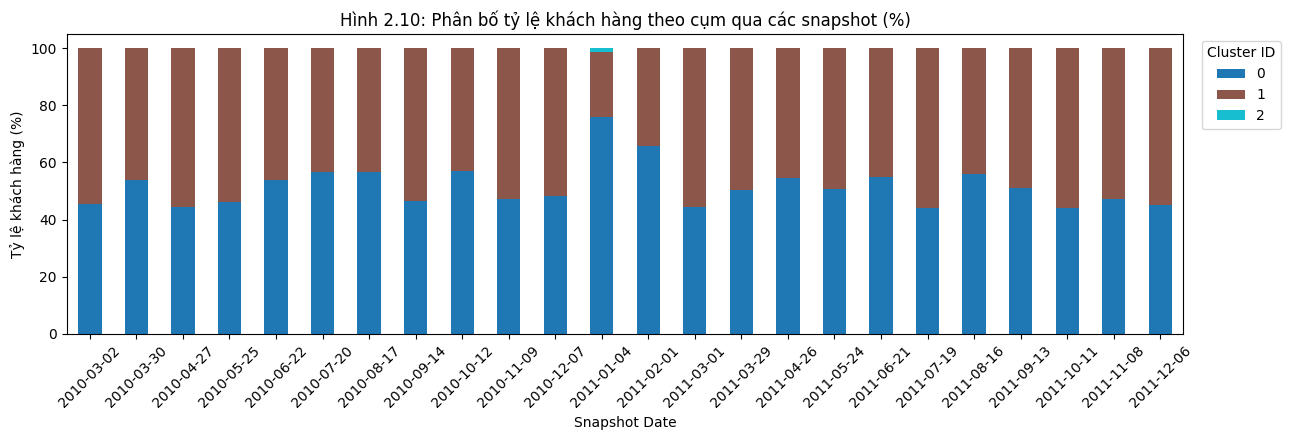


=== BẢNG 4.5: TEMPORAL STABILITY METRICS (MEAN, SD, SE, 95% CI) ===


,metric,display_name,n_transitions,mean,sd,se,ci95_low,ci95_high
0,ari,Adjusted Rand Index (ARI),23,0.0039,0.0157,0.0033,-0.0025,0.0103
1,nmi,Normalized Mutual Information (NMI),23,0.0027,0.0052,0.0011,0.0006,0.0048
2,migration_rate,Migration Rate,23,0.4728,0.0314,0.0065,0.4599,0.4856
3,stable_customer_rate,Stable Customer Rate,23,0.5272,0.0314,0.0065,0.5144,0.5401
4,alignment_coverage,Alignment Coverage,23,0.9995,0.0025,0.0005,0.9984,1.0005
5,common_fraction_smaller_cohort,Common Cohort Fraction,23,0.8703,0.0383,0.0080,0.8546,0.8859



=== ĐỘ NHẠY KHÔNG GIAN TÌM KIẾM K (K-RANGE SENSITIVITY) ===


,k_search_space,mean_selected_k,sd_selected_k,mean_silhouette,sd_silhouette,se_silhouette,mean_dbi,sd_dbi,mean_min_cluster_pct
0,"[2, 5]",2.042,0.204,0.7609,0.0224,0.0046,0.3725,0.0175,43.43
1,"[2, 8]",2.042,0.204,0.7609,0.0224,0.0046,0.3725,0.0175,43.43
2,"[2, 10]",2.042,0.204,0.7609,0.0224,0.0046,0.3725,0.0175,43.43



=== BẢNG 4.2: KẾT QUẢ CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT ===


,split,snapshots,start_snapshot,end_snapshot,mean_k,mean_silhouette,sd_silhouette,se_silhouette,ci95_low_silhouette,ci95_high_silhouette,mean_dbi,mean_temporal_ari
0,Train,16,2010-03-02,2011-04-26,2.062,0.7638,0.0253,0.0063,0.7514,0.7762,0.3720,0.0057
1,Validation,4,2011-05-24,2011-08-16,2.000,0.7669,0.0023,0.0012,0.7646,0.7692,0.3711,-0.0006
2,Test Holdout,4,2011-09-13,2011-12-06,2.000,0.7434,0.0115,0.0058,0.7321,0.7547,0.3755,0.0013


,test_snapshot,unseen_customers,oos_silhouette,oos_dbi
0,2011-09-13,876,0.7565,0.3971
1,2011-10-11,1143,0.7365,0.3796
2,2011-11-08,1400,0.7379,0.3921
3,2011-12-06,1684,0.7371,0.3986



=== BẢNG 4.1 & 4.10: CẤU HÌNH PHẦN CỨNG, ĐỘ TRỄ, TỐC ĐỘ & TÀI NGUYÊN ===


,Value
platform,Linux-6.6.159+-x86_64-with-glibc2.39
python_version,3.13.18
cpu_logical_cores,2
system_total_ram_gb,12.67
process_rss_ram_mb,877.94
peak_python_alloc_mb,129.28
gpu_acceleration,Không sử dụng (CPU scikit-learn deterministic ...
total_runtime_sec,86.145
latency_mean_sec,3.5894
latency_sd_sec,0.8236


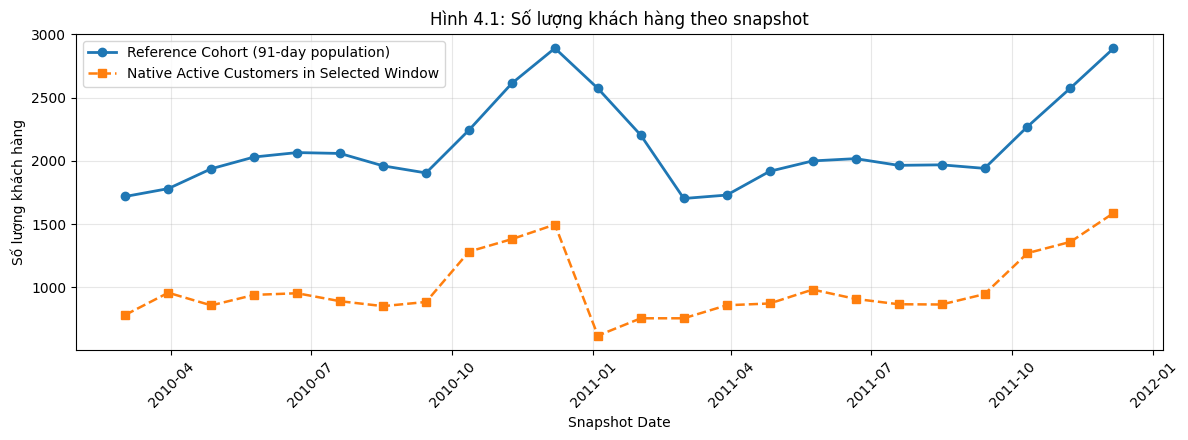

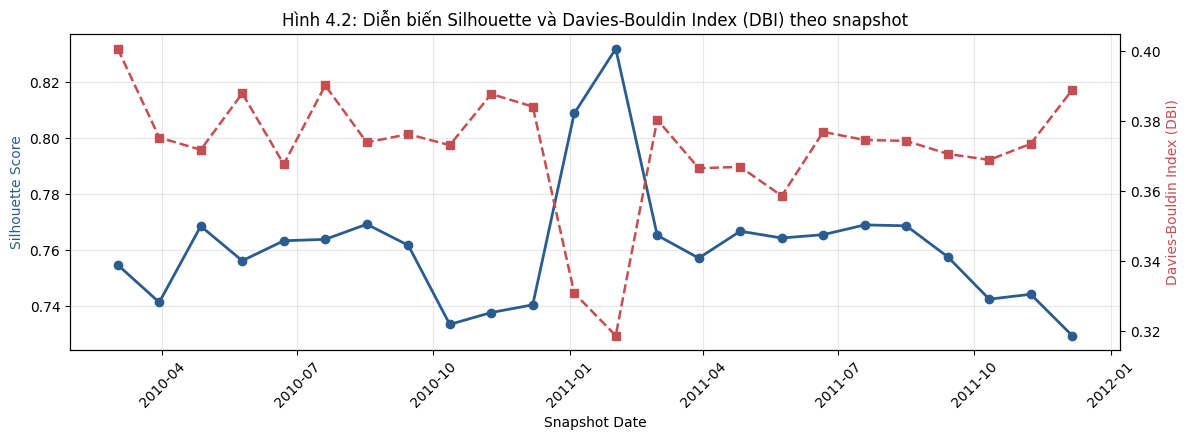

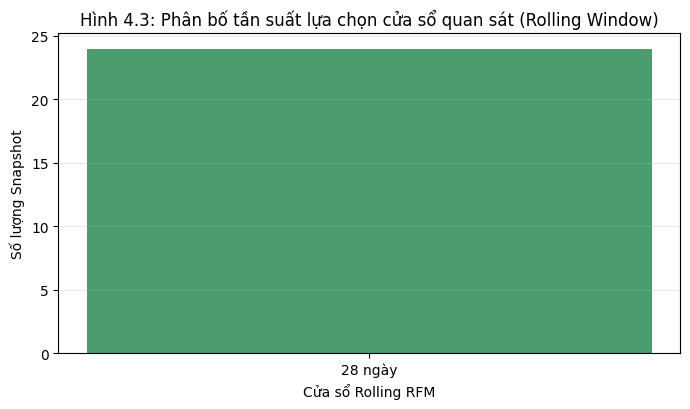

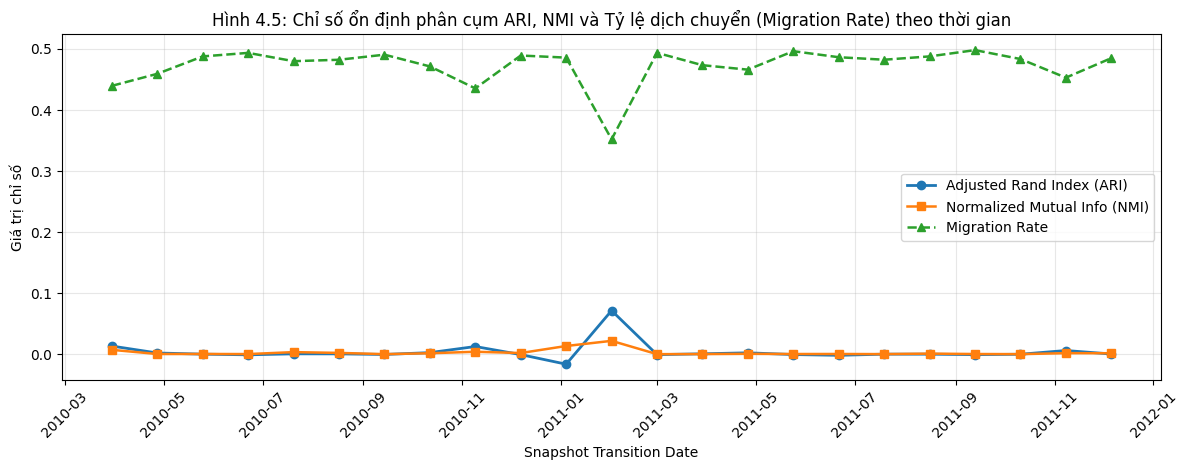

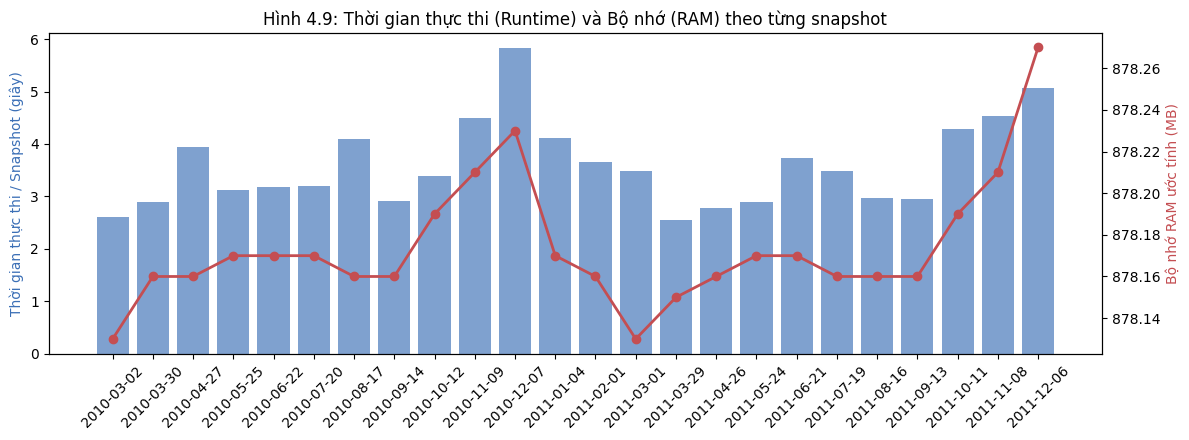

In [17]:
# ============================================================
# CELL 15B - CHRONOLOGICAL HOLDOUT (16/4/4), K-RANGE SENSITIVITY,
# CLUSTER IMBALANCE (IR, H_NORM) & SYSTEM RESOURCE PROFILING
# Also generates Report Figures 2.10, 4.1, 4.2, 4.3, 4.5, 4.9
# ============================================================
import tracemalloc
import platform
import psutil

REPORT_FIG_DIR = Path(OUTPUT_DIR) / "figures"
REPORT_FIG_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. CLUSTER IMBALANCE RATIO (IR) & NORMALIZED ENTROPY (Bảng 2.6 & Hình 2.10)
# ------------------------------------------------------------
imbalance_rows = []
cluster_dist_rows = []

for item in adaptive_history:
    snap_dt = pd.Timestamp(item["snapshot_date"])
    labels = np.asarray(item["labels"])
    n_total = len(labels)
    k_val = int(item["k"])
    counts = np.bincount(labels, minlength=k_val)
    probs = counts / max(1, n_total)

    ir_val = float(counts.max() / max(1, counts.min()))
    pos_probs = probs[probs > 0]
    h_norm = float(-np.sum(pos_probs * np.log(pos_probs)) / np.log(k_val)) if k_val > 1 else 0.0

    imbalance_rows.append({
        "snapshot_date": snap_dt,
        "window_days": int(item["window"]),
        "selected_k": k_val,
        "n_customers": n_total,
        "min_cluster_size": int(counts.min()),
        "max_cluster_size": int(counts.max()),
        "min_cluster_pct": round(float(probs.min() * 100.0), 3),
        "max_cluster_pct": round(float(probs.max() * 100.0), 3),
        "imbalance_ratio_IR": round(ir_val, 4),
        "normalized_entropy_H": round(h_norm, 4)
    })

    for cid, cnt in enumerate(counts):
        cluster_dist_rows.append({
            "snapshot_date": snap_dt,
            "cluster_id": int(cid),
            "customer_count": int(cnt),
            "cluster_pct": round(float(cnt / max(1, n_total) * 100.0), 3)
        })

cluster_imbalance_df = pd.DataFrame(imbalance_rows)
cluster_distribution_df = pd.DataFrame(cluster_dist_rows)

print("=== BẢNG 2.6: PHÂN BỐ KÍCH THƯỚC CLUSTER & IMBALANCE METRICS ===")
display(cluster_imbalance_df)
print(
    f"IR (Mean ± SD): {cluster_imbalance_df['imbalance_ratio_IR'].mean():.4f} ± {cluster_imbalance_df['imbalance_ratio_IR'].std():.4f} | "
    f"H_norm (Mean ± SD): {cluster_imbalance_df['normalized_entropy_H'].mean():.4f} ± {cluster_imbalance_df['normalized_entropy_H'].std():.4f}"
)

# Hình 2.10: Phân bố kích thước cluster theo snapshot
pivot_cluster_pct = cluster_distribution_df.pivot(
    index="snapshot_date", columns="cluster_id", values="cluster_pct"
).fillna(0.0)
ax = pivot_cluster_pct.plot(kind="bar", stacked=True, figsize=(13, 4.5), colormap="tab10")
ax.set_title("Hình 2.10: Phân bố tỷ lệ khách hàng theo cụm qua các snapshot (%)")
ax.set_xlabel("Snapshot Date")
ax.set_ylabel("Tỷ lệ khách hàng (%)")
ax.set_xticklabels([d.strftime("%Y-%m-%d") for d in pivot_cluster_pct.index], rotation=45)
ax.legend(title="Cluster ID", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
if "EDA_PLOT_DIR" in globals():
    plt.savefig(EDA_PLOT_DIR / "Hinh_2_10_cluster_imbalance.png", dpi=300)
plt.savefig(REPORT_FIG_DIR / "Hinh_2_10_cluster_imbalance.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 1B. TEMPORAL STABILITY SUMMARY WITH MEAN, SD, SE & 95% CI (BẢNG 4.5)
# ------------------------------------------------------------
stability_ci_rows = []
if "stability_df" in globals() and not stability_df.empty:
    metric_labels = [
        ("ari", "Adjusted Rand Index (ARI)"),
        ("nmi", "Normalized Mutual Information (NMI)"),
        ("migration_rate", "Migration Rate"),
        ("stable_customer_rate", "Stable Customer Rate"),
        ("alignment_coverage", "Alignment Coverage"),
        ("common_fraction_smaller_cohort", "Common Cohort Fraction")
    ]
    for col_m, label_m in metric_labels:
        if col_m in stability_df.columns:
            vals = pd.to_numeric(stability_df[col_m], errors="coerce").dropna().to_numpy(dtype=float)
            n_v = len(vals)
            if n_v > 0:
                mean_v = float(np.mean(vals))
                sd_v = float(np.std(vals, ddof=1)) if n_v > 1 else 0.0
                se_v = sd_v / np.sqrt(max(1, n_v))
                stability_ci_rows.append({
                    "metric": col_m,
                    "display_name": label_m,
                    "n_transitions": n_v,
                    "mean": round(mean_v, 4),
                    "sd": round(sd_v, 4),
                    "se": round(se_v, 4),
                    "ci95_low": round(mean_v - 1.96 * se_v, 4),
                    "ci95_high": round(mean_v + 1.96 * se_v, 4)
                })

temporal_stability_ci_summary = pd.DataFrame(stability_ci_rows)
print("\n=== BẢNG 4.5: TEMPORAL STABILITY METRICS (MEAN, SD, SE, 95% CI) ===")
display(temporal_stability_ci_summary)

# Extract per-snapshot scaler & clipping parameters audit (Section 3.3 requirement)
scaler_audit_rows = []
for item in adaptive_history:
    sc = item.get("scaler")
    if sc is not None and hasattr(sc, "clip_bounds_"):
        row_sc = {
            "snapshot_date": pd.Timestamp(item["snapshot_date"]),
            "window_days": int(item["window"]),
            "selected_k": int(item["k"])
        }
        for feat_name in ["Recency", "Frequency", "Monetary"]:
            row_sc[f"{feat_name}_log1p_q01"] = round(sc.clip_bounds_[feat_name]["q01_lower"], 4)
            row_sc[f"{feat_name}_log1p_q99"] = round(sc.clip_bounds_[feat_name]["q99_upper"], 4)
            row_sc[f"{feat_name}_scaler_mean"] = round(sc.feature_means_[feat_name], 4)
            row_sc[f"{feat_name}_scaler_std"] = round(sc.feature_stds_[feat_name], 4)
        scaler_audit_rows.append(row_sc)

scaler_parameters_audit_df = pd.DataFrame(scaler_audit_rows)

# ------------------------------------------------------------
# 2. K-RANGE SENSITIVITY ANALYSIS (Mục 3.4: [2,5], [2,8], [2,10])
# ------------------------------------------------------------
k_range_candidates = [(2, 5), (2, 8), (2, 10)]
k_sensitivity_records = []

for k_lo, k_hi in k_range_candidates:
    sils, dbis, ks, min_pcts = [], [], [], []
    for item in adaptive_history:
        best_r, _ = evaluate_k_candidates(item["X"], k_min=k_lo, k_max=k_hi)
        if best_r is not None:
            sils.append(best_r["silhouette"])
            dbis.append(best_r["dbi"])
            ks.append(best_r["best_k"])
            min_pcts.append(best_r["minimum_cluster_fraction"] * 100.0)
    k_sensitivity_records.append({
        "k_search_space": f"[{k_lo}, {k_hi}]",
        "mean_selected_k": round(float(np.mean(ks)), 3),
        "sd_selected_k": round(float(np.std(ks, ddof=1)), 3),
        "mean_silhouette": round(float(np.mean(sils)), 4),
        "sd_silhouette": round(float(np.std(sils, ddof=1)), 4),
        "se_silhouette": round(float(np.std(sils, ddof=1) / np.sqrt(max(1, len(sils)))), 4),
        "mean_dbi": round(float(np.mean(dbis)), 4),
        "sd_dbi": round(float(np.std(dbis, ddof=1)), 4),
        "mean_min_cluster_pct": round(float(np.mean(min_pcts)), 2)
    })

k_range_sensitivity_df = pd.DataFrame(k_sensitivity_records)
print("\n=== ĐỘ NHẠY KHÔNG GIAN TÌM KIẾM K (K-RANGE SENSITIVITY) ===")
display(k_range_sensitivity_df)

# ------------------------------------------------------------
# 3. CHRONOLOGICAL TRAIN / VALIDATION / TEST HOLDOUT (16 / 4 / 4) (Mục 4.2)
# ------------------------------------------------------------
total_snaps = len(adaptive_history)
n_train_snaps = min(16, max(1, int(round(total_snaps * 16 / 24))))
n_val_snaps = min(4, max(1, int(round(total_snaps * 4 / 24))))
n_test_snaps = max(1, total_snaps - n_train_snaps - n_val_snaps)

train_slice = adaptive_history[:n_train_snaps]
val_slice = adaptive_history[n_train_snaps:n_train_snaps + n_val_snaps]
test_slice = adaptive_history[n_train_snaps + n_val_snaps:]

val_tuning_rows = []
for qw in [0.60, 0.70, 0.80, 0.90]:
    for marg in [0.0, 0.01, 0.02]:
        for conf in [1, 2]:
            sim_val = _simulate_adaptive_parameter_policy(
                val_slice, quality_weight=qw, margin=marg, confirmations=conf
            )
            val_tuning_rows.append(sim_val)

val_policy_search_df = pd.DataFrame(val_tuning_rows).sort_values(
    by=["mean_selected_score", "switches"], ascending=[False, True]
).reset_index(drop=True)

best_val_cfg = val_policy_search_df.iloc[0]
locked_qw = float(best_val_cfg["quality_weight"])
locked_margin = float(best_val_cfg["margin"])
locked_conf = int(best_val_cfg["confirmations"])

test_holdout_policy_res = _simulate_adaptive_parameter_policy(
    test_slice, quality_weight=locked_qw, margin=locked_margin, confirmations=locked_conf
)

def summarize_split_slice(slice_records, split_label):
    if not slice_records:
        return {}
    sils = [r["silhouette"] for r in slice_records]
    dbis = [r["dbi"] for r in slice_records]
    aris = [r["temporal_ari"] for r in slice_records if pd.notna(r["temporal_ari"])]
    ks = [r["k"] for r in slice_records]
    n_s = len(sils)
    sd_s = float(np.std(sils, ddof=1)) if n_s > 1 else 0.0
    se_s = sd_s / np.sqrt(max(1, n_s))
    return {
        "split": split_label,
        "snapshots": n_s,
        "start_snapshot": str(pd.Timestamp(slice_records[0]["snapshot_date"]).date()),
        "end_snapshot": str(pd.Timestamp(slice_records[-1]["snapshot_date"]).date()),
        "mean_k": round(float(np.mean(ks)), 3),
        "mean_silhouette": round(float(np.mean(sils)), 4),
        "sd_silhouette": round(sd_s, 4),
        "se_silhouette": round(se_s, 4),
        "ci95_low_silhouette": round(float(np.mean(sils) - 1.96 * se_s), 4),
        "ci95_high_silhouette": round(float(np.mean(sils) + 1.96 * se_s), 4),
        "mean_dbi": round(float(np.mean(dbis)), 4),
        "mean_temporal_ari": round(float(np.mean(aris)), 4) if aris else np.nan
    }

chronological_split_df = pd.DataFrame([
    summarize_split_slice(train_slice, "Train"),
    summarize_split_slice(val_slice, "Validation"),
    summarize_split_slice(test_slice, "Test Holdout")
])

oos_customer_records = []
if train_slice and test_slice:
    anchor_train = train_slice[-1]
    _, anchor_scaler, _ = transform_rfm(anchor_train["rfm"])
    anchor_model = anchor_train["model"]
    train_cust_set = set(anchor_train["rfm"].index)

    for t_rec in test_slice:
        t_rfm = t_rec["rfm"]
        unseen_ids = [cid for cid in t_rfm.index if cid not in train_cust_set]
        if len(unseen_ids) >= 10:
            sub_rfm = t_rfm.loc[unseen_ids, ["Recency", "Frequency", "Monetary"]].copy()
            for col in ["Recency", "Frequency", "Monetary"]:
                sub_rfm[col] = np.log1p(pd.to_numeric(sub_rfm[col], errors="coerce").clip(lower=0))
            X_unseen = anchor_scaler.transform(sub_rfm)
            pred_labels = anchor_model.predict(X_unseen)
            oos_sil = float(silhouette_score(X_unseen, pred_labels)) if len(np.unique(pred_labels)) > 1 else np.nan
            oos_dbi = float(davies_bouldin_score(X_unseen, pred_labels)) if len(np.unique(pred_labels)) > 1 else np.nan
            oos_customer_records.append({
                "test_snapshot": pd.Timestamp(t_rec["snapshot_date"]),
                "unseen_customers": len(unseen_ids),
                "oos_silhouette": round(oos_sil, 4),
                "oos_dbi": round(oos_dbi, 4)
            })

oos_customer_df = pd.DataFrame(oos_customer_records)

print("\n=== BẢNG 4.2: KẾT QUẢ CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT ===")
display(chronological_split_df)
if not oos_customer_df.empty:
    display(oos_customer_df)

# ------------------------------------------------------------
# 4. SYSTEM RESOURCE, LATENCY & THROUGHPUT PROFILING (Bảng 4.1 & 4.10)
# ------------------------------------------------------------
process_handle = psutil.Process(os.getpid())
rss_before_mb = process_handle.memory_info().rss / (1024 ** 2)

snapshot_latencies = [float(r["runtime_seconds"]) for r in adaptive_history]
tx_per_snap = []
cust_per_snap = [int(r["n_customers"]) for r in adaptive_history]
ram_per_snap_mb = []

tracemalloc.start()
for r in adaptive_history:
    s_end = pd.Timestamp(r["snapshot_date"]).normalize() + pd.Timedelta(days=1)
    s_start = s_end - pd.Timedelta(days=int(r["reference_window_days"]))
    n_tx = int(((df["InvoiceDate"] >= s_start) & (df["InvoiceDate"] < s_end)).sum())
    tx_per_snap.append(n_tx)
    mem_snap_bytes = (
        r["rfm"].memory_usage(deep=True).sum()
        + r["native_rfm"].memory_usage(deep=True).sum()
        + r["X"].nbytes
    )
    ram_per_snap_mb.append(rss_before_mb + (mem_snap_bytes / (1024 ** 2)))

_ = evaluate_windows_at_snapshot(df, snapshot_dates[-1])
_, peak_traced_bytes = tracemalloc.get_traced_memory()
tracemalloc.stop()
rss_after_mb = process_handle.memory_info().rss / (1024 ** 2)

lat_arr = np.asarray(snapshot_latencies, dtype=float)
total_runtime_sec = max(1e-6, float(np.sum(lat_arr)))

snapshot_runtime_memory_df = pd.DataFrame({
    "snapshot_date": [pd.Timestamp(r["snapshot_date"]) for r in adaptive_history],
    "reference_customers": cust_per_snap,
    "native_customers": [int(r["n_native_customers"]) for r in adaptive_history],
    "transactions_in_reference_window": tx_per_snap,
    "runtime_seconds": np.round(lat_arr, 4),
    "estimated_ram_mb": np.round(ram_per_snap_mb, 2)
})

system_resource_profiling = pd.DataFrame([{
    "platform": platform.platform(),
    "python_version": platform.python_version(),
    "cpu_logical_cores": int(os.cpu_count() or 1),
    "system_total_ram_gb": round(psutil.virtual_memory().total / (1024 ** 3), 2),
    "process_rss_ram_mb": round(max(rss_before_mb, rss_after_mb), 2),
    "peak_python_alloc_mb": round(peak_traced_bytes / (1024 ** 2), 2),
    "gpu_acceleration": "Không sử dụng (CPU scikit-learn deterministic 1-thread)",
    "total_runtime_sec": round(total_runtime_sec, 4),
    "latency_mean_sec": round(float(np.mean(lat_arr)), 4),
    "latency_sd_sec": round(float(np.std(lat_arr, ddof=1)) if len(lat_arr) > 1 else 0.0, 4),
    "latency_se_sec": round(float(np.std(lat_arr, ddof=1) / np.sqrt(max(1, len(lat_arr)))) if len(lat_arr) > 1 else 0.0, 4),
    "latency_median_sec": round(float(np.median(lat_arr)), 4),
    "latency_p95_sec": round(float(np.percentile(lat_arr, 95)), 4),
    "throughput_transactions_per_sec": round(float(np.sum(tx_per_snap) / total_runtime_sec), 2),
    "throughput_customers_per_sec": round(float(np.sum(cust_per_snap) / total_runtime_sec), 2)
}])

print("\n=== BẢNG 4.1 & 4.10: CẤU HÌNH PHẦN CỨNG, ĐỘ TRỄ, TỐC ĐỘ & TÀI NGUYÊN ===")
display(system_resource_profiling.T.rename(columns={0: "Value"}))

# ------------------------------------------------------------
# 5. GENERATE EXPLICIT CHAPTER 4 REPORT FIGURES (Hình 4.1, 4.2, 4.3, 4.5, 4.9)
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(snapshot_runtime_memory_df["snapshot_date"], snapshot_runtime_memory_df["reference_customers"],
        marker="o", linewidth=2, label="Reference Cohort (91-day population)")
ax.plot(snapshot_runtime_memory_df["snapshot_date"], snapshot_runtime_memory_df["native_customers"],
        marker="s", linestyle="--", linewidth=1.8, label="Native Active Customers in Selected Window")
ax.set_title("Hình 4.1: Số lượng khách hàng theo snapshot")
ax.set_xlabel("Snapshot Date")
ax.set_ylabel("Số lượng khách hàng")
ax.legend()
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(REPORT_FIG_DIR / "Hinh_4_1_customers_per_snapshot.png", dpi=300)
plt.show()

fig, ax1 = plt.subplots(figsize=(12, 4.5))
snaps_plot = [pd.Timestamp(r["snapshot_date"]) for r in adaptive_history]
sils_plot = [float(r["silhouette"]) for r in adaptive_history]
dbis_plot = [float(r["dbi"]) for r in adaptive_history]
ax1.plot(snaps_plot, sils_plot, color="#2b5c8f", marker="o", linewidth=2, label="Silhouette Score")
ax1.set_xlabel("Snapshot Date")
ax1.set_ylabel("Silhouette Score", color="#2b5c8f")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(snaps_plot, dbis_plot, color="#c44e52", marker="s", linestyle="--", linewidth=1.8, label="Davies-Bouldin Index")
ax2.set_ylabel("Davies-Bouldin Index (DBI)", color="#c44e52")
plt.title("Hình 4.2: Diễn biến Silhouette và Davies-Bouldin Index (DBI) theo snapshot")
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(REPORT_FIG_DIR / "Hinh_4_2_silhouette_and_dbi.png", dpi=300)
plt.show()

win_counts = pd.Series([int(r["window"]) for r in adaptive_history]).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar([f"{w} ngày" for w in win_counts.index], win_counts.values, color=["#4a9c6d", "#3b6fb6", "#d58e3c"][:len(win_counts)])
ax.set_title("Hình 4.3: Phân bố tần suất lựa chọn cửa sổ quan sát (Rolling Window)")
ax.set_xlabel("Cửa sổ Rolling RFM")
ax.set_ylabel("Số lượng Snapshot")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(REPORT_FIG_DIR / "Hinh_4_3_selected_window_distribution.png", dpi=300)
plt.show()

if "stability_df" in globals() and not stability_df.empty:
    fig, ax = plt.subplots(figsize=(12, 4.8))
    ax.plot(stability_df["snapshot_to"], stability_df["ari"], marker="o", linewidth=2, label="Adjusted Rand Index (ARI)")
    ax.plot(stability_df["snapshot_to"], stability_df["nmi"], marker="s", linewidth=1.8, label="Normalized Mutual Info (NMI)")
    ax.plot(stability_df["snapshot_to"], stability_df["migration_rate"], marker="^", linestyle="--", linewidth=1.8, label="Migration Rate")
    ax.set_title("Hình 4.5: Chỉ số ổn định phân cụm ARI, NMI và Tỷ lệ dịch chuyển (Migration Rate) theo thời gian")
    ax.set_xlabel("Snapshot Transition Date")
    ax.set_ylabel("Giá trị chỉ số")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(REPORT_FIG_DIR / "Hinh_4_5_ari_nmi_migration_rate.png", dpi=300)
    plt.show()

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(snapshot_runtime_memory_df["snapshot_date"].dt.strftime("%Y-%m-%d"),
        snapshot_runtime_memory_df["runtime_seconds"], alpha=0.65, color="#3b6fb6", label="Runtime (giây)")
ax1.set_ylabel("Thời gian thực thi / Snapshot (giây)", color="#3b6fb6")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(snapshot_runtime_memory_df["snapshot_date"].dt.strftime("%Y-%m-%d"),
         snapshot_runtime_memory_df["estimated_ram_mb"], color="#c44e52", marker="o", linewidth=2, label="RAM (MB)")
ax2.set_ylabel("Bộ nhớ RAM ước tính (MB)", color="#c44e52")
plt.title("Hình 4.9: Thời gian thực thi (Runtime) và Bộ nhớ (RAM) theo từng snapshot")
plt.tight_layout()
plt.savefig(REPORT_FIG_DIR / "Hinh_4_9_runtime_and_memory.png", dpi=300)
plt.show()

# Cell 16 — Visualization, Statistical Evaluation, Export và Reproducibility

Tổng hợp kết quả Adaptive RFM, Baseline, Ablation, Evolution, Stability và Drift; thực hiện kiểm định thống kê; xuất bảng/biểu đồ/ZIP; tạo reproducibility manifest và requirements.txt khóa phiên bản thư viện của lần chạy.

,comparison_group,metric,reference_method,comparison_method,n_pairs,median_difference,mean_difference,mean_difference_ci_low,mean_difference_ci_high,median_difference_ci_low,median_difference_ci_high,paired_rank_biserial,bootstrap_block_length,wilcoxon_statistic,p_value,test_status,p_adjusted_holm,significant_after_holm
0,Adaptive vs Baselines,silhouette,Adaptive Rolling Dynamic RFM,Lifetime RFM,24,-0.40988,-0.41164,-0.42121,-0.40276,-0.41603,-0.40456,-1.00000,3,0.0,0.00000,ok,0.00000,True
1,Adaptive vs Baselines,silhouette,Adaptive Rolling Dynamic RFM,Rolling 28 Days,24,-0.07675,-0.08031,-0.08828,-0.07384,-0.08309,-0.06943,-1.00000,3,0.0,0.00000,ok,0.00000,True
2,Adaptive vs Baselines,silhouette,Adaptive Rolling Dynamic RFM,Rolling 56 Days,24,-0.18059,-0.18009,-0.19077,-0.17012,-0.19690,-0.16612,-1.00000,3,0.0,0.00000,ok,0.00000,True
3,Adaptive vs Baselines,silhouette,Adaptive Rolling Dynamic RFM,Rolling 91 Days,24,-0.41163,-0.41126,-0.41715,-0.40422,-0.41907,-0.40536,-1.00000,3,0.0,0.00000,ok,0.00000,True
4,Adaptive vs Baselines,davies_bouldin,Adaptive Rolling Dynamic RFM,Lifetime RFM,24,0.54093,0.54686,0.53609,0.55754,0.52752,0.56673,1.00000,3,0.0,0.00000,ok,0.00000,True
5,Adaptive vs Baselines,davies_bouldin,Adaptive Rolling Dynamic RFM,Rolling 28 Days,24,0.38178,0.36581,0.34458,0.38169,0.36776,0.38894,1.00000,3,0.0,0.00000,ok,0.00000,True
6,Adaptive vs Baselines,davies_bouldin,Adaptive Rolling Dynamic RFM,Rolling 56 Days,24,0.38728,0.38906,0.38045,0.39717,0.37359,0.39675,1.00000,3,0.0,0.00000,ok,0.00000,True
7,Adaptive vs Baselines,davies_bouldin,Adaptive Rolling Dynamic RFM,Rolling 91 Days,24,0.62822,0.63085,0.61660,0.64421,0.61424,0.64909,1.00000,3,0.0,0.00000,ok,0.00000,True
8,Adaptive vs Baselines,calinski_harabasz,Adaptive Rolling Dynamic RFM,Lifetime RFM,24,-7725.22824,-7819.26618,-8362.49774,-7344.32884,-7931.96866,-7379.59433,-1.00000,3,0.0,0.00000,ok,0.00000,True
9,Adaptive vs Baselines,calinski_harabasz,Adaptive Rolling Dynamic RFM,Rolling 28 Days,24,-1069.11417,-966.20346,-1265.84012,-603.70991,-1321.99020,-870.26587,-0.84000,3,24.0,0.00009,ok,0.00027,True


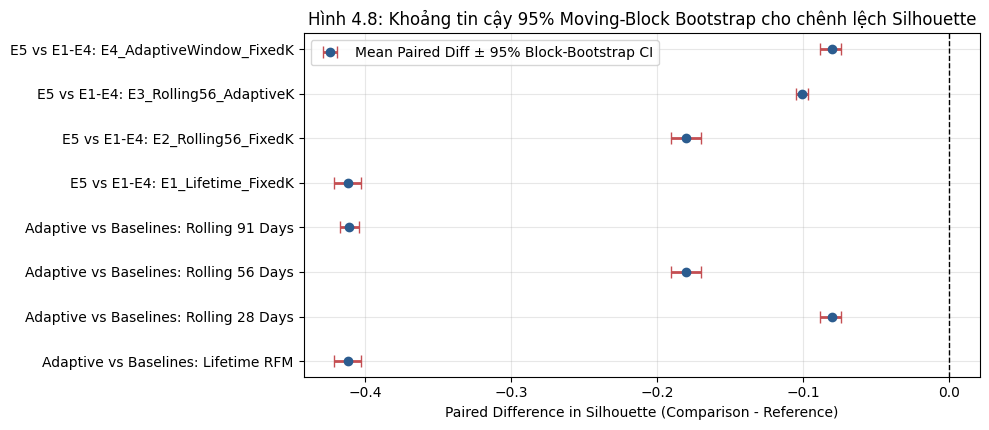

Exported tables: 48
ZIP archive created at: /content/adaptive_rolling_dynamic_rfm_results.zip


In [18]:
# ============================================================
# CELL 16 - FINAL VISUALIZATION, STATISTICAL EVALUATION & EXPORT
# ============================================================
import os
import json
import zipfile
import hashlib
import platform
import sys
from datetime import datetime, timezone
from importlib import metadata as importlib_metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, rankdata

OUTPUT_DIR = "/content/adaptive_rolling_dynamic_rfm_results"
PLOT_DIR = os.path.join(OUTPUT_DIR, "figures")
TABLE_DIR = os.path.join(OUTPUT_DIR, "tables")
os.makedirs(PLOT_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

STATISTICAL_MIN_PAIRS = 8
STATISTICAL_BLOCK_LENGTH = 3
STATISTICAL_BOOTSTRAP_RESAMPLES = 3000
STATISTICAL_ALPHA = 0.05


def to_dataframe(value):
    if isinstance(value, pd.DataFrame):
        return value.copy()
    if isinstance(value, list):
        return pd.DataFrame(value)
    if isinstance(value, dict):
        return pd.DataFrame([value])
    return pd.DataFrame()


def save_figure(filename):
    path = os.path.join(PLOT_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    return path


adaptive_records = []
adaptive_rfm_records = []

for item in adaptive_history:
    snapshot_date = pd.Timestamp(item["snapshot_date"])
    rfm = item["rfm"].copy()
    X = np.asarray(item["X"])
    labels = np.asarray(item["labels"])
    n_clusters = len(np.unique(labels))
    selected_k = int(item.get("k", n_clusters))
    metrics = baseline_evaluate_clustering(X, labels)
    cluster_sizes = pd.Series(labels).value_counts()

    adaptive_records.append({
        "snapshot_date": snapshot_date,
        "window_days": item["window"],
        "selected_k": selected_k,
        "n_customers": len(rfm),
        "n_reference_cohort_customers": len(rfm),
        "n_native_customers": int(item.get("n_native_customers", len(rfm))),
        "reference_window_days": int(item.get("reference_window_days", REFERENCE_COHORT_WINDOW)),
        "n_inactive_in_window": int(item.get("n_inactive_in_window", 0)),
        "native_silhouette": item.get("native_silhouette", np.nan),
        "native_davies_bouldin": item.get("native_dbi", np.nan),
        "native_calinski_harabasz": item.get("native_chi", np.nan),
        "n_clusters": n_clusters,
        "silhouette": metrics["silhouette"],
        "davies_bouldin": metrics["davies_bouldin"],
        "calinski_harabasz": metrics["calinski_harabasz"],
        "selection_silhouette": item.get("silhouette", np.nan),
        "selection_dbi": item.get("dbi", np.nan),
        "selection_quality": item.get("quality", np.nan),
        "selection_eval_customers": item.get("n_eval_customers", np.nan),
        "temporal_ari": item.get("temporal_ari", np.nan),
        "ari_positive_utility": item.get("ari_positive_utility", np.nan),
        "stability_reliability": item.get("stability_reliability", np.nan),
        "stability_smoothed": item.get("stability_smoothed", np.nan),
        "effective_quality_weight": item.get("effective_quality_weight", np.nan),
        "effective_stability_weight": item.get("effective_stability_weight", np.nan),
        "best_candidate_window": item.get("best_candidate_window", np.nan),
        "oracle_adaptive_score": item.get("oracle_adaptive_score", np.nan),
        "snapshot_regret": item.get("snapshot_regret", np.nan),
        "score_improvement": item.get("score_improvement", np.nan),
        "switch_reason": item.get("switch_reason", None),
        "pending_confirmation_count": item.get("pending_confirmation_count", 0),
        "minimum_cluster_size": int(cluster_sizes.min()),
        "maximum_cluster_size": int(cluster_sizes.max()),
        "minimum_cluster_fraction": float(cluster_sizes.min() / len(rfm)),
        "inertia": float(item["model"].inertia_) if item.get("model") is not None else np.nan
    })

    profile = rfm.copy()
    profile["CustomerID"] = profile.index
    profile["Cluster"] = labels
    profile["snapshot_date"] = snapshot_date
    profile["window_days"] = item["window"]
    profile["selected_k"] = selected_k
    adaptive_rfm_records.append(profile.reset_index(drop=True))

adaptive_model_summary = pd.DataFrame(adaptive_records)
adaptive_segment_data = pd.concat(adaptive_rfm_records, ignore_index=True)

adaptive_window_evaluation_records = []
for item in adaptive_history:
    candidate_table = item.get("window_table", pd.DataFrame())
    if candidate_table is not None and not candidate_table.empty:
        for _, candidate_row in candidate_table.iterrows():
            candidate_record = candidate_row.to_dict()
            candidate_record["snapshot_date"] = pd.Timestamp(item["snapshot_date"])
            candidate_record["selected_window"] = int(item["window"])
            adaptive_window_evaluation_records.append(candidate_record)
adaptive_window_evaluations = pd.DataFrame(adaptive_window_evaluation_records)

adaptive_overall_summary = pd.DataFrame([{
    "snapshots": adaptive_model_summary["snapshot_date"].nunique(),
    "mean_reference_cohort_customers": adaptive_model_summary["n_reference_cohort_customers"].mean(),
    "mean_native_window_customers": adaptive_model_summary["n_native_customers"].mean(),
    "mean_selected_k": adaptive_model_summary["selected_k"].mean(),
    "mean_silhouette": adaptive_model_summary["silhouette"].mean(),
    "std_silhouette": adaptive_model_summary["silhouette"].std(),
    "mean_davies_bouldin": adaptive_model_summary["davies_bouldin"].mean(),
    "mean_calinski_harabasz": adaptive_model_summary["calinski_harabasz"].mean(),
    "mean_minimum_cluster_fraction": adaptive_model_summary["minimum_cluster_fraction"].mean()
}])

adaptive_native_comparison = adaptive_model_summary[[
    "snapshot_date", "window_days", "n_native_customers", "selected_k",
    "native_silhouette", "native_davies_bouldin", "native_calinski_harabasz"
]].rename(columns={
    "n_native_customers": "n_customers",
    "native_silhouette": "silhouette",
    "native_davies_bouldin": "davies_bouldin",
    "native_calinski_harabasz": "calinski_harabasz"
}).copy()
adaptive_native_comparison["method"] = "Adaptive Rolling Dynamic RFM"

baseline_native_comparison = baseline_results.copy()
baseline_native_comparison["selected_k"] = baseline_native_comparison["n_clusters"]
baseline_native_comparison = baseline_native_comparison[[
    "snapshot_date", "window_days", "n_customers", "selected_k",
    "silhouette", "davies_bouldin", "calinski_harabasz", "method"
]]

final_native_comparison = pd.concat([adaptive_native_comparison, baseline_native_comparison], ignore_index=True)
final_native_summary = (
    final_native_comparison.groupby("method").agg(
        snapshots=("snapshot_date", "nunique"),
        mean_customers=("n_customers", "mean"),
        mean_k=("selected_k", "mean"),
        mean_silhouette=("silhouette", "mean"),
        std_silhouette=("silhouette", "std"),
        mean_davies_bouldin=("davies_bouldin", "mean"),
        mean_calinski_harabasz=("calinski_harabasz", "mean")
    ).reset_index()
)

common_cohort_tables = []
if "common_cohort_results" in globals() and not common_cohort_results.empty:
    t1 = common_cohort_results.copy()
    t1["comparison_group"] = "Adaptive vs Baselines"
    common_cohort_tables.append(t1)
if "ablation_common_cohort_results" in globals() and not ablation_common_cohort_results.empty:
    t2 = ablation_common_cohort_results.copy()
    t2["comparison_group"] = "Ablation E1-E5"
    common_cohort_tables.append(t2)
final_common_cohort = pd.concat(common_cohort_tables, ignore_index=True) if common_cohort_tables else pd.DataFrame()


def moving_block_bootstrap_ci(values, block_length=STATISTICAL_BLOCK_LENGTH, n_boot=STATISTICAL_BOOTSTRAP_RESAMPLES, random_state=RANDOM_STATE):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    n = len(values)
    if n == 0:
        return (np.nan, np.nan, np.nan, np.nan)
    if n == 1:
        v = float(values[0])
        return (v, v, v, v)
    block_length = max(1, min(int(block_length), n))
    n_blocks = int(np.ceil(n / block_length))
    rng = np.random.default_rng(random_state)
    means = np.empty(int(n_boot), dtype=float)
    medians = np.empty(int(n_boot), dtype=float)
    offsets = np.arange(block_length)
    for b in range(int(n_boot)):
        starts = rng.integers(0, n, size=n_blocks)
        sample = np.concatenate([values[(start + offsets) % n] for start in starts])[:n]
        means[b] = float(np.mean(sample))
        medians[b] = float(np.median(sample))
    return (
        float(np.quantile(means, 0.025)), float(np.quantile(means, 0.975)),
        float(np.quantile(medians, 0.025)), float(np.quantile(medians, 0.975))
    )


def paired_wilcoxon_comparison(data, method_column, metric_column, reference_method, comparison_group):
    results = []
    if data.empty or not {"snapshot_date", method_column, metric_column}.issubset(data.columns):
        return pd.DataFrame()
    pivot = data.pivot_table(index="snapshot_date", columns=method_column, values=metric_column, aggfunc="mean")
    if reference_method not in pivot.columns:
        return pd.DataFrame()

    for method_name in pivot.columns:
        if method_name == reference_method:
            continue
        pair = pivot[[reference_method, method_name]].dropna()
        n_pairs = len(pair)
        if n_pairs < STATISTICAL_MIN_PAIRS:
            continue
        ref_vals = pair[reference_method].to_numpy(dtype=float)
        cmp_vals = pair[method_name].to_numpy(dtype=float)
        diffs = cmp_vals - ref_vals

        if np.allclose(diffs, 0):
            stat, p_val, status = 0.0, 1.0, "all_differences_zero"
        else:
            test = wilcoxon(cmp_vals, ref_vals, alternative="two-sided", zero_method="wilcox", method="auto")
            stat, p_val, status = float(test.statistic), float(test.pvalue), "ok"

        ci_low, ci_high, med_low, med_high = moving_block_bootstrap_ci(
            diffs, block_length=min(STATISTICAL_BLOCK_LENGTH, n_pairs),
            n_boot=STATISTICAL_BOOTSTRAP_RESAMPLES, random_state=RANDOM_STATE + len(results) + n_pairs
        )
        nonzero = diffs[~np.isclose(diffs, 0.0)]
        if len(nonzero):
            signed_ranks = rankdata(np.abs(nonzero), method="average")
            pos_sum = float(signed_ranks[nonzero > 0].sum())
            neg_sum = float(signed_ranks[nonzero < 0].sum())
            r_tot = pos_sum + neg_sum
            r_biserial = (pos_sum - neg_sum) / r_tot if r_tot else 0.0
        else:
            r_biserial = 0.0

        results.append({
            "comparison_group": comparison_group,
            "metric": metric_column,
            "reference_method": reference_method,
            "comparison_method": method_name,
            "n_pairs": n_pairs,
            "median_difference": float(np.median(diffs)),
            "mean_difference": float(np.mean(diffs)),
            "mean_difference_ci_low": ci_low,
            "mean_difference_ci_high": ci_high,
            "median_difference_ci_low": med_low,
            "median_difference_ci_high": med_high,
            "paired_rank_biserial": float(r_biserial),
            "bootstrap_block_length": int(min(STATISTICAL_BLOCK_LENGTH, n_pairs)),
            "wilcoxon_statistic": stat,
            "p_value": p_val,
            "test_status": status
        })
    return pd.DataFrame(results)


def apply_holm_correction(results, alpha=STATISTICAL_ALPHA):
    results = results.copy()
    results["p_adjusted_holm"] = np.nan
    results["significant_after_holm"] = False
    valid_indices = results.index[results["p_value"].notna()].tolist()
    if not valid_indices:
        return results
    sorted_indices = sorted(valid_indices, key=lambda idx: results.loc[idx, "p_value"])
    m = len(sorted_indices)
    running_max = 0.0
    for rank, idx in enumerate(sorted_indices):
        p_val = float(results.loc[idx, "p_value"])
        adjusted = min(1.0, (m - rank) * p_val)
        running_max = max(running_max, adjusted)
        results.loc[idx, "p_adjusted_holm"] = running_max
        results.loc[idx, "significant_after_holm"] = running_max < alpha
    return results


statistical_results = []
if not final_common_cohort.empty:
    ab_base = final_common_cohort[final_common_cohort["comparison_group"] == "Adaptive vs Baselines"].copy()
    for metric in ["silhouette", "davies_bouldin", "calinski_harabasz"]:
        r = paired_wilcoxon_comparison(ab_base, "method", metric, "Adaptive Rolling Dynamic RFM", "Adaptive vs Baselines")
        if not r.empty:
            statistical_results.append(r)

    ab_e5 = final_common_cohort[final_common_cohort["comparison_group"] == "Ablation E1-E5"].copy()
    for metric in ["silhouette", "davies_bouldin", "calinski_harabasz"]:
        r = paired_wilcoxon_comparison(ab_e5, "experiment", metric, "E5_AdaptiveWindow_AdaptiveK", "E5 vs E1-E4")
        if not r.empty:
            statistical_results.append(r)

statistical_results = pd.concat(statistical_results, ignore_index=True) if statistical_results else pd.DataFrame()
if not statistical_results.empty:
    statistical_results = apply_holm_correction(statistical_results)
    display(statistical_results.round(5))

segment_profile = (
    adaptive_segment_data.groupby(["snapshot_date", "Cluster"]).agg(
        customer_count=("CustomerID", "nunique"),
        mean_recency=("Recency", "mean"),
        median_recency=("Recency", "median"),
        mean_frequency=("Frequency", "mean"),
        median_frequency=("Frequency", "median"),
        mean_monetary=("Monetary", "mean"),
        median_monetary=("Monetary", "median")
    ).reset_index()
)

evolution_events_df = to_dataframe(evolution_events)
customer_migrations_df = to_dataframe(customer_migrations)
stability_results_df = to_dataframe(stability_df)
evolution_summary_df = to_dataframe(evolution_summary if "evolution_summary" in globals() else None)
real_drift_data_df = to_dataframe(real_drift_data)
drift_summary_df = to_dataframe(drift_experiment_summary)
monte_carlo_summary_df = to_dataframe(monte_carlo_summary if "monte_carlo_summary" in globals() else None)
synthetic_metrics_df = to_dataframe(synthetic_metrics if "synthetic_metrics" in globals() else None)
real_alarm_events_df = to_dataframe(real_alarm_events if "real_alarm_events" in globals() else None)

migration_summary = (
    customer_migrations_df.groupby("migration_status").size().reset_index(name="customer_count")
    if not customer_migrations_df.empty and "migration_status" in customer_migrations_df.columns
    else pd.DataFrame()
)

# Hình 4.8: Moving-Block Bootstrap CIs Forest Plot
if not statistical_results.empty and "mean_difference_ci_low" in statistical_results.columns:
    sil_stats = statistical_results[
        (statistical_results["metric"] == "silhouette") & statistical_results["mean_difference"].notna()
    ].copy()
    if not sil_stats.empty:
        sil_stats["label"] = sil_stats["comparison_group"] + ": " + sil_stats["comparison_method"]
        fig, ax = plt.subplots(figsize=(10, max(4.2, 0.55 * len(sil_stats))))
        y_pos = np.arange(len(sil_stats))
        means = sil_stats["mean_difference"].to_numpy(dtype=float)
        lows = sil_stats["mean_difference_ci_low"].to_numpy(dtype=float)
        highs = sil_stats["mean_difference_ci_high"].to_numpy(dtype=float)
        ax.errorbar(means, y_pos, xerr=[np.maximum(0.0, means - lows), np.maximum(0.0, highs - means)],
                    fmt="o", color="#2b5c8f", ecolor="#c44e52", elinewidth=2, capsize=4,
                    label="Mean Paired Diff ± 95% Block-Bootstrap CI")
        ax.axvline(0.0, color="black", linestyle="--", linewidth=1)
        ax.set_yticks(y_pos)
        ax.set_yticklabels(sil_stats["label"])
        ax.set_xlabel("Paired Difference in Silhouette (Comparison - Reference)")
        ax.set_title("Hình 4.8: Khoảng tin cậy 95% Moving-Block Bootstrap cho chênh lệch Silhouette")
        ax.legend(loc="best")
        ax.grid(alpha=0.3)
        save_figure("13_Hinh_4_8_bootstrap_confidence_intervals.png")

final_experiment_summary = {
    "dataset_rows": int(len(baseline_transactions)),
    "dataset_customers": int(baseline_transactions["CustomerID"].nunique()),
    "dataset_invoices": int(baseline_transactions["Invoice"].nunique()),
    "snapshot_count": int(adaptive_model_summary["snapshot_date"].nunique()),
    "adaptive_mean_silhouette": float(adaptive_model_summary["silhouette"].mean()),
    "adaptive_mean_davies_bouldin": float(adaptive_model_summary["davies_bouldin"].mean()),
    "adaptive_mean_calinski_harabasz": float(adaptive_model_summary["calinski_harabasz"].mean()),
    "adaptive_window_switch_count": int(adaptive_model_summary["window_days"].ne(adaptive_model_summary["window_days"].shift()).sum() - 1) if len(adaptive_model_summary) > 1 else 0,
    "adaptive_mean_window_days": float(adaptive_model_summary["window_days"].mean()),
    "adaptive_mean_k": float(adaptive_model_summary["selected_k"].mean()),
    "mean_temporal_ari": float(stability_results_df["ari"].mean()) if "ari" in stability_results_df.columns else np.nan,
    "evolution_event_count": int(len(evolution_events_df)),
    "customer_migration_records": int(len(customer_migrations_df)),
    "real_drift_alarm_count": int(real_drift_data_df["alarm"].sum()) if "alarm" in real_drift_data_df.columns else 0,
    "statistical_test_count": int(len(statistical_results))
}
final_experiment_summary_df = pd.DataFrame([final_experiment_summary])

tables_to_export = {
    "adaptive_model_summary": adaptive_model_summary,
    "dataset_schema": dataset_schema_df if "dataset_schema_df" in globals() else pd.DataFrame(),
    "snapshot_schedule": snapshot_schedule_df if "snapshot_schedule_df" in globals() else pd.DataFrame(),
    "scaler_parameters_audit": scaler_parameters_audit_df if "scaler_parameters_audit_df" in globals() else pd.DataFrame(),
    "temporal_stability_ci_summary": temporal_stability_ci_summary if "temporal_stability_ci_summary" in globals() else pd.DataFrame(),
    "missing_audit": missing_audit_df if "missing_audit_df" in globals() else pd.DataFrame(),
    "preprocessing_audit": preprocessing_audit_df if "preprocessing_audit_df" in globals() else pd.DataFrame(),
    "eda_transaction_stats": eda_transaction_stats if "eda_transaction_stats" in globals() else pd.DataFrame(),
    "eda_rfm_stats": eda_rfm_stats if "eda_rfm_stats" in globals() else pd.DataFrame(),
    "eda_pareto_summary": eda_pareto_summary if "eda_pareto_summary" in globals() else pd.DataFrame(),
    "cluster_imbalance": cluster_imbalance_df if "cluster_imbalance_df" in globals() else pd.DataFrame(),
    "cluster_distribution": cluster_distribution_df if "cluster_distribution_df" in globals() else pd.DataFrame(),
    "k_range_sensitivity": k_range_sensitivity_df if "k_range_sensitivity_df" in globals() else pd.DataFrame(),
    "chronological_split_summary": chronological_split_df if "chronological_split_df" in globals() else pd.DataFrame(),
    "validation_policy_search": val_policy_search_df if "val_policy_search_df" in globals() else pd.DataFrame(),
    "oos_customer_evaluation": oos_customer_df if "oos_customer_df" in globals() else pd.DataFrame(),
    "system_resource_profiling": system_resource_profiling if "system_resource_profiling" in globals() else pd.DataFrame(),
    "snapshot_runtime_memory": snapshot_runtime_memory_df if "snapshot_runtime_memory_df" in globals() else pd.DataFrame(),
    "adaptive_window_evaluations": adaptive_window_evaluations,
    "adaptive_hysteresis_sensitivity": adaptive_hysteresis_sensitivity,
    "adaptive_parameter_sensitivity": adaptive_parameter_sensitivity,
    "adaptive_overall_summary": adaptive_overall_summary,
    "adaptive_segment_data": adaptive_segment_data,
    "baseline_results": baseline_results,
    "baseline_summary": baseline_summary,
    "baseline_rfm_data": baseline_rfm_data,
    "final_native_comparison": final_native_comparison,
    "final_native_summary": final_native_summary,
    "final_common_cohort": final_common_cohort,
    "ablation_results": ablation_results,
    "ablation_summary": ablation_summary,
    "ablation_k_selection": ablation_k_selection,
    "ablation_failures": ablation_failures,
    "ablation_common_cohort_results": ablation_common_cohort_results,
    "ablation_common_cohort_summary": ablation_common_cohort_summary,
    "segment_profile": segment_profile,
    "evolution_events": evolution_events_df,
    "evolution_summary": evolution_summary_df,
    "customer_migrations": customer_migrations_df,
    "migration_summary": migration_summary,
    "stability_results": stability_results_df,
    "real_drift_data": real_drift_data_df,
    "drift_experiment_summary": drift_summary_df,
    "monte_carlo_summary": monte_carlo_summary_df,
    "monte_carlo_drift_trials": monte_carlo_results,
    "synthetic_metrics": synthetic_metrics_df,
    "real_alarm_events": real_alarm_events_df,
    "statistical_results": statistical_results,
    "ph_threshold_calibration": ph_threshold_calibration,
    "final_experiment_summary": final_experiment_summary_df
}

exported_files = []
for table_name, table in tables_to_export.items():
    if isinstance(table, pd.DataFrame) and not table.empty:
        output_path = os.path.join(TABLE_DIR, f"{table_name}.csv")
        table.to_csv(output_path, index=False, encoding="utf-8-sig")
        exported_files.append(output_path)


def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        while True:
            chunk = handle.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()


def sha256_dataframe(frame):
    digest = hashlib.sha256()
    digest.update(json.dumps(
        {"columns": [str(c) for c in frame.columns], "dtypes": [str(t) for t in frame.dtypes]},
        ensure_ascii=False, sort_keys=True
    ).encode("utf-8"))
    hashed_values = pd.util.hash_pandas_object(frame, index=True).values
    digest.update(hashed_values.tobytes())
    return digest.hexdigest()


package_versions = {}
for pkg in ["numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "seaborn", "openpyxl", "joblib", "threadpoolctl", "psutil", "gradio"]:
    try:
        package_versions[pkg] = importlib_metadata.version(pkg)
    except importlib_metadata.PackageNotFoundError:
        package_versions[pkg] = None

reproducibility_manifest = {
    "project": "Adaptive Rolling Dynamic RFM",
    "manifest_version": "1.3",
    "run_started_at_utc": globals().get("RUN_STARTED_AT_UTC", None),
    "run_completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "package_versions": package_versions,
    "random_state": int(RANDOM_STATE),
    "dataset": {
        "name": "UCI Online Retail II",
        "preprocessed_rows": int(len(df)),
        "preprocessed_customers": int(df["CustomerID"].nunique()),
        "preprocessed_sha256": sha256_dataframe(df)
    },
    "output_files": [
        {
            "relative_path": os.path.relpath(f, OUTPUT_DIR),
            "size_bytes": int(os.path.getsize(f)),
            "sha256": sha256_file(f)
        }
        for f in exported_files if os.path.isfile(f)
    ]
}

manifest_path = os.path.join(OUTPUT_DIR, "reproducibility_manifest.json")
with open(manifest_path, "w", encoding="utf-8") as mf:
    json.dump(reproducibility_manifest, mf, indent=4, ensure_ascii=False)

zip_path = "/content/adaptive_rolling_dynamic_rfm_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for root, _, files in os.walk(OUTPUT_DIR):
        for filename in files:
            full_path = os.path.join(root, filename)
            rel_path = os.path.relpath(full_path, OUTPUT_DIR)
            zip_file.write(full_path, arcname=os.path.join("adaptive_rolling_dynamic_rfm_results", rel_path))

print("Exported tables:", len(exported_files))
print("ZIP archive created at:", zip_path)